# Buying the near token after a Binance burst on 15-minute Up/Down: does it need the burst and the gate, and does a stale book, market breadth, Bitcoin's lead or the depth at the touch make it pay more?

## S0 · Summary

**The thesis.** The market prices a 15-minute Up/Down token with a driftless (symmetric) binary model. After a 3-sigma Binance burst the move
persists and the book has not re-priced it, so the near token (the side the burst points to) is under-priced against the driftless fair value.
The only order that can be sent inside the race is a buy of the near token at its ask (a sale of the far token needs a mint on chain first,
seconds, so the owner retired it on 2026-10-10). This study tests the buy, its two halves, and four signals that are not momentum, as seven small studies,
on every seated day (2026-09-02 to 2026-10-09, 38 days), with the same costs on. Every test is a fixed rule read once: nothing is chosen here.

**The seven tests** (all: 10-second Binance z, |z| at least 3 where the burst is required, a 5-cent margin against the driftless fair value where
the price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision (the venue's 150 ms hold plus 100 ms of our own, assumed), held to expiry, one entry a window):

| Test | Burst | Price gate | Added signal | Action |
|---|---|---|---|---|
| A | yes | the near token's ASK more than 5c under its fair value | none | buy the near token at its ask |
| C | yes | none | none | buy the near token (is the price gate necessary?) |
| D | no | A's gate | none | buy the near token (is the burst necessary?) |
| E | yes | A's gate | the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet | buy the near token |
| F | yes | A's gate | at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print | buy the near token |
| G | Bitcoin's | the coin's own ask under its own fair value | Bitcoin burst; buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst) | buy that coin's near token |
| H | yes | A's gate | at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book | buy the near token |

**Why these.** A is the rule; C and D drop one of its two conditions. E asks the thesis's own question directly: is the near token's ask still the price it was
3 seconds ago, so that nobody has re-priced the book yet? F asks whether a move several coins make at once lasts longer than one coin's print. G asks whether a
Bitcoin burst tells us something about ETH, SOL and XRP, whose books are thinner. H trades only when at least 20 USD is on offer at the best ask, so the whole
order fills at one price: it asks whether the money is lost in the fill rather than in the signal. The earlier grids (um-016, um-018) layered momentum-side signals and exits and found
nothing that survived a choice; these four are read as fixed rules, not chosen. A gate on the near token's bid (the old test B) was retired with the
sales on 2026-10-10: the bid is not a price a buyer pays.

**Each test is read the same way:** S0 the headline, S1 the gate, S2 the data and the engine's invariants, S3 the result (whole window, both halves, each
coin; the PnL before and after the taker fee entry by entry with each entry's result under it; each coin's PnL; the entry prices), S4 what the taker fee takes and how much it could bear,
the winners and losers by price, the biggest win and the biggest loss replayed on the L2 book with the fill ladder printed, S5 the rule on days it was not read on (two weeks against two weeks, then week against week) and against the same count of entries at seconds that pass every condition but the burst. The study's S4 holds test A's margin sweep, S5 the daily record, S6 the decision, and S7 the verdict with the seven compared side by side.

In [1]:
from IPython.display import Markdown, display
S0_TABLE = display(Markdown("_The seven tests' headline table is drawn here when the run finishes._"), display_id=True)
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**The seven tests, whole window** (win % needed: the win rate this payoff's mean win and mean loss need to break even; reward to risk: mean win over mean loss; RR a trade: the average of each trade's own pays-if-won over loses-if-lost; gross an entry: the payoff less the cost, before the fee; fee an entry: the taker fee USD, so net an entry = gross - fee; net ex best 5%: the net an entry with the best 5% of entries taken out; net an entry with its 95% interval by 15-minute slot)

| Test | n | Win % | Win % needed | Mean win | Mean loss | Reward to risk | RR a trade | Profit factor | Gross an entry | Fee an entry | Net an entry | 95% lo | 95% hi | Net ex best 5% | Net USD |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A Momentum and the near token's ASK under fair value: buy the near token | 2,898 | 68.3 | 65.5 | +7.64 | -14.53 | 0.53 | 0.92 | 1.13 | +0.974 | 0.353 | +0.620 | +0.13 | +1.11 | -0.819 | +1798 |
| C Momentum only: buy the near token with no price gate | 11,250 | 64.0 | 66.0 | +8.03 | -15.58 | 0.52 | 0.76 | 0.92 | -0.093 | 0.378 | -0.471 | -0.75 | -0.17 | -1.912 | -5300 |
| D The price gate without momentum: buy the near token | 11,937 | 47.1 | 48.5 | +13.08 | -12.30 | 1.06 | 1.44 | 0.95 | +0.089 | 0.446 | -0.357 | -0.68 | -0.04 | -2.274 | -4261 |
| E A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet | 1,261 | 75.0 | 68.8 | +6.83 | -15.06 | 0.45 | 0.89 | 1.36 | +1.695 | 0.330 | +1.365 | +0.68 | +2.07 | +0.041 | +1722 |
| F A's rule when at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print | 1,918 | 68.4 | 65.1 | +7.44 | -13.91 | 0.54 | 1.01 | 1.16 | +1.040 | 0.344 | +0.696 | +0.05 | +1.35 | -0.751 | +1336 |
| G Bitcoin bursts: buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst) | 1,240 | 59.0 | 58.4 | +7.98 | -11.19 | 0.71 | 1.49 | 1.03 | +0.452 | 0.326 | +0.126 | -0.66 | +0.95 | -1.623 | +156 |
| H A's rule when at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book | 2,106 | 74.3 | 71.5 | +7.91 | -19.80 | 0.40 | 0.48 | 1.15 | +1.175 | 0.399 | +0.777 | +0.15 | +1.38 | -0.586 | +1636 |

**Buying the near token after a Binance burst on 15-minute Up/Down: does it need the burst and the gate, and does a stale book, market breadth, Bitcoin's lead or the depth at the touch make it pay more?**

_After a 3-sigma Binance burst, does buying the near token when its ask is more than 5 cents under the driftless fair value earn a positive net PnL an entry after the fee and a 250 ms delay (the venue's 150 ms hold plus 100 ms of our own), held to expiry; does either half of the rule, the burst alone or the gate alone, pay on its own; and does any of four signals that are not momentum (the near ask unchanged over 3 s, at least two coins bursting the same way in the slot, Bitcoin's burst for the alts' tokens, the whole clip resting at the best ask) earn more than the rule alone?_

**Verdict: MONEY** · status run · kind strategy · format directional

Window 2026-09-02T00:00Z -> 2026-10-10T00:00Z, 912 h, 1 regime · verify tf15 engine checks 39/39 on 13,750 books

Market predmkts · venues polymarket, binance · instruments BTC, ETH, SOL, XRP 15m Up/Down, spot aggTrades · bar 15m

Headline: Net per entry **1.37 usd** against the hurdle 0.00 usd

Gates: PASS 9 · FAIL 4

- test E is the strongest expression: +1.365 USD an entry (95% +0.68 to +2.07) on 1,261 entries, win 75.0% against 65.2%
- momentum alone (C) -0.471 and the price gate alone (D) -0.357: both halves of the rule are necessary
- an interval clears zero

| component | USD |
|---|---|
| PnL before costs | 2,137.38 |
| fees | -415.80 |

| metric | value |
|---|---|
| ann_return_pct | n/a - 38 days of one regime: an annualised return is not meaningful |
| excess_vs_hurdle_pct | n/a - no hurdle on a fixed rule |
| ann_vol_pct | n/a - not meaningful on 38 days |
| **sharpe** | n/a - not computed on a fixed rule |
| sortino | n/a - not computed |
| calmar | n/a - not computed |
| psr | n/a - not computed |
| dsr | n/a - not computed (no grid to deflate) |
| max_dd_pct | 13.65 |
| max_dd_days | 38.00 |
| n_periods | 3,648.00 |
| periods_per_year | 35,040.00 |
| total_return_pct | 172.16 |
| n_trades | 1,261.00 |
| trades_per_day | 33.18 |
| hit_rate_pct | 75.02 |
| profit_factor | 1.36 |
| expectancy_bps | 682.62 |
| win_loss_ratio | 0.45 |
| avg_hold_h | n/a - held to expiry, not tracked per second |
| exposure_pct | n/a - not tracked per second |
| turnover_ann | 202.06 |
| fees_pct_of_gross | 19.45 |
| worst_period_pct | -8.97 |
| gross_edge_bps | 847.49 |
| cost_bps | 164.87 |
| breakeven_cost_bps | 847.49 |
| capacity_usd | n/a - the ladder depth beyond four levels is not kept |
| beta_to_underlying | n/a - a binary payoff: no single underlying beta |

Next bet: the forward days from 2026-10-08 as the daily tables seat, read once with test A frozen as it stands (the backward ladders are pinned; B-0670 is the platform job)

## S1 · Setup

### S1.1 · Parameters

In [2]:
# ---- the fixed rule set, pre-specified by the brief; no grid ----
STUDY_ID = "2026-10-08-predmkts-binance-burst-15m-updown-buy-near-tests"
RUN_ID = "um-021"
DESK = "lab/predmkts"
L, Z_MIN, THETA, T_MIN = 10, 3.0, 0.05, 300     # burst lookback s, |z| threshold, the price gate's margin against fair value, min seconds left
CLIP_USD, BOOK_USD = 20.0, 1000.0
VENUE_HOLD_MS, OWN_MS = 150, 100                 # the venue's taker hold on crypto markets [1]; our own tick-to-trade, ASSUMED until measured live [U]
LAT_MS = VENUE_HOLD_MS + OWN_MS                  # the order meets the ladder this long after the decision second
DAYS = [f"2026-09-{d:02d}" for d in range(2, 31)] + [f"2026-10-{d:02d}" for d in range(1, 10)]     # every seated day: 38
FIRST, SECOND = DAYS[:19], DAYS[19:]            # half / half: first 19 days (09-02 to 09-20), last 19 (09-21 to 10-09)
TOP_N = 10                                      # winners and losers listed a test
N_IS, N_OOS, WEEK = 14, 14, 7                   # S5 blocks by day index: 14 in-sample, 14 out-of-sample, the rest a second out-of-sample block; folds a week each
N_DRAWS, P_GATE = 1000, 0.10                    # draws a randomised null; the one-sided p a test must beat (research.md#six-gates-size-last)

In [3]:
import datetime as dt, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT
import tf15_bt as B, tf15_cands as C, tf15_trade_figs as TF, lift_figs as LF
import tf15_oos as O, tf15_oos_figs as OF, tf15_fees as FE
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
LF.setup()
plt.rcParams["figure.dpi"] = 72                    # back to 72 on 2026-10-11: the owner removed the 3 MB notebook limit (B-0719)

t0 = time.time()
TAB = B.Tab(DAYS, fill_ms=LAT_MS)
TESTS, MASKS = C.near_tests(TAB, L=L, z_min=Z_MIN, theta=THETA, t_min=T_MIN, usd=CLIP_USD)
LABELS = list(C.TESTS)
ASSET = list(TF.COINS)
HALF = len(FIRST)

def half(e, which):
    return B.subset(e, (e["day"] < HALF) if which == 0 else (e["day"] >= HALF))

SUMM = {k: B.summarize(e, TAB, k) for k, e in TESTS.items()}
SUMM_F = {k: B.summarize(half(e, 0), TAB, k) for k, e in TESTS.items()}
SUMM_S = {k: B.summarize(half(e, 1), TAB, k) for k, e in TESTS.items()}
FIGURES = []
OOS2W, FOLDS, RAND = {}, {}, {}                 # each test's S5 reads: the day blocks, the weekly folds, the randomised nulls
FEES = {}                                       # each test's taker-fee read (S3): gross, fee and net an entry, the sweep by fee multiplier, by price paid
FEE_RATES = FE.rates_seen(TAB)                  # the fee rates the market rows carry, every window of the table

# the gate each test's decision cells passed, from the masks near_tests built (used by S2's invariants and each test's S1)
_m = MASKS
GATE_CELLS = {k_: (g_[0] | g_[1]) & _m["tm"] for k_, g_ in _m["gates"].items()}
GATE_OF_LEG = {(k_, 0): g_[0] | g_[1] for k_, g_ in _m["gates"].items()}
SIDE_UP_OF = {k_: g_[0] for k_, g_ in _m["gates"].items()}     # the cells where the near token is Up

def row(label, s):
    if s.get("n", 0) == 0:
        return dict(label=label, n=0, win_pct=np.nan, breakeven_pct=np.nan, per_entry=np.nan, lo=np.nan, hi=np.nan, net=0.0,
                    avg_win=np.nan, avg_loss=np.nan, reward_to_risk=np.nan, profit_factor=np.nan, win_needed_pct=np.nan,
                    rr_per_trade=np.nan, rr_per_trade_median=np.nan, per_entry_ex_best5=np.nan, best5_share_pct=np.nan)
    return dict(label=label, n=s["n"], win_pct=s["win"] * 100, breakeven_pct=s["breakeven"] * 100, per_entry=s["per"], lo=s["per_lo"], hi=s["per_hi"], net=s["net"],
                avg_win=s["avg_win"], avg_loss=s["avg_loss"], reward_to_risk=s["rr"], profit_factor=s["pf"], win_needed_pct=s["win_needed"] * 100,
                rr_per_trade=s["rr_trade_mean"], rr_per_trade_median=s["rr_trade_median"], per_entry_ex_best5=s["per_ex_top5"], best5_share_pct=s["top5_share"] * 100 if np.isfinite(s["top5_share"]) else np.nan)

def interval_word(s):
    return "clears zero" if s.get("n", 0) and s["per_lo"] > 0 else ("spans zero" if s.get("n", 0) and s["per_hi"] > 0 else "is below zero")

def summary_line(lab):
    s, sf, ss, e = SUMM[lab], SUMM_F[lab], SUMM_S[lab], TESTS[lab]
    coins = ", ".join(f"{a.upper()} {B.summarize(B.subset(e, e['asset'] == ai), TAB, a).get('per', float('nan')):+.2f}" if (e["asset"] == ai).any() else f"{a.upper()} no entry"
                      for ai, a in enumerate(ASSET))
    return (f"**Test {lab}: {C.TESTS[lab][0]}.** {s['n']:,} entries over {len(DAYS)} days, win rate {s['win']*100:.1f}% (Wilson 95% {s['win_lo']*100:.1f} to {s['win_hi']*100:.1f}) "
            f"against {s['breakeven']*100:.1f}% to break even on the price paid; the mean win is {s['avg_win']:+.2f} USD and the mean loss {s['avg_loss']:+.2f}, reward to risk {s['rr']:.2f}, "
            f"profit factor {s['pf']:.2f}, so the payoff needs {s['win_needed']*100:.1f}% wins and {'gets' if s['win'] > s['win_needed'] else 'does not get'} them. "
            f"Each trade's own reward to risk averages {s['rr_trade_mean']:.2f} (median {s['rr_trade_median']:.2f}). Without the best 5% of entries the net is {s['per_ex_top5']:+.3f} an entry "
            f"(95% by 15-minute slot {s['per_ex_top5_lo']:+.2f} to {s['per_ex_top5_hi']:+.2f}, {s['p_ex_top5_le0']:.0%} of the resamples at or below zero)"
            + (f"; {s['top5_share']*100:.0f}% of the net sits in them: a few wins carry everything. " if s["per_ex_top5"] <= 0 < s["per"]
               else ": the edge survives without its best wins. " if s["per_ex_top5_lo"] > 0
               else ": the interval reaches zero, so the edge rests on its tail wins. " if s["per"] > 0 else ". ")
            + f"Net {s['per']:+.3f} USD an entry (95% by 15-minute slot {s['per_lo']:+.2f} to {s['per_hi']:+.2f}, which {interval_word(s)}), {s['net']:+.0f} USD in all, "
            f"{s['roi']*100:+.2f}% on the dollars risked (the clip is not always spent: a partial fill risks less). "
            f"First half {sf.get('per', float('nan')):+.3f} an entry on {sf.get('n', 0):,}, second half {ss.get('per', float('nan')):+.3f} on {ss.get('n', 0):,}. "
            f"By coin an entry: {coins}.")

def invariants(lab):
    e = TESTS[lab]
    w, k = e["w"], e["k"]
    qa_lim, qd_lim = C.quotes(TAB)
    lim = np.where(e["side"] > 0, qa_lim[w, k], qd_lim[w, k])
    rate = TAB.w_fee[w].astype(float)
    gate_ok = all(bool(GATE_OF_LEG[(lab, int(lg))][w_, k_]) and bool(_m["tm"][0, k_]) for w_, k_, lg in zip(w, k, e["leg"]))     # tm is (1, NK): one row for every window
    side_ok = bool(np.all((e["side"] > 0) == SIDE_UP_OF[lab][w, k]))
    return [("every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw)", bool(np.all(e["vwap"] <= lim + 1e-6))),
            ("every entry is at least the venue minimum of 5 shares", bool(np.all(e["shares"] >= B.MIN_SHARES))),
            ("every outcome is the venue's own resolution of its window", bool(np.all(e["won"] == ((e["side"] > 0) == TAB.up[w])))),
            ("net = payoff - cost - fee for every entry", bool(np.allclose(e["net"], e["payoff"] - e["cost"] - e["fee"]))),
            ("the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25)", bool(np.all((e["fee"] > 0) & (e["fee"] <= rate * 0.25 * e["shares"] + 1e-9)))),
            (f"every decision had at least {T_MIN} s left", bool(np.all(e["T"] >= T_MIN))),
            ("one entry a window a leg", len(set(zip(w.tolist(), e["leg"].tolist()))) == len(w)),
            ("every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F)", gate_ok and side_ok)]

def pass_table(rows):
    return "| Check | Result |\n|---|---|\n" + "\n".join(f"| {l} | {'PASS' if ok else 'FAIL'} |" for l, ok in rows)

def trades_df(e, idx):
    return pd.DataFrame(dict(day=[DAYS[i] for i in e["day"][idx]], coin=[ASSET[i] for i in e["asset"][idx]], near=np.where(e["side"][idx] > 0, "Up", "Down"),
                             leg=[C.LEG[int(l)] for l in e["leg"][idx]], second=(B.K0 + e["k"][idx]).astype(int), seconds_left=e["T"][idx].astype(int),
                             price_paid=e["vwap"][idx], shares=e["shares"][idx], usd_at_risk=e["cost"][idx], fee=e["fee"][idx], won=e["won"][idx], net=e["net"][idx]))

OVERVIEW = pd.DataFrame([row(f"{k} {C.TESTS[k][0]}", SUMM[k]) for k in LABELS])
OVERVIEW["gross_per_entry"] = [SUMM[k].get("gross_per", np.nan) for k in LABELS]
OVERVIEW["fee_per_entry"] = [SUMM[k].get("fee_per", np.nan) for k in LABELS]
_md = ("| Test | n | Win % | Win % needed | Mean win | Mean loss | Reward to risk | RR a trade | Profit factor | Gross an entry | Fee an entry | Net an entry | 95% lo | 95% hi | Net ex best 5% | Net USD |\n"
       "|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|\n"
       + "\n".join(f"| {r.label} | {r.n:,} | {r.win_pct:.1f} | {r.win_needed_pct:.1f} | {r.avg_win:+.2f} | {r.avg_loss:+.2f} | {r.reward_to_risk:.2f} | {r.rr_per_trade:.2f} | {r.profit_factor:.2f} | "
                   f"{r.gross_per_entry:+.3f} | {r.fee_per_entry:.3f} | {r.per_entry:+.3f} | {r.lo:+.2f} | {r.hi:+.2f} | {r.per_entry_ex_best5:+.3f} | {r.net:+.0f} |" for r in OVERVIEW.itertuples()))
S0_TABLE.update(Markdown("**The seven tests, whole window** (win % needed: the win rate this payoff's mean win and mean loss need to break even; reward to risk: mean win over mean loss; "
                         "RR a trade: the average of each trade's own pays-if-won over loses-if-lost; gross an entry: the payoff less the cost, before the fee; fee an entry: the taker fee USD, "
                         "so net an entry = gross - fee; net ex best 5%: the net an entry with the best 5% of entries taken out; "
                         "net an entry with its 95% interval by 15-minute slot)\n\n" + _md))
print(f"loaded {TAB.W:,} windows and ran the seven tests in {time.time()-t0:.0f}s: " + ", ".join(f"{k} {SUMM[k]['n']:,}" for k in LABELS))

loaded 13,750 windows and ran the seven tests in 29s: A 2,898, C 11,250, D 11,937, E 1,261, F 1,918, G 1,240, H 2,106


### S1.2 · Assumptions

| Item | Value | Source |
|---|---|---|
| The venue's taker hold | 150 ms: a marketable order on a crypto market is held before matching (raised from 50 ms on 2026-09-04 14:00 UTC) | venue changelog [1] |
| Our own tick-to-trade | 100 ms from the Binance print reaching us to our order reaching the venue, ASSUMED (the owner, 2026-10-10) until a live measurement replaces it | [U] |
| The delay in the engine | 250 ms, the two added: the order meets the ladder as it stood 250 ms after the decision second | this study |
| Taker fee | shares x rate x p x (1 - p), each market's own rate, on the price side the trade touches; 0.07 on the crypto category, `fee.category_rates` [1]; every market's own `feeSchedule.rate` read live [API] | venue facts `fee.formula` [1] and `fee.category_rates` [1], read 2026-10-10; `fee.schedule.by_market` [API] |
| Minimum order | 5 shares | market rows [API] |
| Fair value | driftless Brownian P(Up) of the 60 s TWAP, no momentum term | the 15-minute study (B-0642) |
| Clip and book | USD 20 a trade of the near token, USD 1,000 book, 1x, one entry a window | the brief |
| Gate arithmetic | quotes compared on the cent grid, strict: a quote exactly 5c from fair is neither under- nor over-priced | this study |

## S2 · Data checks

Every input is a seated decision table read through `fundplat.data` (`tf15_runner.py`), one UTC day at a time, from the Binance
spot aggTrades and the pinned Polymarket Up-token ladders. The window is 2026-09-02 to 2026-10-09 (38 days, one regime). The engine's own
checks run here and count into `verify`; then every test's entries are put through the same eight invariants.

In [4]:
# ---- coverage: windows with a book by the first decision second ----
import tf15_runner as RUNNER
COV = []
for d in DAYS:
    arrs_, meta_ = RUNNER.load(d, LAT_MS)
    COV.append(dict(day=d, windows=int(meta_["windows"]), with_book=int(meta_["ok"])))
COV = pd.DataFrame(COV)
SHARE = float(COV.with_book.sum() / COV.windows.sum())
display(Markdown("**Windows with a book**\n\n| Day | Windows | With a book |\n|---|---|---|\n" +
                 "\n".join(f"| {r.day} | {r.windows} | {r.with_book} |" for r in COV.itertuples()) +
                 f"\n\n{SHARE:.0%} of windows have a book; the rest are out before any outcome is read. The pooled table holds {TAB.W:,} windows."))

**Windows with a book**

| Day | Windows | With a book |
|---|---|---|
| 2026-09-02 | 384 | 331 |
| 2026-09-03 | 384 | 331 |
| 2026-09-04 | 384 | 379 |
| 2026-09-05 | 384 | 381 |
| 2026-09-06 | 384 | 380 |
| 2026-09-07 | 384 | 374 |
| 2026-09-08 | 384 | 375 |
| 2026-09-09 | 384 | 378 |
| 2026-09-10 | 384 | 367 |
| 2026-09-11 | 384 | 361 |
| 2026-09-12 | 384 | 380 |
| 2026-09-13 | 384 | 364 |
| 2026-09-14 | 384 | 367 |
| 2026-09-15 | 384 | 360 |
| 2026-09-16 | 384 | 355 |
| 2026-09-17 | 384 | 364 |
| 2026-09-18 | 384 | 372 |
| 2026-09-19 | 384 | 327 |
| 2026-09-20 | 384 | 357 |
| 2026-09-21 | 384 | 372 |
| 2026-09-22 | 384 | 372 |
| 2026-09-23 | 384 | 364 |
| 2026-09-24 | 384 | 348 |
| 2026-09-25 | 384 | 351 |
| 2026-09-26 | 384 | 364 |
| 2026-09-27 | 384 | 361 |
| 2026-09-28 | 384 | 356 |
| 2026-09-29 | 384 | 372 |
| 2026-09-30 | 384 | 377 |
| 2026-10-01 | 384 | 350 |
| 2026-10-02 | 384 | 362 |
| 2026-10-03 | 384 | 361 |
| 2026-10-04 | 384 | 360 |
| 2026-10-05 | 384 | 365 |
| 2026-10-06 | 384 | 356 |
| 2026-10-07 | 384 | 354 |
| 2026-10-08 | 384 | 346 |
| 2026-10-09 | 384 | 356 |

94% of windows have a book; the rest are out before any outcome is read. The pooled table holds 13,750 windows.

In [5]:
# ---- the engine's own checks (the fill walk, the fee, the sale walk and its floor, the short's accounting both ways, the per-level detail, the bootstrap) ----
CHECKS = B.checks()
display(Markdown("**Engine checks**\n\n" + pass_table(CHECKS)))
assert all(ok for _, ok in CHECKS), "an engine check failed"
VERIFY_PASSED, VERIFY_TOTAL = sum(ok for _, ok in CHECKS), len(CHECKS)
# ---- the eight invariants, every test ----
INV = {lab: invariants(lab) for lab in LABELS}
_hdr = "| Invariant | " + " | ".join(LABELS) + " |\n|---|" + "---|" * len(LABELS) + "\n"
_rows = "\n".join("| " + INV["A"][i][0] + " | " + " | ".join("PASS" if INV[lab][i][1] else "FAIL" for lab in LABELS) + " |" for i in range(len(INV["A"])))
display(Markdown("**Entry invariants, by test**\n\n" + _hdr + _rows))
assert all(ok for lab in LABELS for _, ok in INV[lab]), "an entry invariant failed"

**Engine checks**

| Check | Result |
|---|---|
| walk takes 10 at 0.50, 20 at 0.52 and 8.36 at 0.55 for 20 USD | PASS |
| walk never pays above the limit (second row stops at 0.50) | PASS |
| fee is rate x p x (1 - p) per share (10 sh at 0.50 -> 0.175) | PASS |
| buy_levels agrees with walk_buy level by level (10, 20, 8.36) | PASS |
| sell 8 into bids 5 at 0.40 and 3 at 0.30 -> proceeds 2.9 | PASS |
| a sell floor of 0.35 stops the walk after the 5 shares at 0.40 | PASS |
| sell_levels agrees with walk_sell level by level (5, 3) | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up won -> net +18.01843 | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up lost -> net -81.98157 | PASS |
| the short never sells below the bid it saw (floor 0.195 -> 10 shares at 0.20 only) | PASS |
| a short under the venue minimum does not fill (floor 0.21 -> nothing) | PASS |
| slot bootstrap of a constant has a zero-width interval | PASS |
| the trimmed bootstrap of a constant is that constant, no draw at or below zero | PASS |
| planted: a net carried by its best 5% has a trimmed interval whose lower end is at or below zero | PASS |
| the trimmed bootstrap's first draw equals the direct trim of the same resample | PASS |
| concat orders by slot then asset | PASS |

**Entry invariants, by test**

| Invariant | A | C | D | E | F | G | H |
|---|---|---|---|---|---|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| every entry is at least the venue minimum of 5 shares | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| every outcome is the venue's own resolution of its window | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| net = payoff - cost - fee for every entry | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| every decision had at least 300 s left | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| one entry a window a leg | PASS | PASS | PASS | PASS | PASS | PASS | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS | PASS | PASS | PASS | PASS | PASS | PASS |

### S2.2 · How much can we buy at our price?

Every test's limit is the near token's ask at the decision second: when the order meets the ladder after the fill delay of S1.2 it takes what rests at or under that price, at least the venue minimum, and stops, so a thin touch means a smaller trade, never a worse price (the shares under this paragraph are computed on the entries as run).
Our price has two definitions and every chart and column names its own: the ask we saw (the rule as run), and our edge price, fair value less the margin at the decision second (`pu - THETA` for an Up buy, `(1 - pu) - THETA` for a Down buy), under which every level still carries the edge the rule demands; test C has no price gate and does not require its edge price at entry.
Depth beyond the four levels the table keeps is not in it, so every number here is a floor.
Our own order would change the book, and that is not modelled. Method: `platform/lab/research/data/depth-estimation-research-2026-10-11.md`.

In [6]:
# ---- S2.2: how much each test can buy at its own price: the walk to the edge price, the USD under it, the re-run paying up to it (tf15_capacity) ----
import tf15_capacity as CAP
_t = time.time()
CAP_EST = {lab: CAP.estimate(TAB, TESTS[lab], MASKS, lab, len(DAYS), t_min=T_MIN, theta=THETA) for lab in LABELS}     # walk, USD under the price, re-run a clip
CAP_CHECKS = CAP.checks() + CAP.data_checks(TAB, TESTS, MASKS, CAP_EST, t_min=T_MIN, clip=CLIP_USD, theta=THETA)
display(Markdown("**Capacity checks** (each planted case must come out as its label says; the last four read the real table)\n\n" + pass_table(CAP_CHECKS)))
assert all(ok for _, ok in CAP_CHECKS), "a capacity check failed"
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in CAP_CHECKS), VERIFY_TOTAL + len(CAP_CHECKS)
CAP_DEPTH = CAP.depth_all(TAB, t_min=T_MIN)
CAP_WIN = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · the fill {LAT_MS} ms after the decision · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
display(Markdown(CAP.intro_line(CAP_EST, CLIP_USD) + f" Clips {', '.join(f'{c:g}' for c in CAP.CLIPS)} USD, walked to our edge price unless a column says the ask we saw. "
                 f"Computed in {time.time() - _t:.0f}s."))

**Capacity checks** (each planted case must come out as its label says; the last four read the real table)

| Check | Result |
|---|---|
| our edge price is pu - theta for an Up buy and (1 - pu) - theta for a Down buy (0.57, 0.65, 0.47) | PASS |
| 20 USD to the edge price on 0.50 x 60, 0.52 x 100 takes one level, in full, at 0 c over the best ask | PASS |
| PLANTED: 50 USD must use two levels (60 at 0.50 is 30 USD, then 38.46 at 0.52), in full, VWAP 0.5078 | PASS |
| PLANTED: 500 USD stops at the edge price 0.57 with a fourth level at 0.60 resting: three levels, 137 USD, not in full | PASS |
| PLANTED: an edge price under the ask (0.47 against 0.50) fills nothing: 0 shares, 0 levels, not in full, 0 USD under it | PASS |
| the Down asks mirror the Up bids: 30 USD at the Down ask seen 0.60, 60.5 USD under the Down edge price 0.65 | PASS |
| the levelled walk is tf15_bt.walk_buy: same shares, cost and fee at 50 USD | PASS |
| the fee is rate x p(1 - p) a share (two levels at 50 USD) | PASS |
| the re-run at the ask seen misses window 0 (the asks moved a cent up in 250 ms) and enters windows 1 and 2 | PASS |
| PLANTED: the re-run to the edge price is a superset in windows of the base test's and adds window 0 at 0.51 | PASS |
| PLANTED: the base test is not a superset of the re-run (window 0 missing), and the check says so | PASS |
| where the edge price is under the ask seen (window 2) the re-run keeps the ask as its limit and fills as the base does | PASS |
| PLANTED: a limit under every ask gives no entry | PASS |
| the fill rule counts 19.99 USD or more as the whole 20 USD clip: half in full, the smaller trades' median 9 USD | PASS |
| near-side USD from the entry second to expiry is 8.12 for the Up buyer (the sale is not near-side) | PASS |
| PLANTED: a buy of Up is not near-side for a buyer of Down (0), but counts in the unsigned total (60 USD at the Down price) | PASS |
| the largest clip is the end of an unbroken run of passes (a pass after a fail does not count) | PASS |
| PLANTED: a clip that fails at the smallest size is 0 | PASS |
| the histogram median of 1, 10 and 100 USD is 10 USD within one bin | PASS |
| the walk at the ask seen reproduces every entry's shares and cost, tests A, C, D, E, F, G, H | PASS |
| the re-run at the ask seen and 20 USD reproduces every test's entries and net | PASS |
| every re-run to the edge price enters every window its base test entered, at every clip | PASS |
| no walk to the edge price pays above it | PASS |

The fill rule on the entries as run: test A: 65% of 2,898 entries got the whole 20 USD (94% of those at one price level), 35% got a smaller trade, a median 7.20 USD when they did; test E: 72% of 1,261 entries got the whole 20 USD (98% of those at one price level), 28% got a smaller trade, a median 6.89 USD when they did. Clips 20, 50, 100, 200, 500 USD, walked to our edge price unless a column says the ask we saw. Computed in 65s.

#### How deep do we go if we spend 20, 50, 100, 200 or 500 USD?

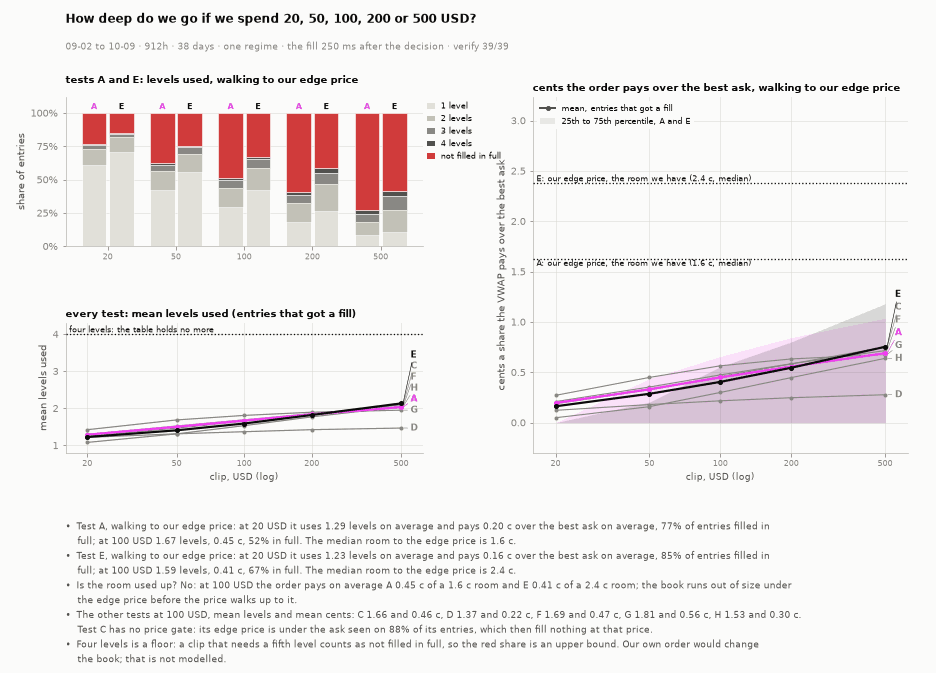

In [7]:
figstyle.show(CAP.howdeep_fig(CAP_EST, CAP_WIN, CAP.notes_howdeep(CAP_EST)), "fig:s2-howdeep", FIGURES)

#### How many dollars sit under our edge price when a test fires?

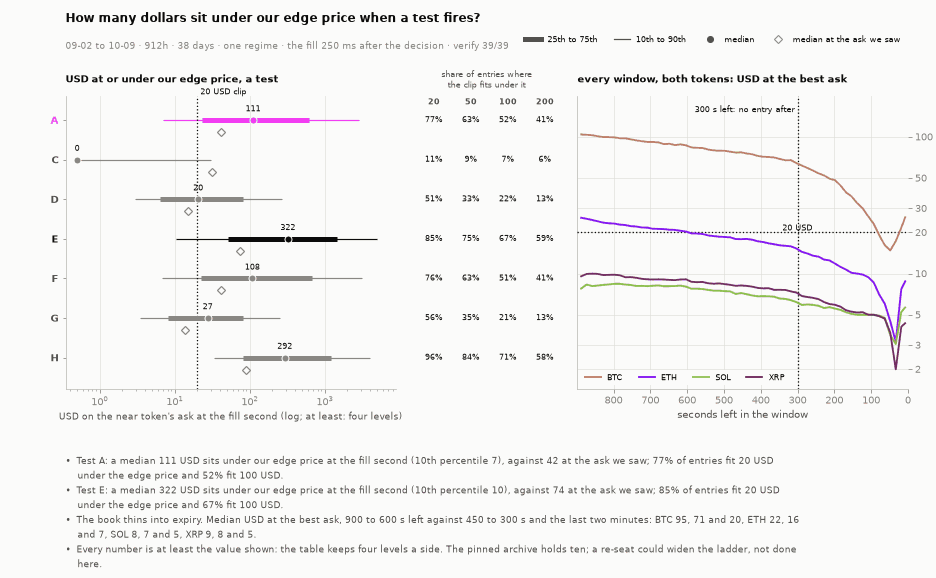

In [8]:
figstyle.show(CAP.underedge_fig(CAP_EST, CAP_DEPTH, CAP_WIN, CAP.notes_underedge(CAP_EST, CAP_DEPTH, CLIP_USD, T_MIN), clip=CLIP_USD, t_min=T_MIN), "fig:s2-underedge", FIGURES)

#### What does each clip earn a day when we pay up to our edge price?

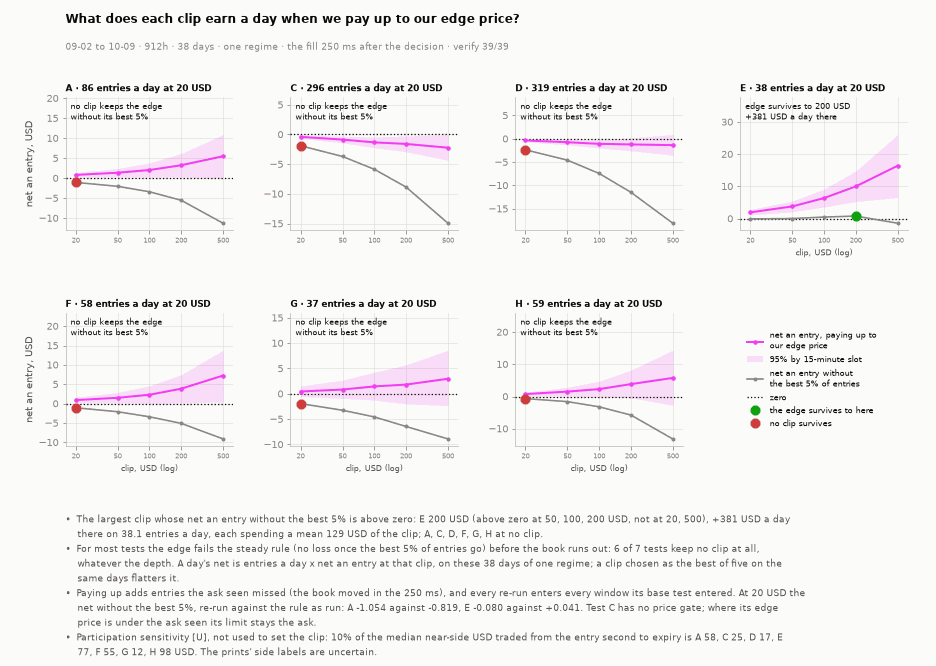

In [9]:
figstyle.show(CAP.earnclip_fig(CAP_EST, CAP_WIN, CAP.notes_earnclip(CAP_EST, len(DAYS))), "fig:s2-earnclip", FIGURES)

In [10]:
display(Markdown(f"**How much each test can buy at its price, one row a test** ({len(DAYS)} days, USD; levels and cents walk to our edge price; cents are the mean over the best ask; "
                 f"the edge column is each test re-run paying up to its edge price)"))
display(HTML(CAP.estimate_table(CAP_EST).to_html(index=False, border=0)))
display(Markdown("- Four levels is a floor: the table keeps four levels a side, so the USD under the edge price and the share filled in full are at least the values shown, "
                 "and a clip that needs a fifth level counts as not filled in full.\n"
                 f"- A participation cap of {CAP.PART:.0%} of the near-side flow after entry is a desk convention: it is printed in the bullets under the clip figure as a "
                 "sensitivity, tagged [U], and does not set the clip."))

**How much each test can buy at its price, one row a test** (38 days, USD; levels and cents walk to our edge price; cents are the mean over the best ask; the edge column is each test re-run paying up to its edge price)

Test,Entries a day,USD at the ask we saw (median entry),"USD under our edge price (median, 10th pct)","At 20 USD: levels used, cents over the ask","At 100 USD: levels used, cents over the ask, filled in full",Largest clip that fills in full for 90% of entries,Largest clip where the edge survives without the best 5%,"What we can do a day, USD (that clip x entries a day)"
A,76.3,42,111 (7),"1.29, 0.20 c","1.67, 0.45 c, 52%",none,none,none
C,296.1,31,0 (0),"1.25, 0.19 c","1.66, 0.46 c, 7%",none,none,none
D,314.1,15,20 (3),"1.22, 0.12 c","1.37, 0.22 c, 22%",none,none,none
E,33.2,74,322 (10),"1.23, 0.16 c","1.59, 0.41 c, 67%",none,200,"7,616"
F,50.5,42,108 (7),"1.30, 0.21 c","1.69, 0.47 c, 51%",none,none,none
G,32.6,14,27 (3),"1.43, 0.27 c","1.81, 0.56 c, 21%",none,none,none
H,55.4,90,292 (33),"1.08, 0.05 c","1.53, 0.30 c, 71%",20,none,none


- Four levels is a floor: the table keeps four levels a side, so the USD under the edge price and the share filled in full are at least the values shown, and a clip that needs a fifth level counts as not filled in full.
- A participation cap of 10% of the near-side flow after entry is a desk convention: it is printed in the bullets under the clip figure as a sensitivity, tagged [U], and does not set the clip.

## S3 · Core result

Seven small studies, one a test, each in the S0 to S5 shape. The same window, the same costs, the same engine; only the gate differs.

### Test A · Momentum and the near token's ASK under fair value: buy the near token

#### A · S0 Summary

In [11]:
LAB = "A"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test A: Momentum and the near token's ASK under fair value: buy the near token.** 2,898 entries over 38 days, win rate 68.3% (Wilson 95% 66.6 to 70.0) against 62.0% to break even on the price paid; the mean win is +7.64 USD and the mean loss -14.53, reward to risk 0.53, profit factor 1.13, so the payoff needs 65.5% wins and gets them. Each trade's own reward to risk averages 0.92 (median 0.42). Without the best 5% of entries the net is -0.819 an entry (95% by 15-minute slot -1.25 to -0.37, 100% of the resamples at or below zero); 225% of the net sits in them: a few wins carry everything. Net +0.620 USD an entry (95% by 15-minute slot +0.13 to +1.11, which clears zero), +1798 USD in all, +3.91% on the dollars risked (the clip is not always spent: a partial fill risks less). First half +0.963 an entry on 1,532, second half +0.237 on 1,366. By coin an entry: BTC +0.52, ETH +1.16, SOL +0.11, XRP +0.53.

#### A · S1 Setup

In [12]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** Momentum and the near token's ASK under fair value: buy the near token: after a burst of |z| at least z_min, when the NEAR token's ask sits more than theta below its driftless fair value, buy the near token at no worse than that ask.

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 19,174 decision seconds pass the gate in 4,222 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 2,898 entries: buy near 2,898.

#### A · S2 Data checks

In [13]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,1357,3613,0.376,668.318,0.710,1.0
ETH,740,3597,0.206,657.647,0.629,1.0
SOL,443,3387,0.131,628.036,0.572,1.0
XRP,358,3153,0.114,596.589,0.500,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### A · S3 Core result

In [14]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),2898,68.323,61.968,0.620,0.134,1.109,1798.172,7.643,-14.526,0.526,1.135,65.524,0.919,0.418,-0.819,225.419
first half (09-02..09-20),1532,69.843,63.401,0.963,0.342,1.600,1474.866,7.270,-13.645,0.533,1.234,65.240,0.929,0.418,-0.360,135.527
second half (09-21..10-09),1366,66.618,60.570,0.237,-0.545,1.059,323.306,8.081,-15.418,0.524,1.046,65.611,0.909,0.418,-1.346,640.157
BTC,1357,74.650,69.414,0.518,-0.161,1.194,702.920,7.316,-19.502,0.375,1.105,72.718,0.455,0.362,-0.560,202.770
ETH,740,68.514,56.650,1.155,0.085,2.267,854.966,8.973,-15.855,0.566,1.231,63.860,0.945,0.459,-0.813,166.827
SOL,443,60.045,55.264,0.113,-0.860,1.132,50.123,6.123,-8.918,0.687,1.032,59.293,1.504,0.596,-1.280,1172.219
XRP,358,54.190,47.674,0.531,-0.708,1.784,190.163,7.955,-8.251,0.964,1.141,50.912,1.905,0.878,-1.194,313.392


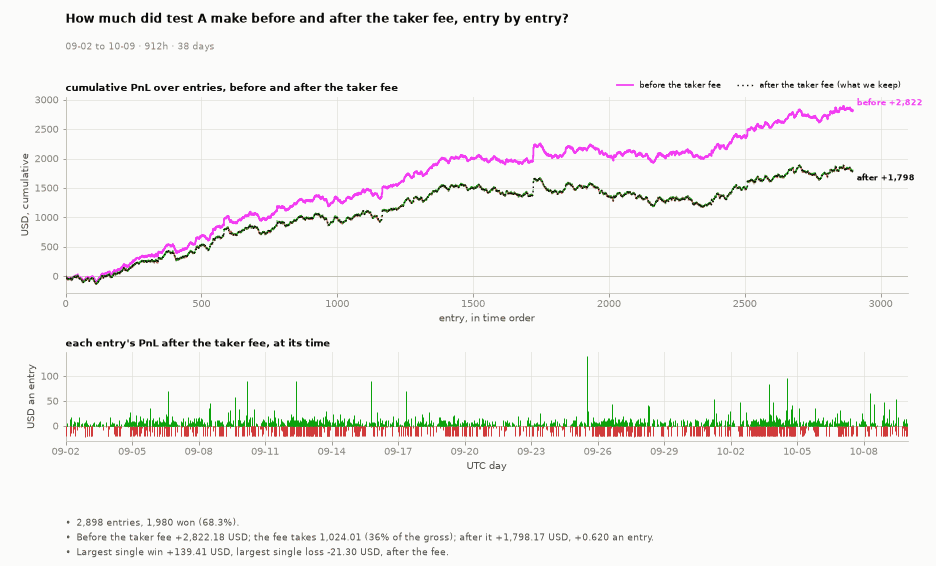

In [15]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-a-equity", FIGURES)

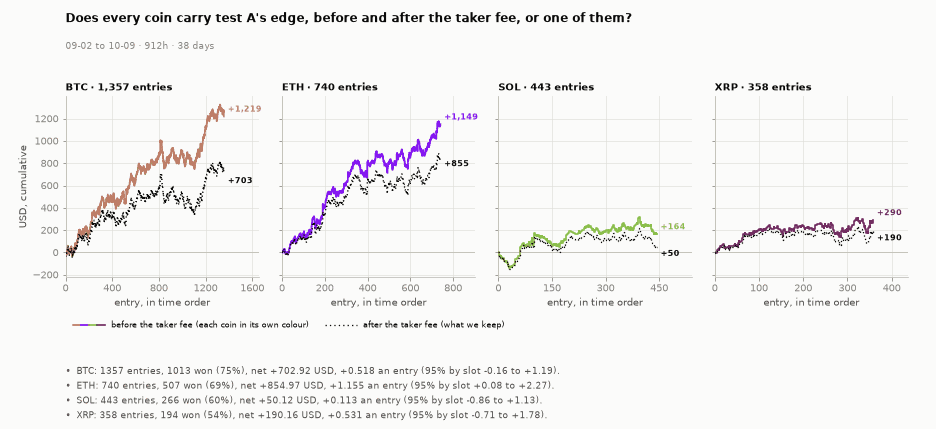

In [16]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-a-coins", FIGURES)

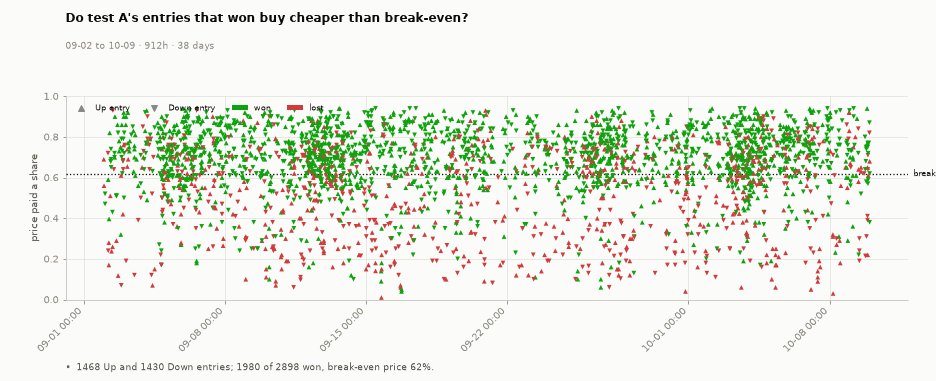

In [17]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-a-entrypx", FIGURES)

#### A · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

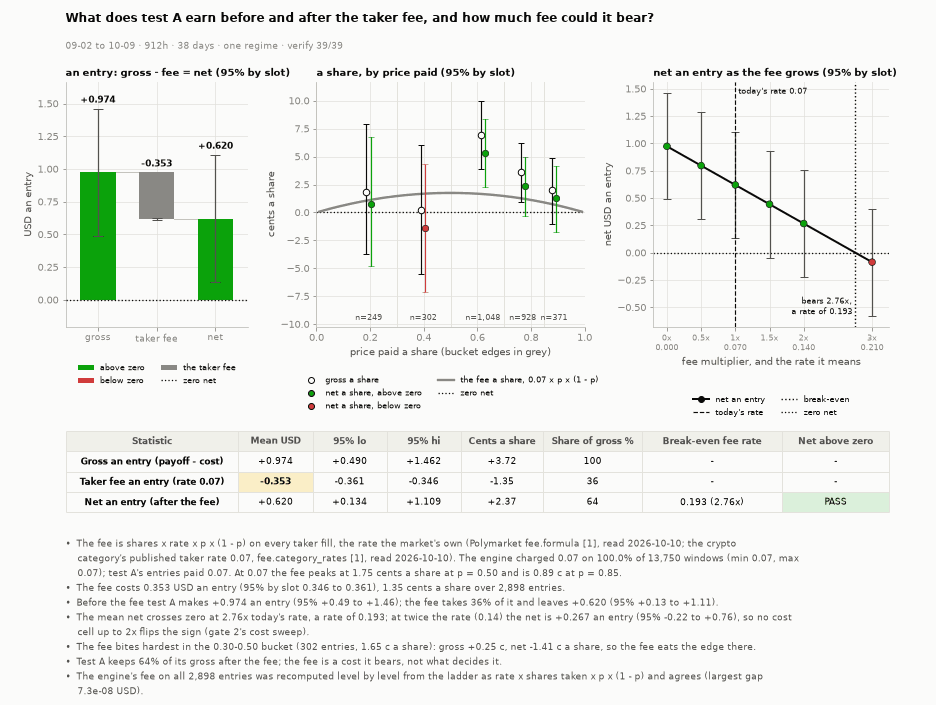

In [18]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

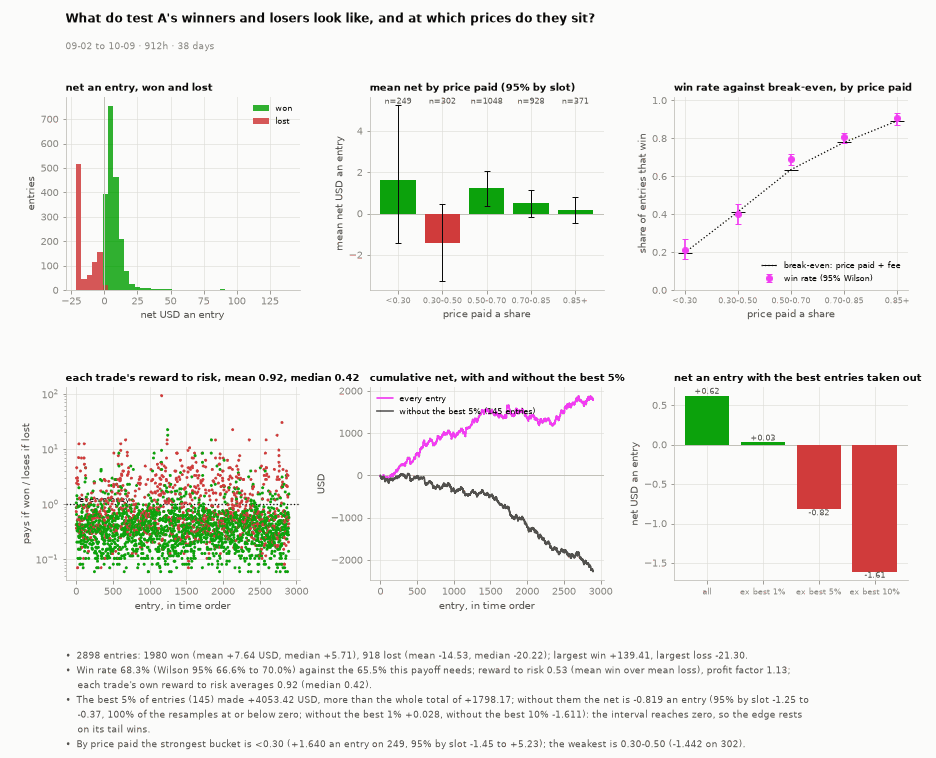

In [19]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-a-winloss", FIGURES)

In [20]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test A** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-25,eth,Up,buy near,127,773,0.100,155.99,15.599,0.983,True,139.408
2026-10-04,eth,Down,buy near,520,380,0.170,117.64,19.999,1.162,True,96.479
2026-09-15,btc,Up,buy near,379,521,0.180,111.11,20.000,1.148,True,89.962
2026-09-12,eth,Up,buy near,545,355,0.180,111.11,20.000,1.148,True,89.962
2026-09-10,sol,Up,buy near,341,559,0.100,100.00,10.000,0.630,True,89.370
2026-09-25,btc,Up,buy near,195,705,0.140,100.00,14.000,0.843,True,85.157
2026-10-03,eth,Up,buy near,137,763,0.190,105.52,19.999,1.135,True,84.387
2026-09-06,sol,Up,buy near,152,748,0.190,87.92,16.705,0.947,True,70.268
2026-09-17,eth,Down,buy near,552,348,0.220,90.90,19.998,1.092,True,69.810
2026-10-08,eth,Up,buy near,407,493,0.232,86.37,19.998,1.076,True,65.296


**The 10 worst entries of test A**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-02,eth,Down,buy near,591,309,0.070,285.71,20.000,1.302,False,-21.302
2026-09-27,btc,Down,buy near,585,315,0.103,193.99,19.999,1.255,False,-21.254
2026-09-27,eth,Down,buy near,567,333,0.190,105.26,19.999,1.134,False,-21.133
2026-09-11,xrp,Up,buy near,460,440,0.210,95.23,19.998,1.106,False,-21.104
2026-09-27,eth,Down,buy near,585,315,0.220,90.90,19.998,1.092,False,-21.090
2026-09-30,eth,Down,buy near,545,355,0.224,89.13,20.000,1.086,False,-21.086
2026-09-30,btc,Up,buy near,189,711,0.240,83.33,19.999,1.064,False,-21.063
2026-10-02,eth,Down,buy near,508,392,0.240,83.33,19.999,1.064,False,-21.063
2026-10-07,eth,Down,buy near,316,584,0.250,80.00,20.000,1.050,False,-21.050
2026-10-03,btc,Down,buy near,549,351,0.250,80.00,20.000,1.050,False,-21.050


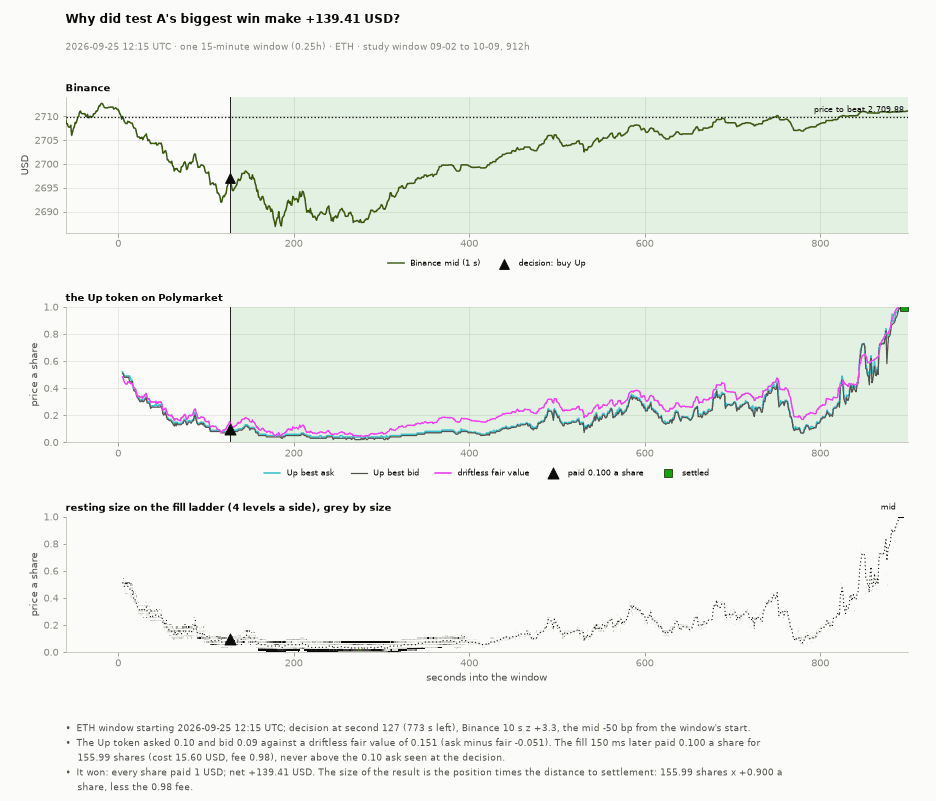

**Fill ladder at second 127 + 150 ms, ETH Up token: a buy of 20 USD of Up at no worse than the 0.10 ask seen at the decision; fair value 0.151; took 155.99 shares for 15.60 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,71.00,0.09,0.10,155.99,155.99,15.599
2,108.42,0.08,0.11,40.00,0.00,0.000
3,329.36,0.07,0.12,137.00,0.00,0.000
4,199.66,0.06,0.13,190.00,0.00,0.000


In [21]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-a-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

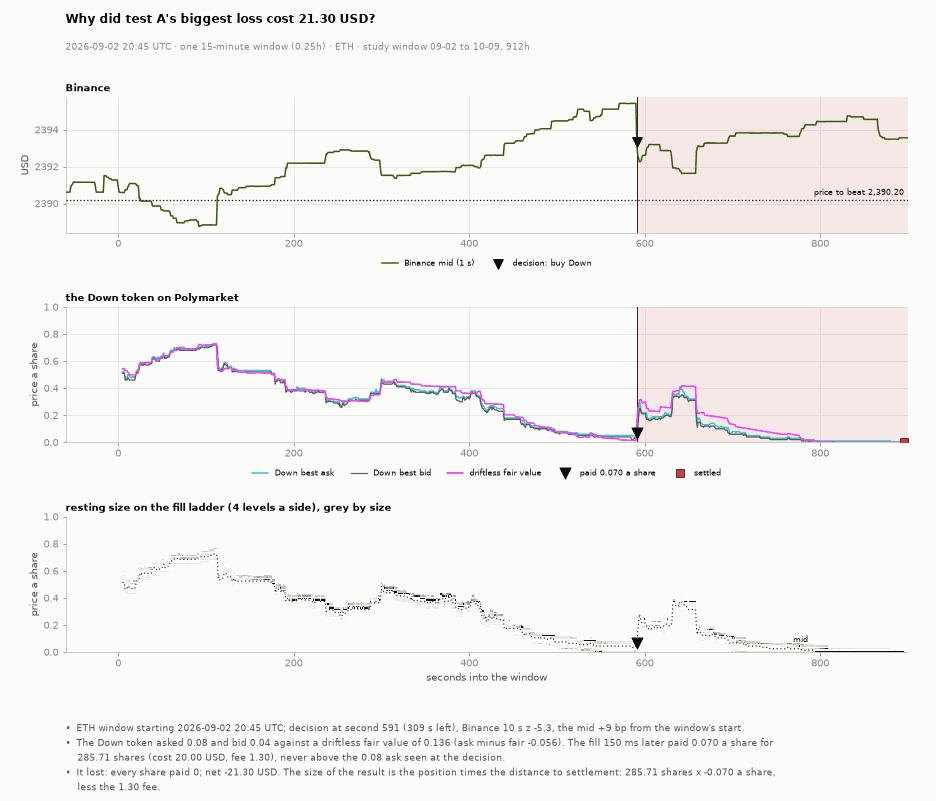

**Fill ladder at second 591 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.08 ask seen at the decision; fair value 0.136; took 285.71 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,55.38,0.04,0.07,456.0,285.71,19.9997
2,20.00,0.03,0.08,15.0,0.00,0.0000
3,26.00,0.02,0.11,5.0,0.00,0.0000
4,132.84,0.01,0.12,5.0,0.00,0.0000


In [22]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-a-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### A · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

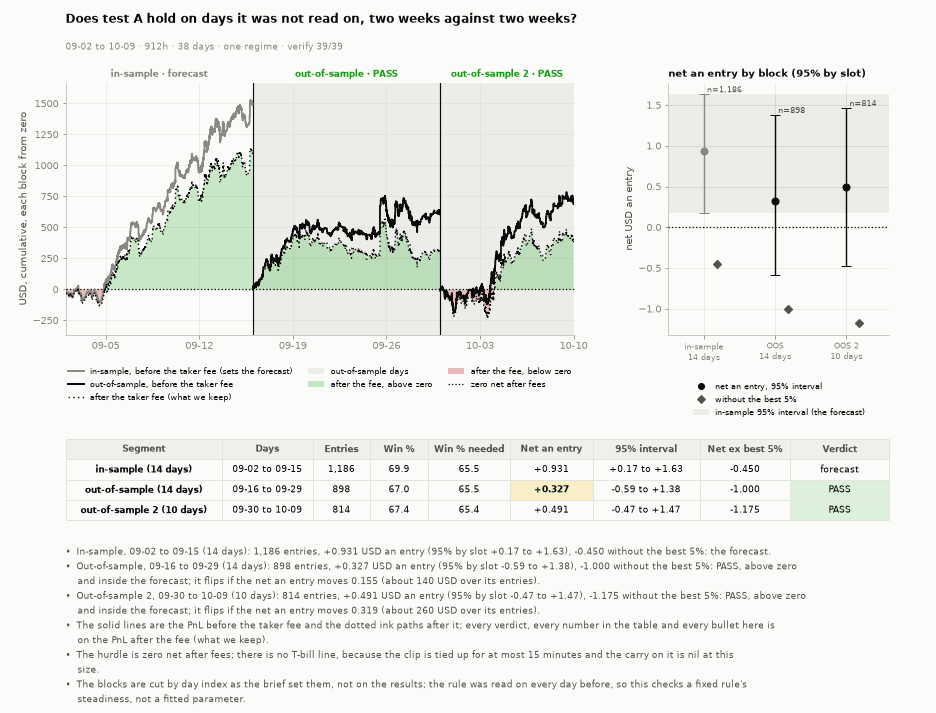

In [23]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

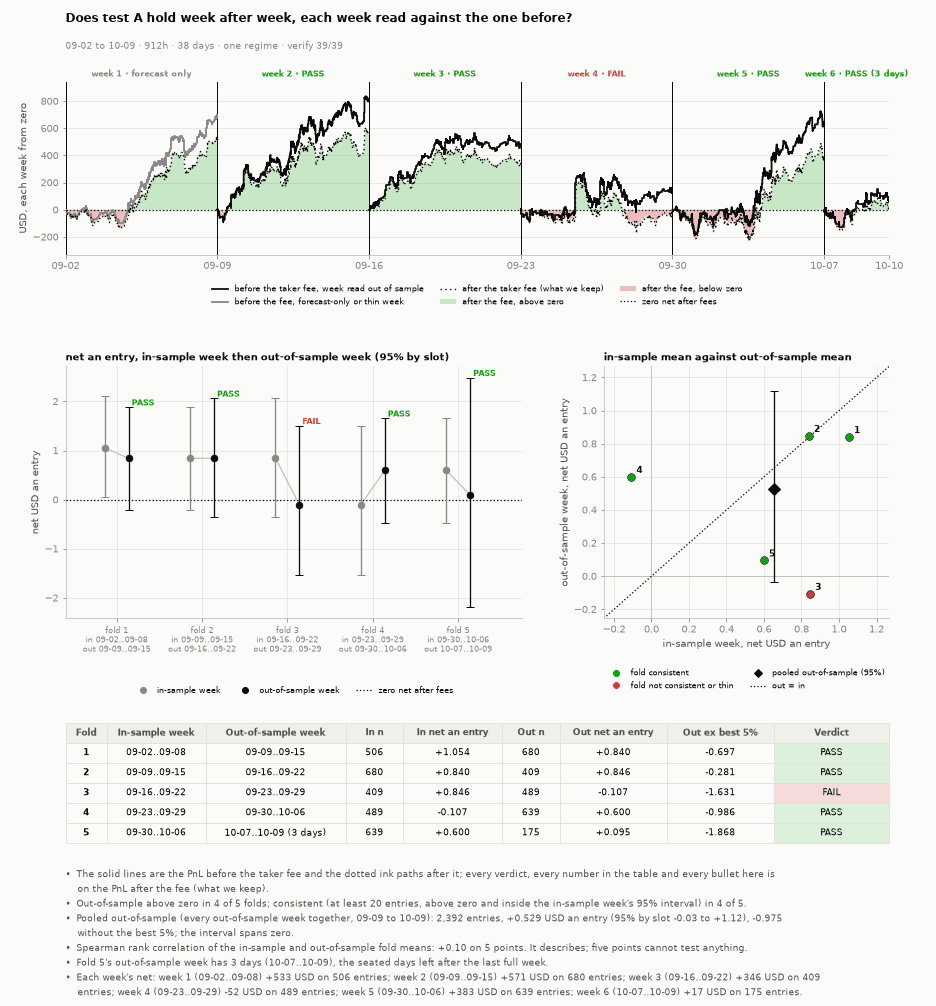

In [24]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

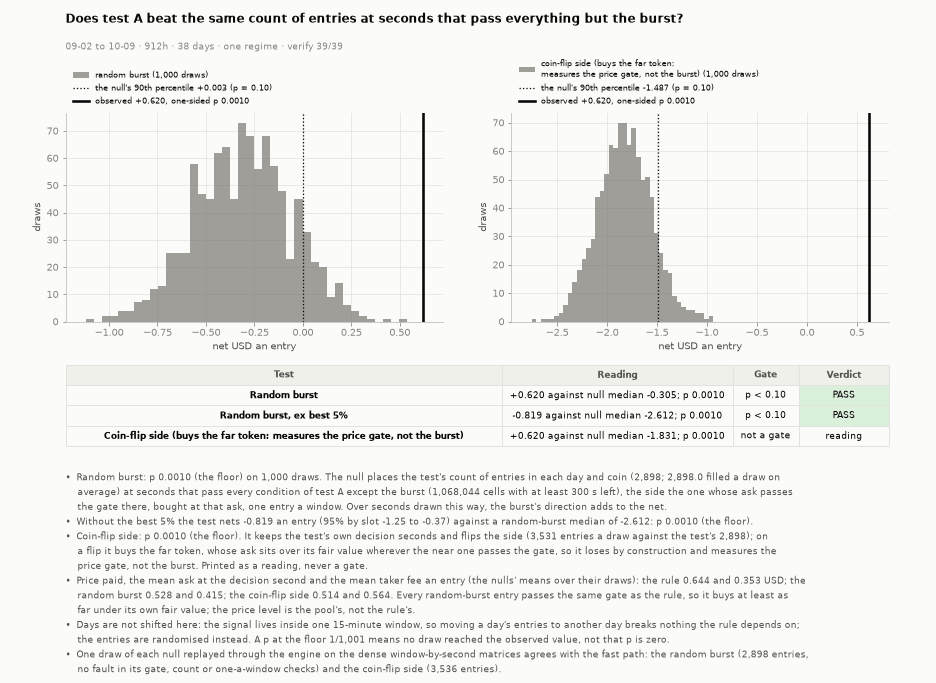

In [25]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test C · Momentum only: buy the near token with no price gate

#### C · S0 Summary

In [26]:
LAB = "C"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test C: Momentum only: buy the near token with no price gate.** 11,250 entries over 38 days, win rate 64.0% (Wilson 95% 63.1 to 64.9) against 61.5% to break even on the price paid; the mean win is +8.03 USD and the mean loss -15.58, reward to risk 0.52, profit factor 0.92, so the payoff needs 66.0% wins and does not get them. Each trade's own reward to risk averages 0.76 (median 0.50). Without the best 5% of entries the net is -1.912 an entry (95% by 15-minute slot -2.19 to -1.61, 100% of the resamples at or below zero). Net -0.471 USD an entry (95% by 15-minute slot -0.75 to -0.17, which is below zero), -5300 USD in all, -2.96% on the dollars risked (the clip is not always spent: a partial fill risks less). First half -0.405 an entry on 5,752, second half -0.540 on 5,498. By coin an entry: BTC -0.33, ETH -0.53, SOL -0.36, XRP -0.69.

#### C · S1 Setup

In [27]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** Momentum only: buy the near token with no price gate: after the burst, buy the near token at its ask whatever the book says against fair value (is the price gate necessary?).

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 142,368 decision seconds pass the gate in 11,488 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 11,250 entries: buy near 11,250.

#### C · S2 Data checks

In [28]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,3011,3613,0.833,711.500,0.644,1.0
ETH,2911,3597,0.809,710.490,0.639,1.0
SOL,2761,3387,0.815,713.449,0.643,1.0
XRP,2567,3153,0.814,714.525,0.642,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### C · S3 Core result

In [29]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),11250,63.982,61.522,-0.471,-0.754,-0.165,-5300.331,8.033,-15.578,0.516,0.916,65.978,0.758,0.502,-1.912,NaN
first half (09-02..09-20),5752,64.082,61.736,-0.405,-0.798,0.019,-2332.201,7.915,-15.251,0.519,0.926,65.832,0.732,0.502,-1.815,NaN
second half (09-21..10-09),5498,63.878,61.311,-0.540,-0.969,-0.142,-2968.129,8.157,-15.918,0.512,0.906,66.120,0.786,0.502,-2.013,NaN
BTC,3011,65.261,61.289,-0.330,-0.883,0.193,-994.621,9.690,-19.155,0.506,0.950,66.406,0.657,0.502,-1.893,NaN
ETH,2911,63.689,60.293,-0.531,-1.044,-0.026,-1546.882,8.440,-16.267,0.519,0.910,65.840,0.770,0.502,-2.090,NaN
SOL,2761,63.999,62.602,-0.356,-0.807,0.068,-983.608,6.839,-13.147,0.520,0.925,65.781,0.778,0.480,-1.630,NaN
XRP,2567,62.797,62.431,-0.692,-1.178,-0.211,-1775.219,6.854,-13.428,0.510,0.862,66.207,0.843,0.480,-2.004,NaN


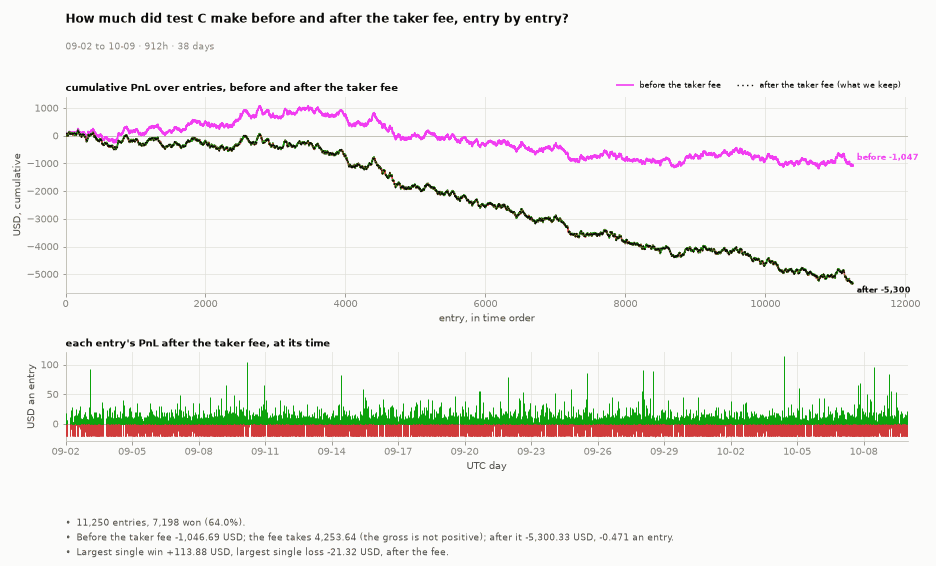

In [30]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-c-equity", FIGURES)

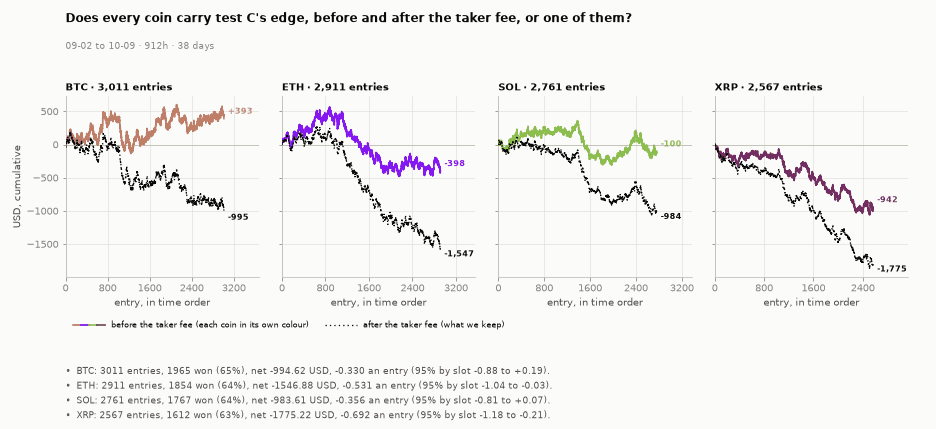

In [31]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-c-coins", FIGURES)

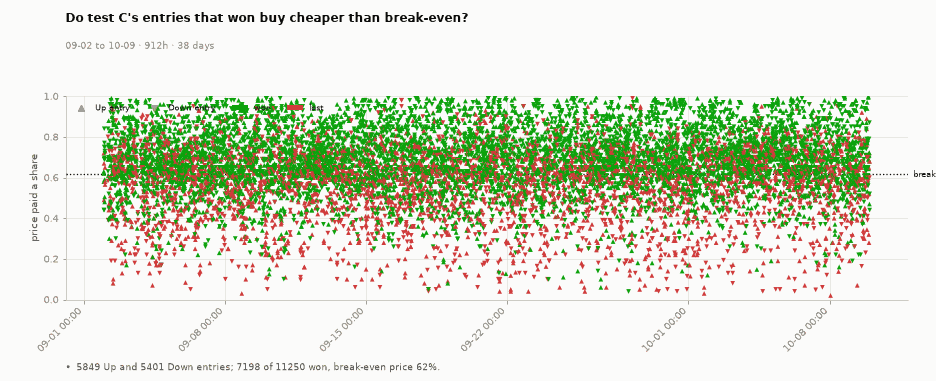

In [32]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-c-entrypx", FIGURES)

#### C · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

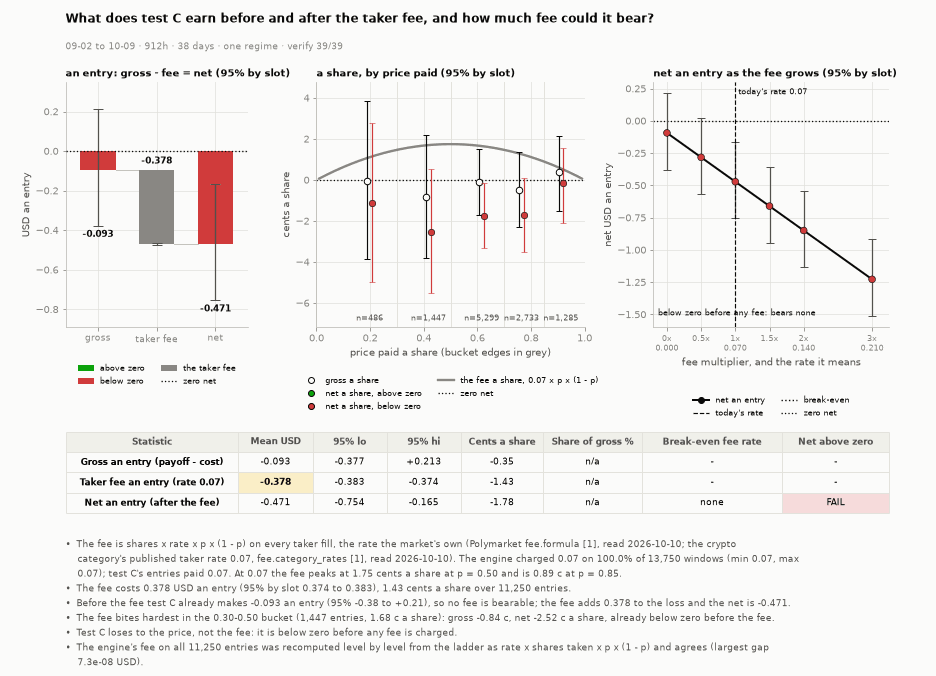

In [33]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

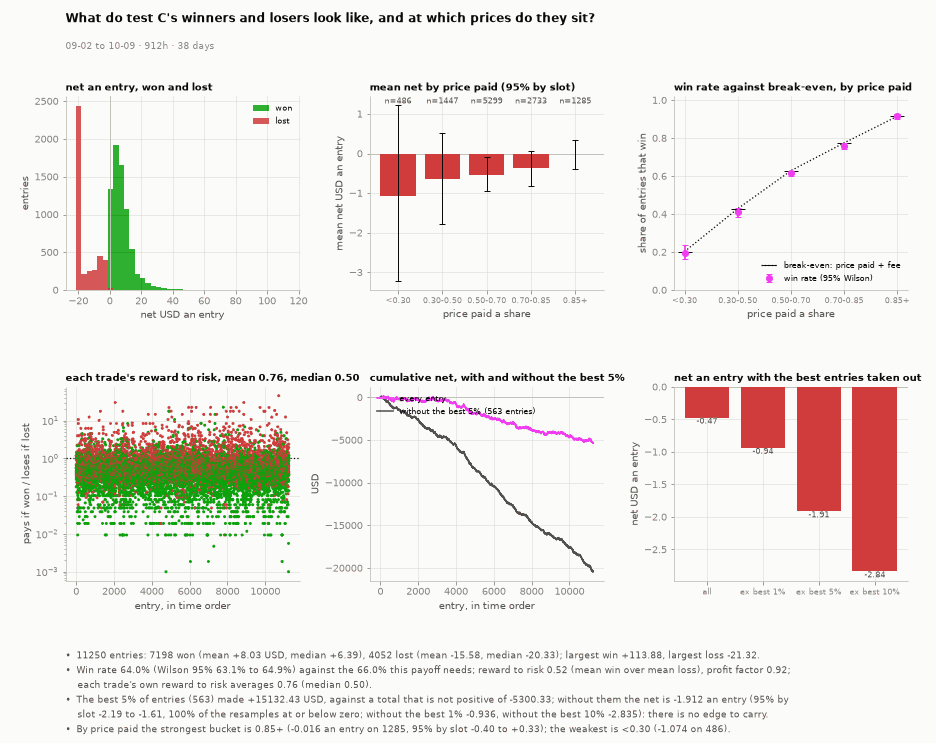

In [34]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-c-winloss", FIGURES)

In [35]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test C** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-04,sol,Up,buy near,591,309,0.148,135.07,19.999,1.193,True,113.878
2026-09-10,sol,Up,buy near,336,564,0.125,120.00,15.050,0.921,True,104.029
2026-10-08,eth,Up,buy near,410,490,0.160,116.33,18.613,1.094,True,96.623
2026-09-03,btc,Up,buy near,465,435,0.170,113.92,19.366,1.125,True,93.428
2026-09-28,eth,Down,buy near,460,440,0.040,94.19,3.740,0.251,True,90.198
2026-09-28,btc,Up,buy near,442,458,0.181,110.78,19.998,1.147,True,89.635
2026-09-25,btc,Up,buy near,195,705,0.140,100.00,14.000,0.843,True,85.157
2026-10-09,xrp,Down,buy near,447,453,0.190,105.26,19.999,1.134,True,84.127
2026-09-14,xrp,Down,buy near,385,515,0.160,100.14,16.022,0.942,True,83.175
2026-09-21,xrp,Up,buy near,430,470,0.127,90.89,11.536,0.705,True,78.649


**The 10 worst entries of test C**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-01,btc,Up,buy near,489,411,0.060,333.33,20.000,1.316,False,-21.316
2026-09-28,eth,Up,buy near,394,506,0.100,199.99,19.999,1.260,False,-21.259
2026-09-29,sol,Up,buy near,433,467,0.119,168.66,19.999,1.234,False,-21.233
2026-09-20,btc,Up,buy near,374,526,0.120,166.66,19.999,1.232,False,-21.231
2026-09-28,btc,Down,buy near,597,303,0.130,153.84,19.999,1.218,False,-21.217
2026-09-21,btc,Up,buy near,397,503,0.140,142.85,19.999,1.204,False,-21.203
2026-10-01,btc,Down,buy near,526,374,0.140,142.85,19.999,1.204,False,-21.203
2026-09-18,eth,Down,buy near,385,515,0.155,128.93,19.999,1.183,False,-21.181
2026-09-23,eth,Up,buy near,375,525,0.163,122.94,20.000,1.172,False,-21.172
2026-09-23,btc,Down,buy near,188,712,0.164,121.70,19.999,1.170,False,-21.169


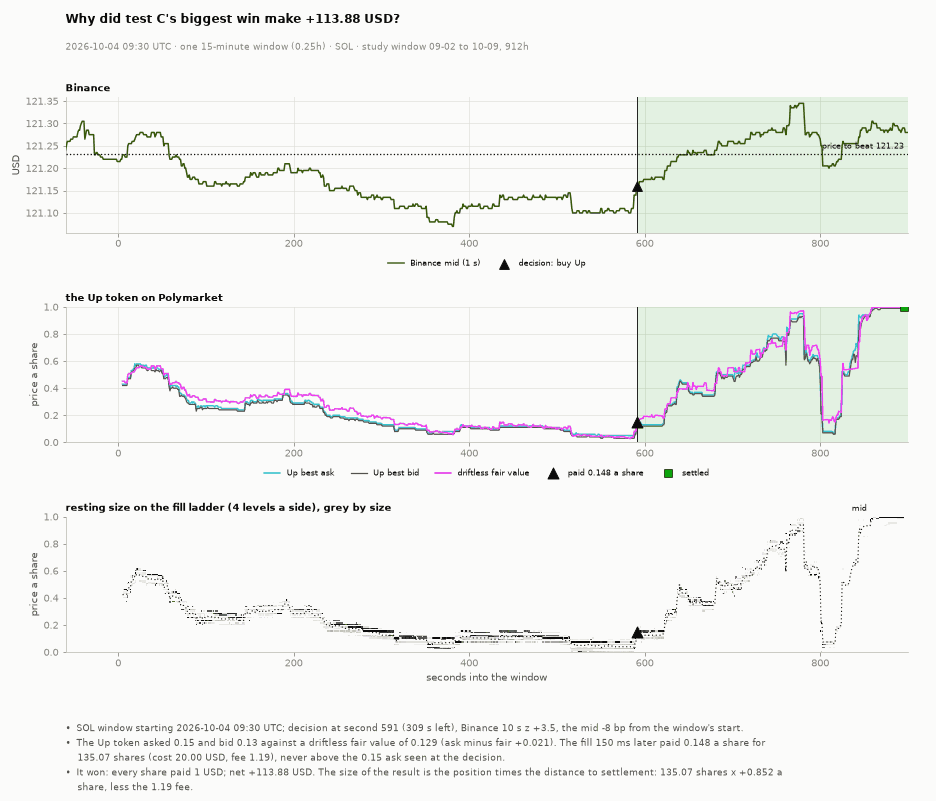

**Fill ladder at second 591 + 150 ms, SOL Up token: a buy of 20 USD of Up at no worse than the 0.15 ask seen at the decision; fair value 0.129; took 135.07 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,20.00,0.13,0.14,26.12,26.12,3.6568
2,8.34,0.12,0.15,580.13,108.95,16.3425
3,9.10,0.11,0.16,360.00,0.00,0.0000
4,97.00,0.09,0.19,30.00,0.00,0.0000


In [36]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-c-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

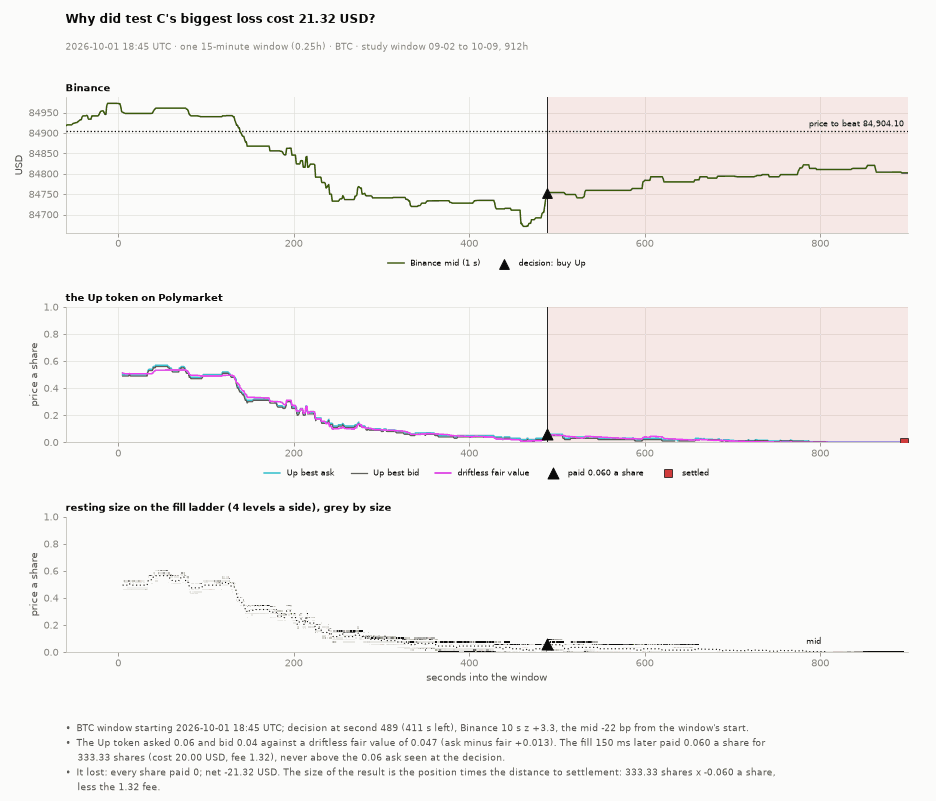

**Fill ladder at second 489 + 150 ms, BTC Up token: a buy of 20 USD of Up at no worse than the 0.06 ask seen at the decision; fair value 0.047; took 333.33 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,210.0000,0.05,0.06,337.9000,333.33,19.9998
2,277.0000,0.04,0.07,259.2800,0.00,0.0000
3,8858.3301,0.03,0.08,2534.4099,0.00,0.0000
4,7817.0000,0.02,0.09,28194.0000,0.00,0.0000


In [37]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-c-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### C · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

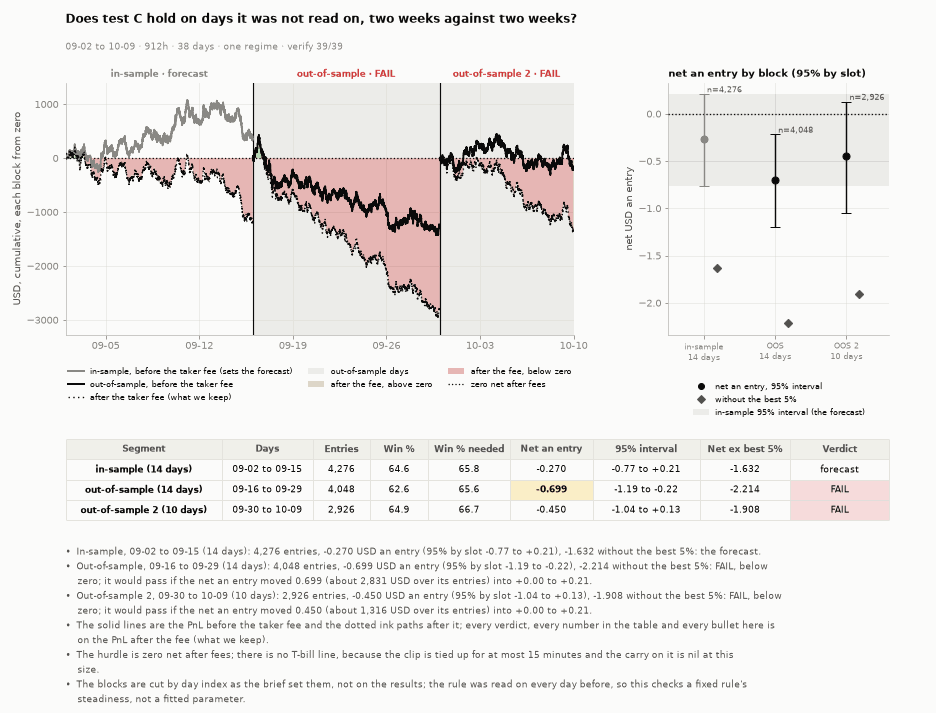

In [38]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

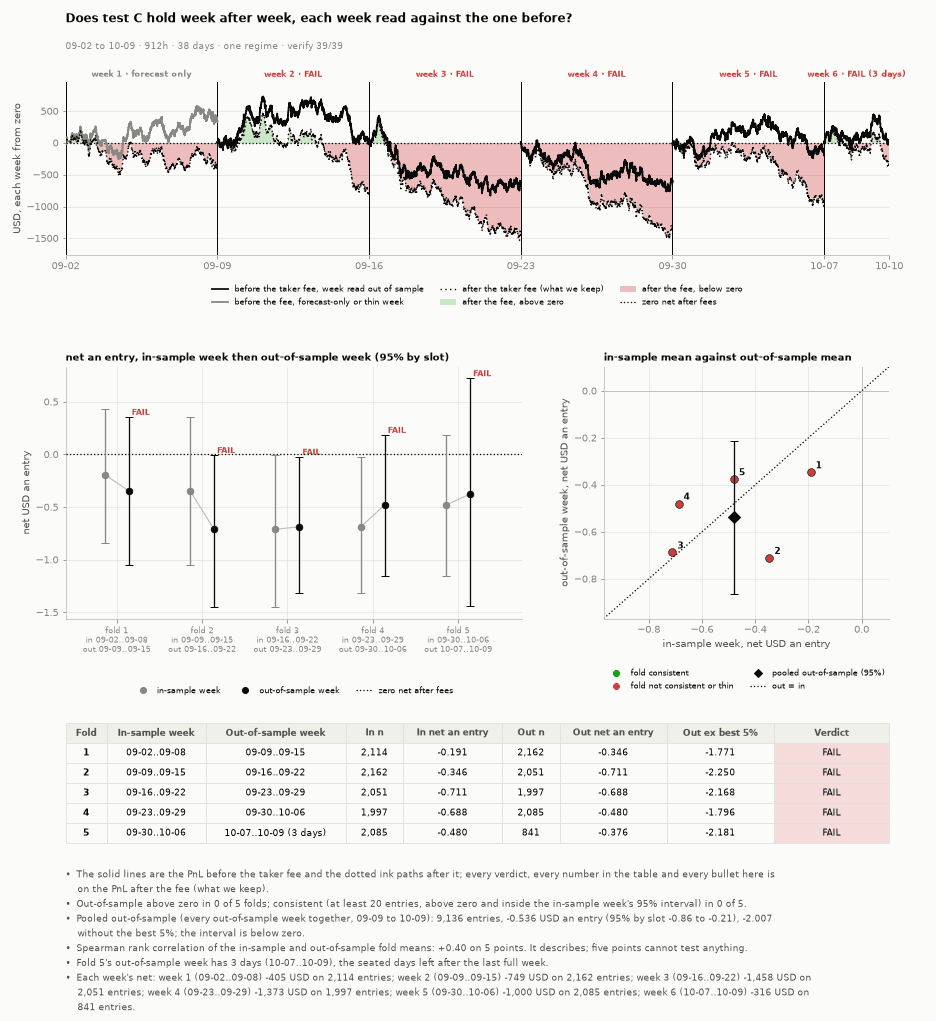

In [39]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

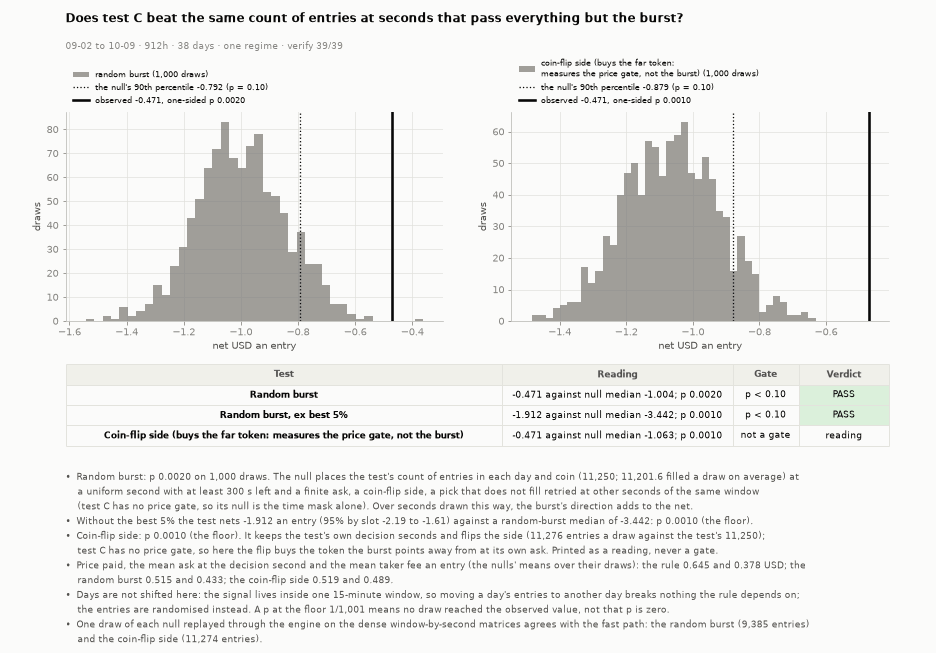

In [40]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test D · The price gate without momentum: buy the near token

#### D · S0 Summary

In [41]:
LAB = "D"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test D: The price gate without momentum: buy the near token.** 11,937 entries over 38 days, win rate 47.1% (Wilson 95% 46.2 to 48.0) against 46.1% to break even on the price paid; the mean win is +13.08 USD and the mean loss -12.30, reward to risk 1.06, profit factor 0.95, so the payoff needs 48.5% wins and does not get them. Each trade's own reward to risk averages 1.44 (median 1.14). Without the best 5% of entries the net is -2.274 an entry (95% by 15-minute slot -2.58 to -1.97, 100% of the resamples at or below zero). Net -0.357 USD an entry (95% by 15-minute slot -0.68 to -0.04, which is below zero), -4261 USD in all, -2.79% on the dollars risked (the clip is not always spent: a partial fill risks less). First half -0.142 an entry on 6,061, second half -0.578 on 5,876. By coin an entry: BTC -0.58, ETH -0.22, SOL -0.34, XRP -0.26.

#### D · S1 Setup

In [42]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** The price gate without momentum: buy the near token: test A's gate with no burst required: when the near token's ask sits more than theta below its fair value, buy it (is the momentum necessary?).

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 1,068,044 decision seconds pass the gate in 12,664 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 11,937 entries: buy near 11,937.

#### D · S2 Data checks

In [43]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,3353,3613,0.928,770.922,0.549,1.0
ETH,3143,3597,0.874,750.933,0.463,1.0
SOL,2889,3387,0.853,717.642,0.427,1.0
XRP,2552,3153,0.809,702.439,0.395,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### D · S3 Core result

In [44]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),11937,47.055,46.097,-0.357,-0.679,-0.035,-4261.122,13.081,-12.300,1.063,0.945,48.462,1.444,1.140,-2.274,NaN
first half (09-02..09-20),6061,48.358,47.059,-0.142,-0.560,0.296,-862.499,12.399,-11.887,1.043,0.977,48.944,1.389,1.140,-2.006,NaN
second half (09-21..10-09),5876,45.711,45.206,-0.578,-1.029,-0.100,-3398.623,13.825,-12.707,1.088,0.916,47.891,1.501,1.140,-2.554,NaN
BTC,3353,55.771,52.157,-0.579,-1.224,0.046,-1941.091,14.343,-19.394,0.740,0.933,57.487,0.946,0.732,-2.596,NaN
ETH,3143,47.980,44.285,-0.215,-0.873,0.420,-676.715,16.089,-15.253,1.055,0.973,48.667,1.405,1.140,-2.325,NaN
SOL,2889,42.714,42.784,-0.338,-0.770,0.078,-977.398,9.286,-7.514,1.236,0.921,44.727,1.637,1.399,-1.935,NaN
XRP,2552,39.381,39.197,-0.261,-0.734,0.196,-665.917,10.882,-7.500,1.451,0.943,40.800,1.929,1.659,-1.999,NaN


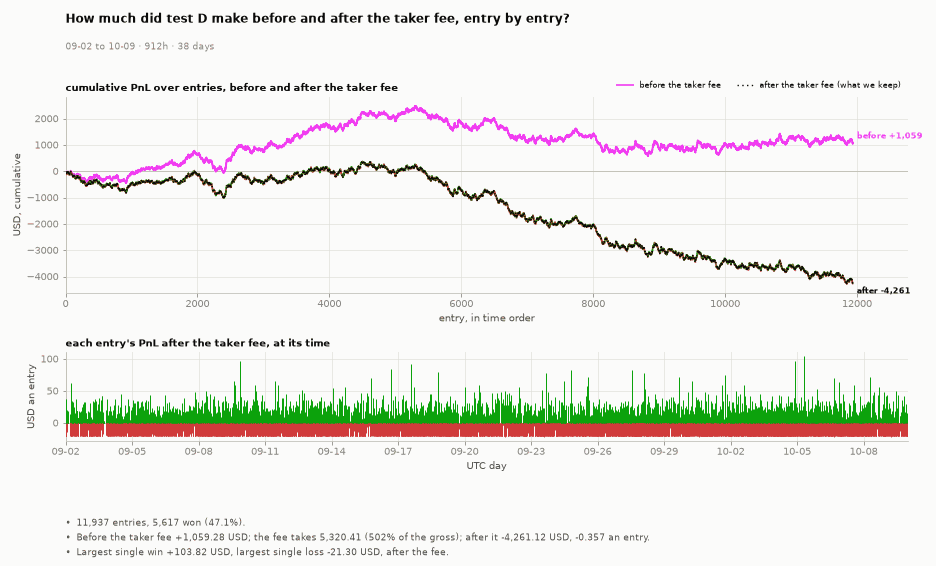

In [45]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-d-equity", FIGURES)

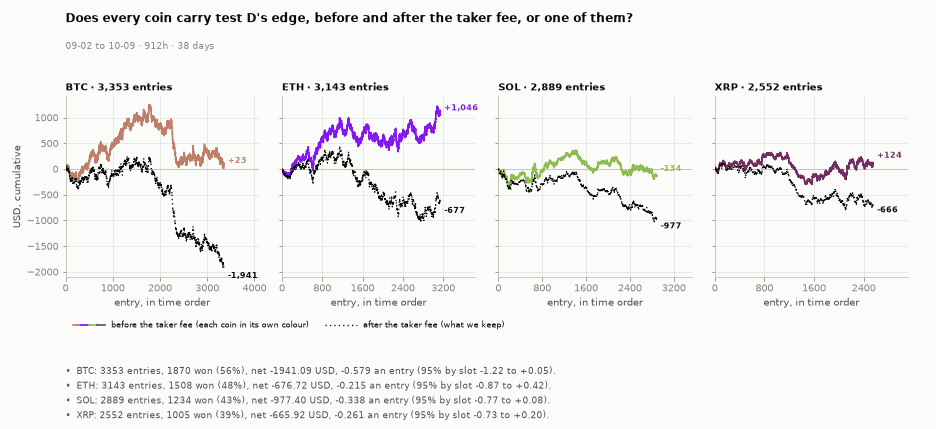

In [46]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-d-coins", FIGURES)

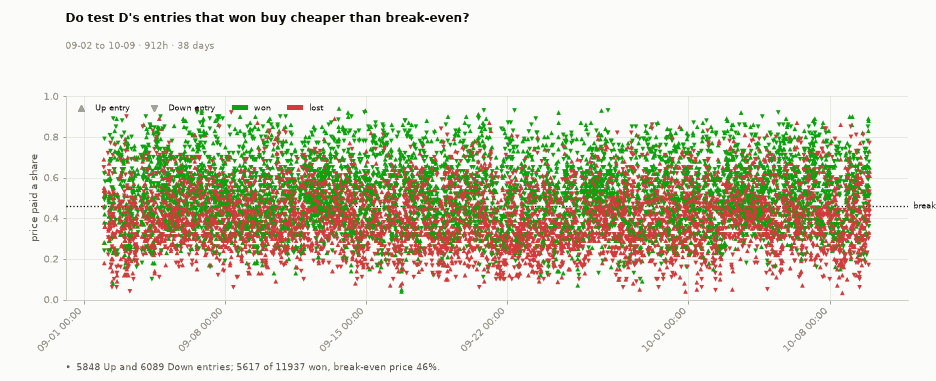

In [47]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-d-entrypx", FIGURES)

#### D · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

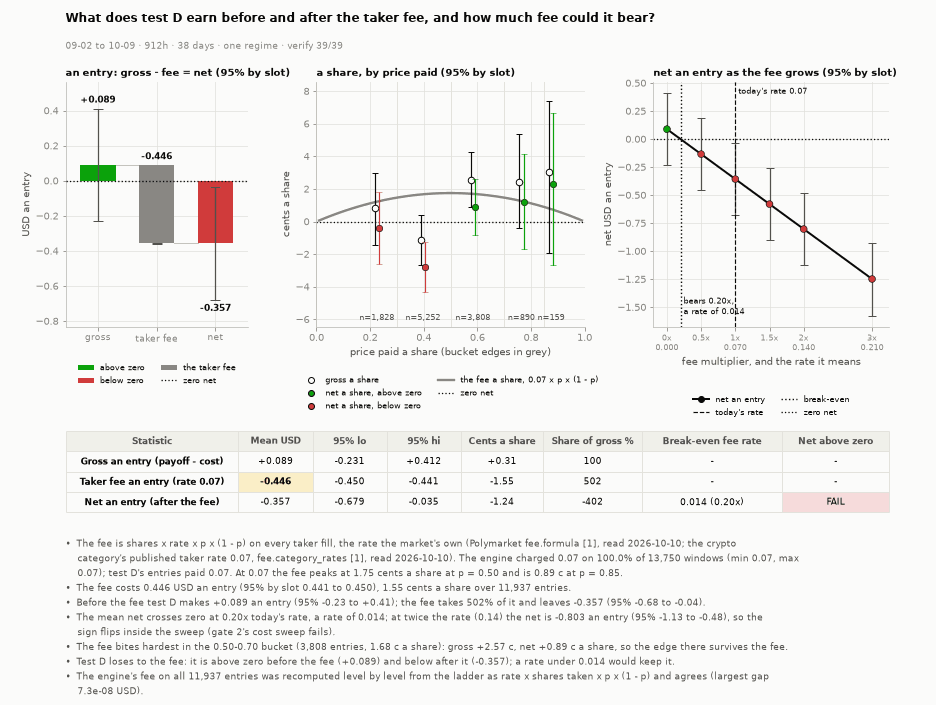

In [48]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

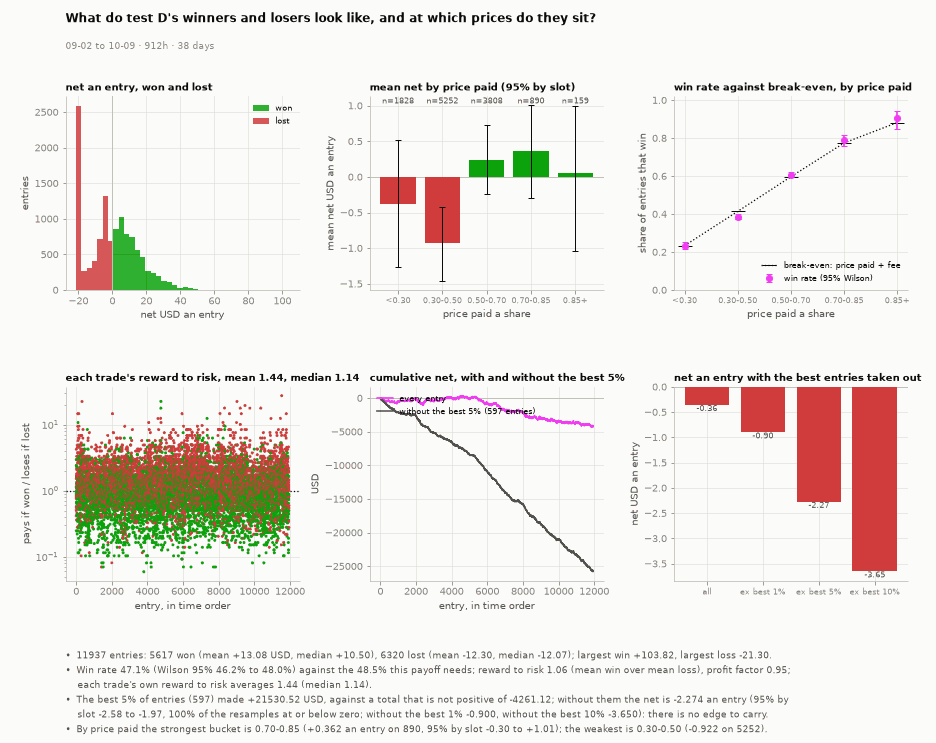

In [49]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-d-winloss", FIGURES)

In [50]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test D** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-05,btc,Down,buy near,133,767,0.160,125.00,20.000,1.176,True,103.824
2026-10-04,btc,Down,buy near,123,777,0.170,117.64,19.999,1.162,True,96.479
2026-09-09,btc,Up,buy near,364,536,0.170,117.64,19.999,1.162,True,96.479
2026-09-17,btc,Up,buy near,356,544,0.176,113.83,19.999,1.154,True,92.677
2026-09-16,btc,Up,buy near,594,306,0.190,105.26,19.999,1.134,True,84.127
2026-09-24,eth,Up,buy near,496,404,0.130,96.00,12.480,0.760,True,82.760
2026-09-27,xrp,Down,buy near,285,615,0.160,99.17,15.867,0.933,True,82.370
2026-09-18,btc,Down,buy near,593,307,0.200,99.99,19.998,1.120,True,78.872
2026-09-28,btc,Up,buy near,506,394,0.203,98.57,20.000,1.116,True,77.455
2026-09-23,eth,Up,buy near,166,734,0.134,90.00,12.100,0.733,True,77.167


**The 10 worst entries of test D**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-06,btc,Up,buy near,545,355,0.07,285.71,20.000,1.302,False,-21.302
2026-09-21,btc,Down,buy near,479,421,0.10,199.99,19.999,1.260,False,-21.259
2026-09-23,btc,Up,buy near,436,464,0.11,181.81,19.999,1.246,False,-21.245
2026-09-30,btc,Up,buy near,545,355,0.11,181.81,19.999,1.246,False,-21.245
2026-10-09,eth,Down,buy near,289,611,0.12,166.66,19.999,1.232,False,-21.231
2026-10-05,btc,Down,buy near,235,665,0.13,153.84,19.999,1.218,False,-21.217
2026-09-21,btc,Up,buy near,439,461,0.13,153.84,19.999,1.218,False,-21.217
2026-09-21,btc,Up,buy near,551,349,0.14,142.85,19.999,1.204,False,-21.203
2026-10-06,btc,Up,buy near,477,423,0.14,142.85,19.999,1.204,False,-21.203
2026-10-02,btc,Down,buy near,230,670,0.16,125.00,20.000,1.176,False,-21.176


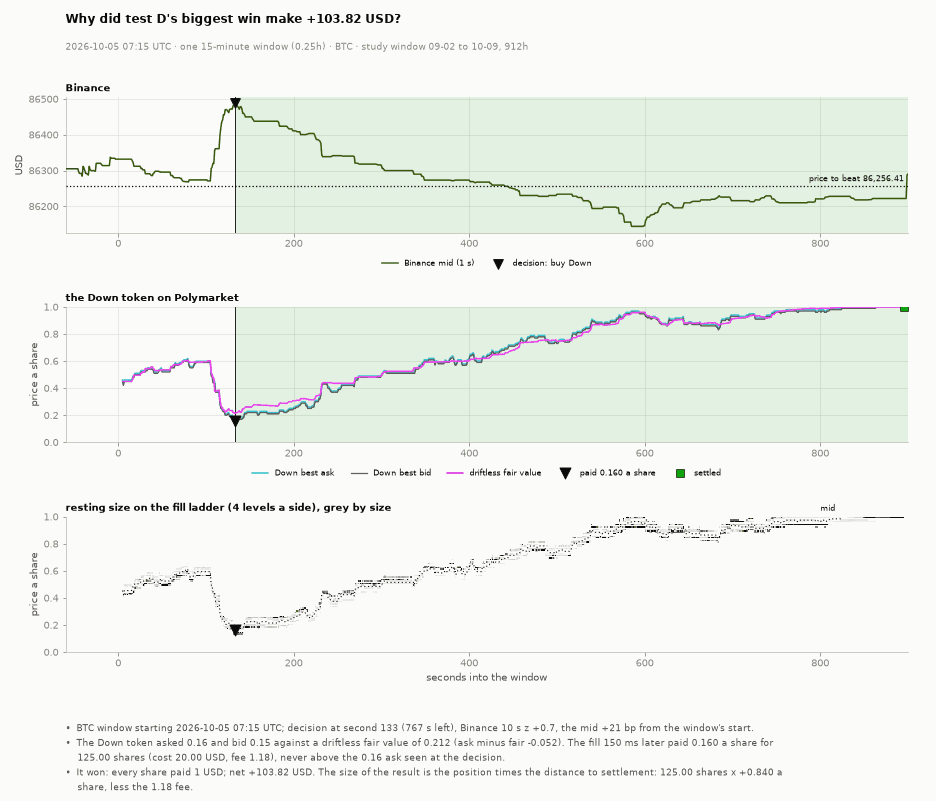

**Fill ladder at second 133 + 150 ms, BTC Down token: a buy of 20 USD of Down at no worse than the 0.16 ask seen at the decision; fair value 0.212; took 124.99 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,2146.4399,0.15,0.16,908.64,124.99,19.9984
2,11319.3496,0.14,0.17,528.97,0.00,0.0000
3,2422.7000,0.13,0.18,469.00,0.00,0.0000
4,3188.3401,0.12,0.19,496.00,0.00,0.0000


In [51]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-d-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

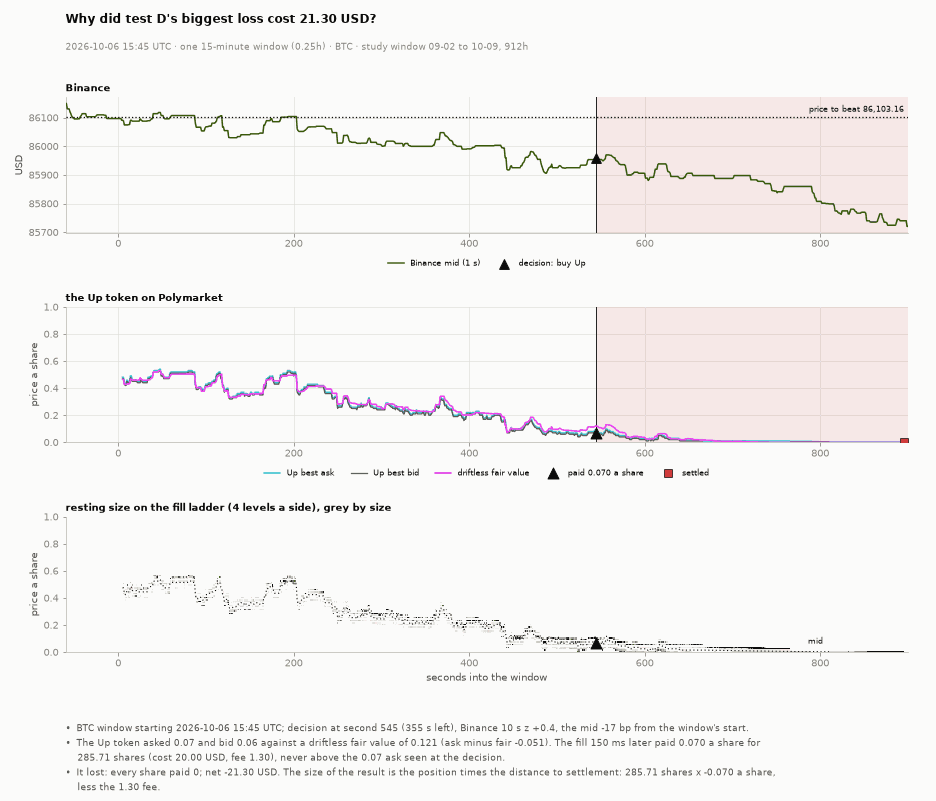

**Fill ladder at second 545 + 150 ms, BTC Up token: a buy of 20 USD of Up at no worse than the 0.07 ask seen at the decision; fair value 0.121; took 285.71 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,458.1300,0.06,0.07,324.4900,285.71,19.9997
2,1307.3800,0.05,0.08,229.0000,0.00,0.0000
3,3598.7100,0.04,0.09,870.0000,0.00,0.0000
4,6147.2002,0.03,0.10,8133.0801,0.00,0.0000


In [52]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-d-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### D · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

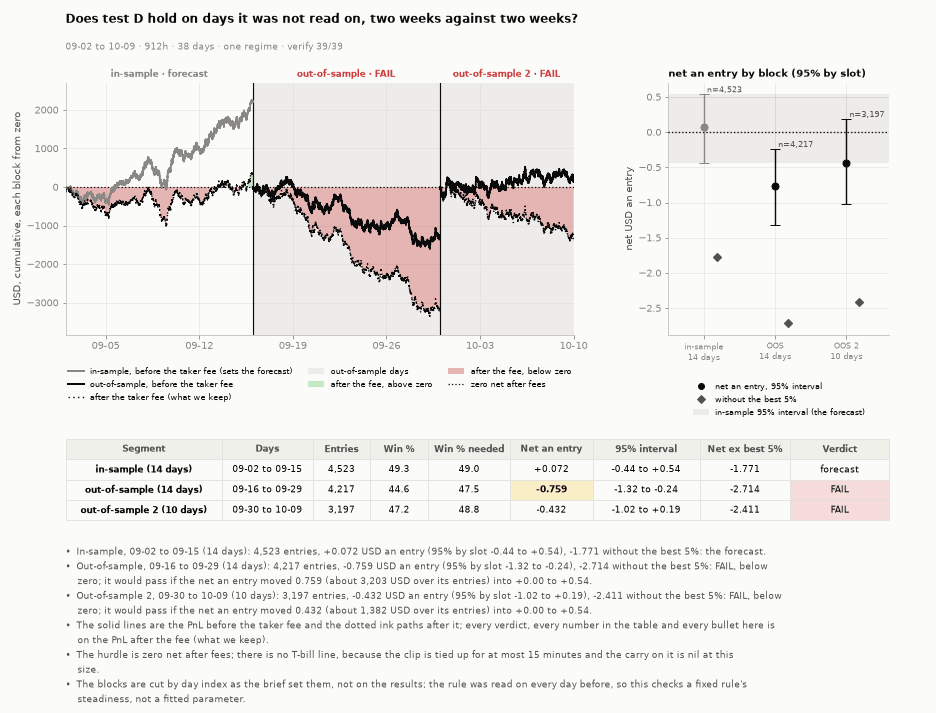

In [53]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

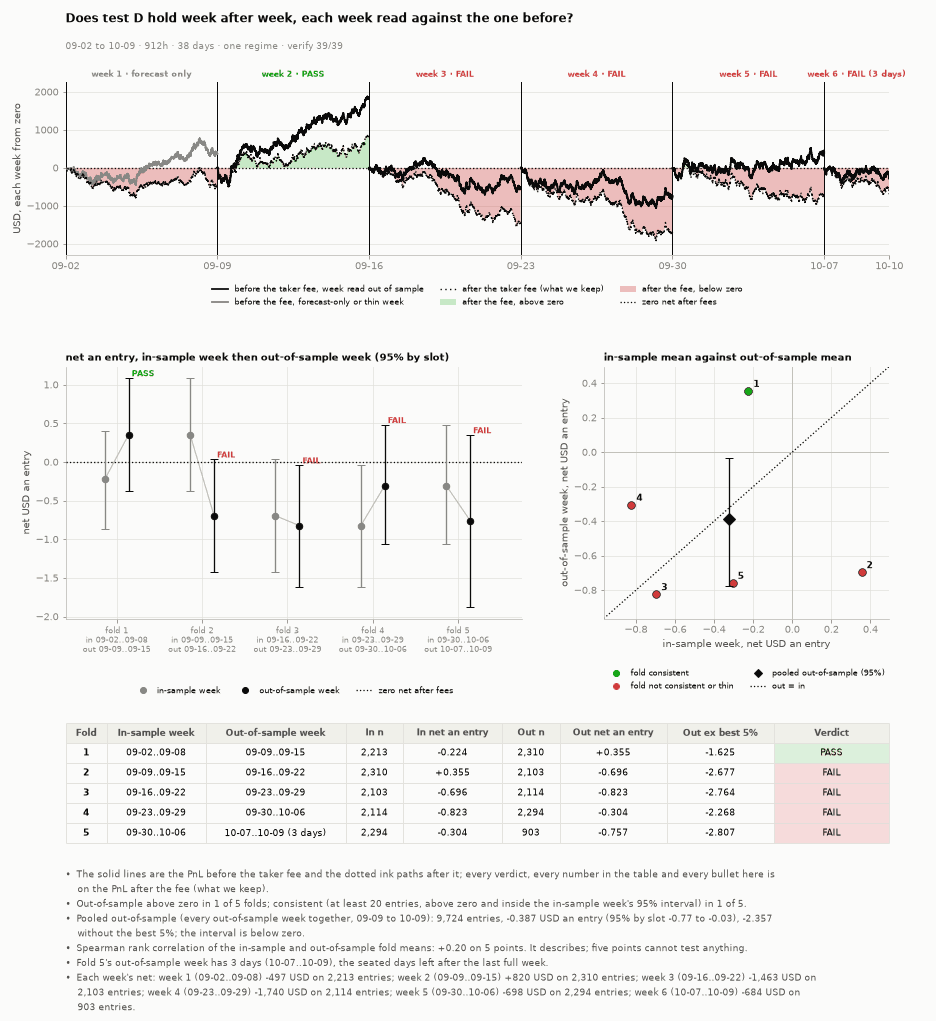

In [54]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

D has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn


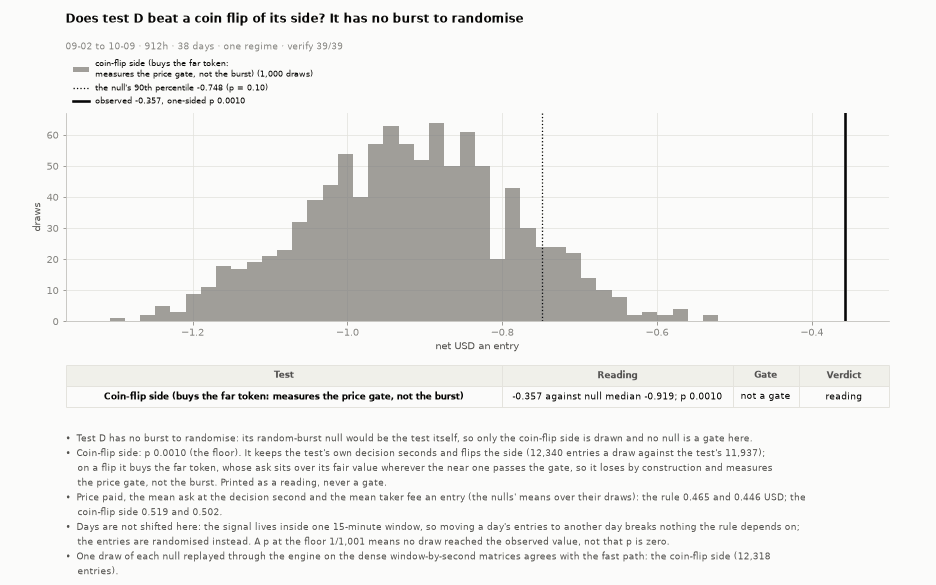

In [55]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test E · A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet

#### E · S0 Summary

In [56]:
LAB = "E"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test E: A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet.** 1,261 entries over 38 days, win rate 75.0% (Wilson 95% 72.6 to 77.3) against 65.2% to break even on the price paid; the mean win is +6.83 USD and the mean loss -15.06, reward to risk 0.45, profit factor 1.36, so the payoff needs 68.8% wins and gets them. Each trade's own reward to risk averages 0.89 (median 0.34). Without the best 5% of entries the net is +0.041 an entry (95% by 15-minute slot -0.58 to +0.70, 44% of the resamples at or below zero): the interval reaches zero, so the edge rests on its tail wins. Net +1.365 USD an entry (95% by 15-minute slot +0.68 to +2.07, which clears zero), +1722 USD in all, +8.18% on the dollars risked (the clip is not always spent: a partial fill risks less). First half +1.865 an entry on 698, second half +0.746 on 563. By coin an entry: BTC +1.39, ETH +2.28, SOL +0.18, XRP +0.32.

#### E · S1 Setup

In [57]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet: test A's burst and price gate, and the near token's ask at the decision second equal to its ask 3 seconds earlier: the book has not moved since the burst began, which is the staleness the thesis names, read directly.

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 4,609 decision seconds pass the gate in 1,704 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 1,261 entries: buy near 1,261.

#### E · S2 Data checks

In [58]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,728,3613,0.201,644.587,0.739,1.0
ETH,287,3597,0.080,637.505,0.635,1.0
SOL,135,3387,0.040,630.726,0.598,1.0
XRP,111,3153,0.035,585.964,0.548,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### E · S3 Core result

In [59]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),1261,75.020,65.227,1.365,0.680,2.066,1721.580,6.834,-15.059,0.454,1.363,68.784,0.894,0.344,0.041,97.157
first half (09-02..09-20),698,76.934,67.564,1.865,0.975,2.760,1301.475,6.740,-14.396,0.468,1.562,68.112,0.907,0.347,0.631,67.847
second half (09-21..10-09),563,72.647,62.736,0.746,-0.275,1.791,420.105,6.958,-15.752,0.442,1.173,69.361,0.878,0.327,-0.687,187.269
BTC,728,80.082,72.071,1.386,0.545,2.217,1008.981,6.570,-19.458,0.338,1.358,74.758,0.398,0.310,0.335,77.080
ETH,287,72.822,56.135,2.277,0.638,3.872,653.615,8.793,-15.180,0.579,1.552,63.323,1.134,0.418,0.354,85.283
SOL,135,62.963,54.540,0.175,-1.280,1.648,23.644,4.693,-7.505,0.625,1.063,61.527,2.134,0.459,-1.086,688.109
XRP,111,62.162,51.114,0.318,-1.589,2.196,35.341,5.772,-8.641,0.668,1.097,59.953,2.013,0.763,-1.167,446.723


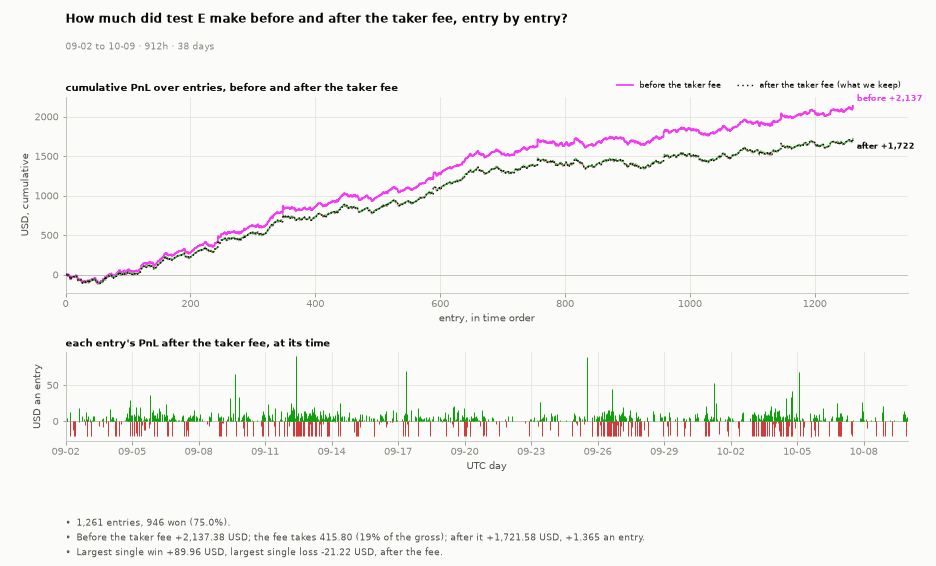

In [60]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-e-equity", FIGURES)

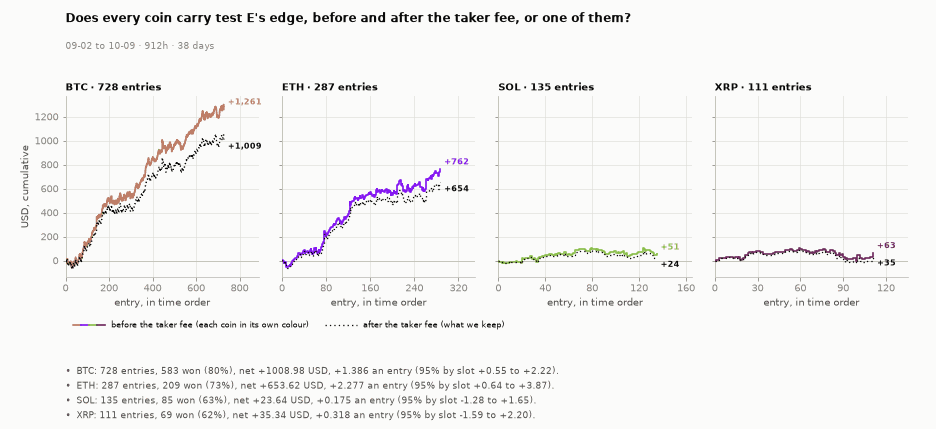

In [61]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-e-coins", FIGURES)

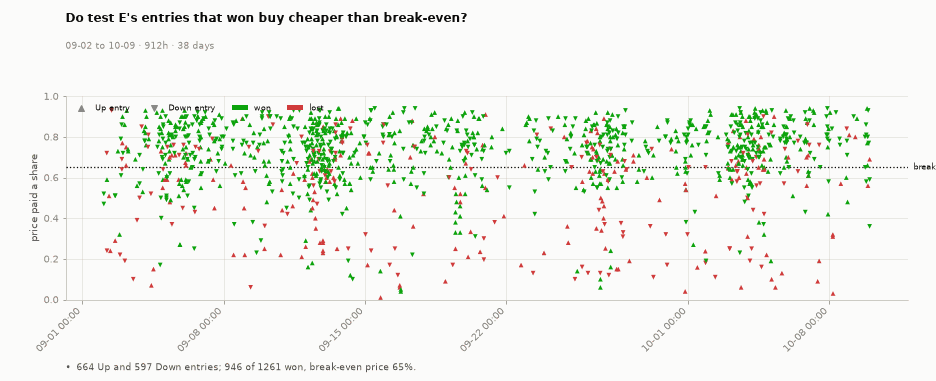

In [62]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-e-entrypx", FIGURES)

#### E · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

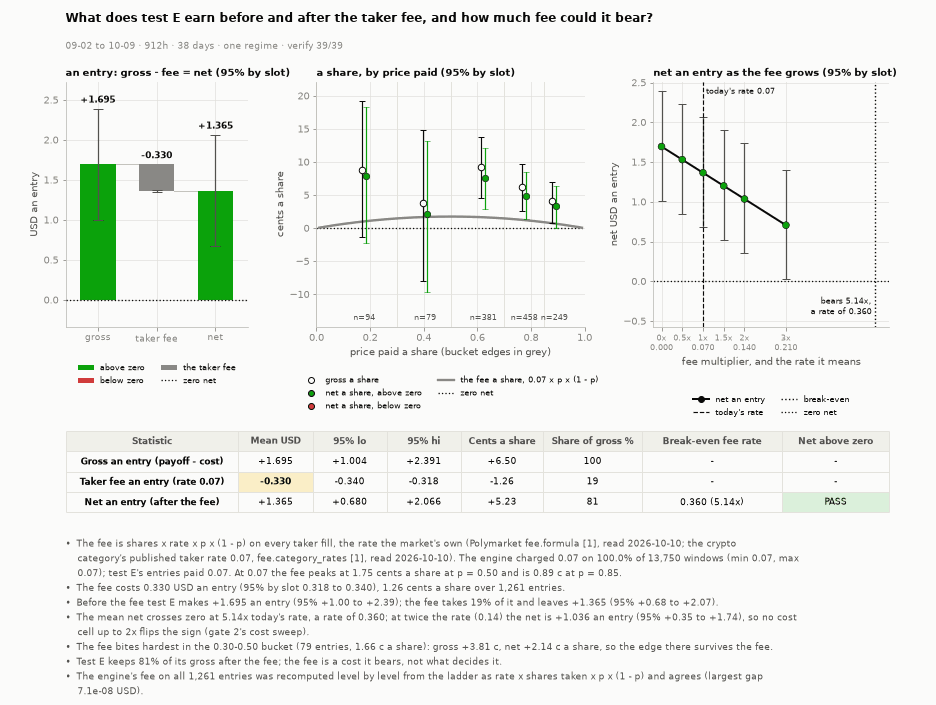

In [63]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

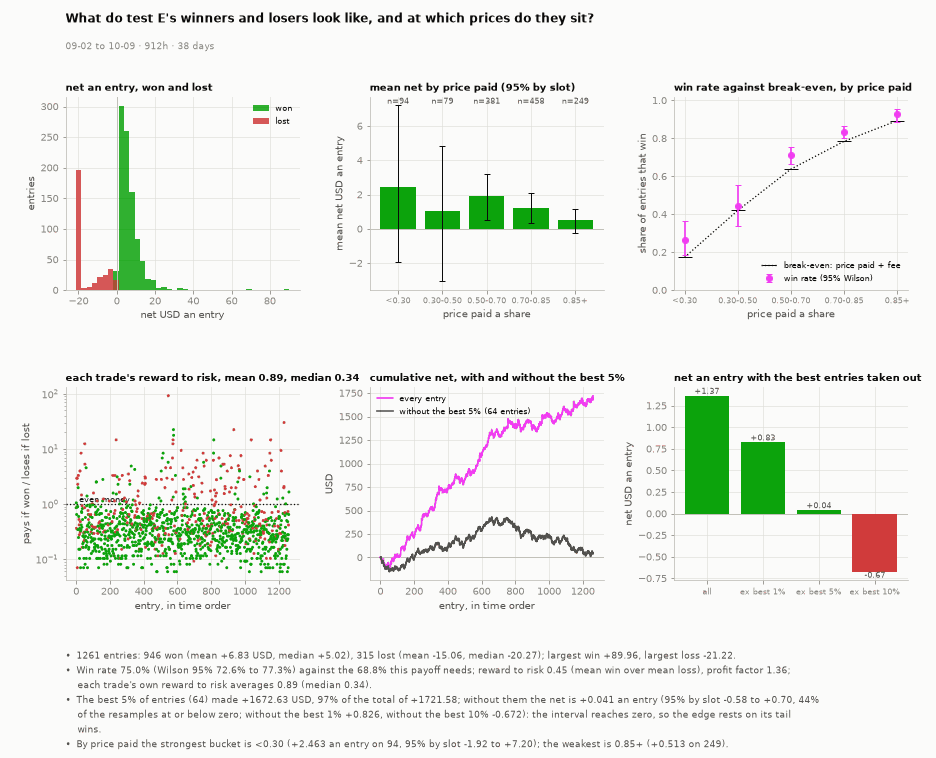

In [64]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-e-winloss", FIGURES)

In [65]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test E** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-12,eth,Up,buy near,545,355,0.18,111.11,20.000,1.148,True,89.962
2026-09-25,btc,Up,buy near,196,704,0.14,105.00,14.700,0.885,True,89.415
2026-09-17,eth,Down,buy near,555,345,0.22,90.90,19.998,1.092,True,69.810
2026-10-05,eth,Up,buy near,320,580,0.19,85.00,16.150,0.916,True,67.934
2026-09-09,btc,Down,buy near,73,827,0.23,86.95,19.999,1.078,True,65.874
2026-10-01,eth,Up,buy near,556,344,0.27,74.07,19.999,1.022,True,53.049
2026-09-26,eth,Up,buy near,446,454,0.10,50.00,5.000,0.315,True,44.685
2026-10-04,xrp,Up,buy near,578,322,0.32,62.50,20.000,0.952,True,41.548
2026-09-05,sol,Up,buy near,315,585,0.27,50.00,13.500,0.690,True,35.810
2026-10-09,xrp,Down,buy near,368,532,0.36,55.55,19.998,0.896,True,34.656


**The 10 worst entries of test E**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-05,btc,Up,buy near,490,410,0.130,153.84,19.999,1.218,False,-21.217
2026-09-11,xrp,Up,buy near,460,440,0.210,95.23,19.998,1.106,False,-21.104
2026-09-02,eth,Up,buy near,332,568,0.240,83.33,19.999,1.064,False,-21.063
2026-10-03,btc,Down,buy near,549,351,0.250,80.00,20.000,1.050,False,-21.050
2026-09-26,xrp,Up,buy near,462,438,0.252,79.38,19.999,1.047,False,-21.046
2026-09-27,btc,Down,buy near,26,874,0.309,64.76,19.999,0.968,False,-20.967
2026-09-29,xrp,Down,buy near,313,587,0.320,62.50,20.000,0.952,False,-20.952
2026-09-20,eth,Up,buy near,528,372,0.333,59.99,19.997,0.933,False,-20.930
2026-09-26,btc,Up,buy near,300,600,0.340,58.82,19.999,0.924,False,-20.923
2026-09-12,btc,Up,buy near,217,683,0.350,57.14,19.999,0.910,False,-20.909


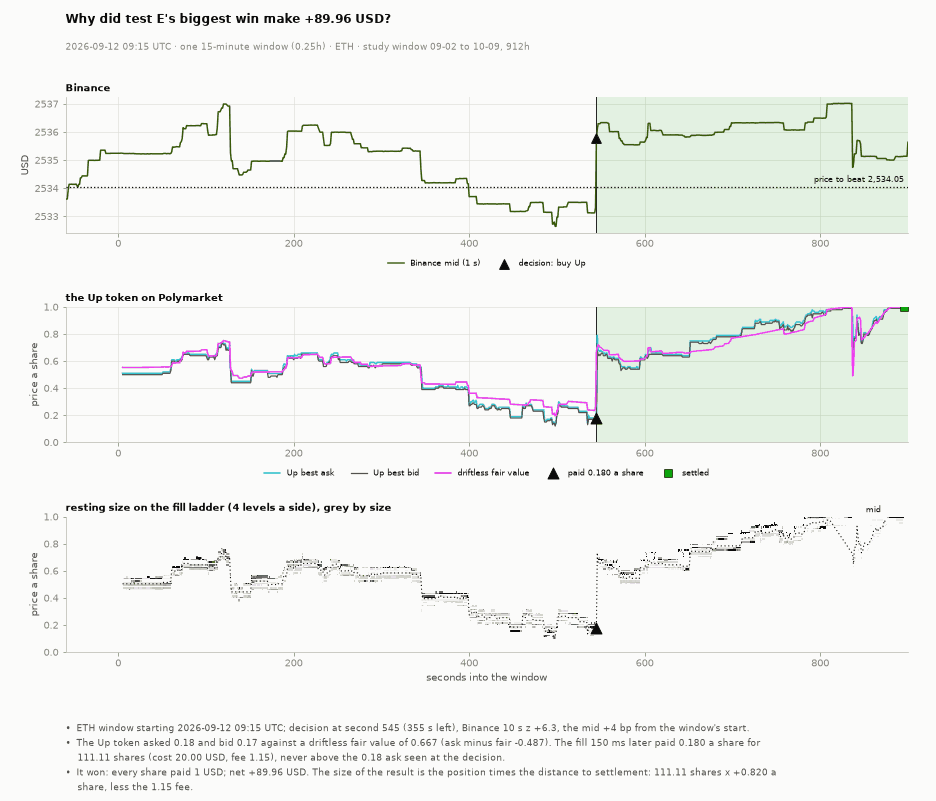

**Fill ladder at second 545 + 150 ms, ETH Up token: a buy of 20 USD of Up at no worse than the 0.18 ask seen at the decision; fair value 0.667; took 111.11 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,33.79,0.17,0.18,498.52,111.11,19.9998
2,30.00,0.16,0.19,536.00,0.00,0.0000
3,30.00,0.15,0.20,391.00,0.00,0.0000
4,165.00,0.14,0.22,210.00,0.00,0.0000


In [66]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

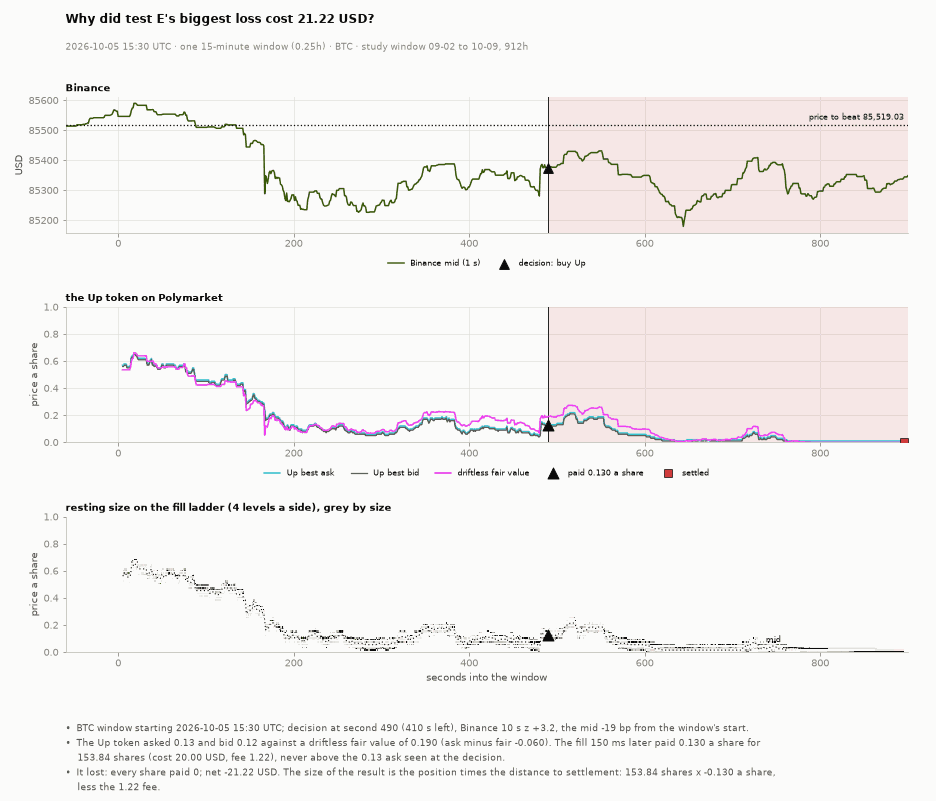

**Fill ladder at second 490 + 150 ms, BTC Up token: a buy of 20 USD of Up at no worse than the 0.13 ask seen at the decision; fair value 0.190; took 153.84 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,198.7100,0.12,0.13,368.52,153.84,19.9992
2,1274.0000,0.11,0.14,742.00,0.00,0.0000
3,1866.2100,0.10,0.15,1517.96,0.00,0.0000
4,5324.1201,0.09,0.16,7179.00,0.00,0.0000


In [67]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### E · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

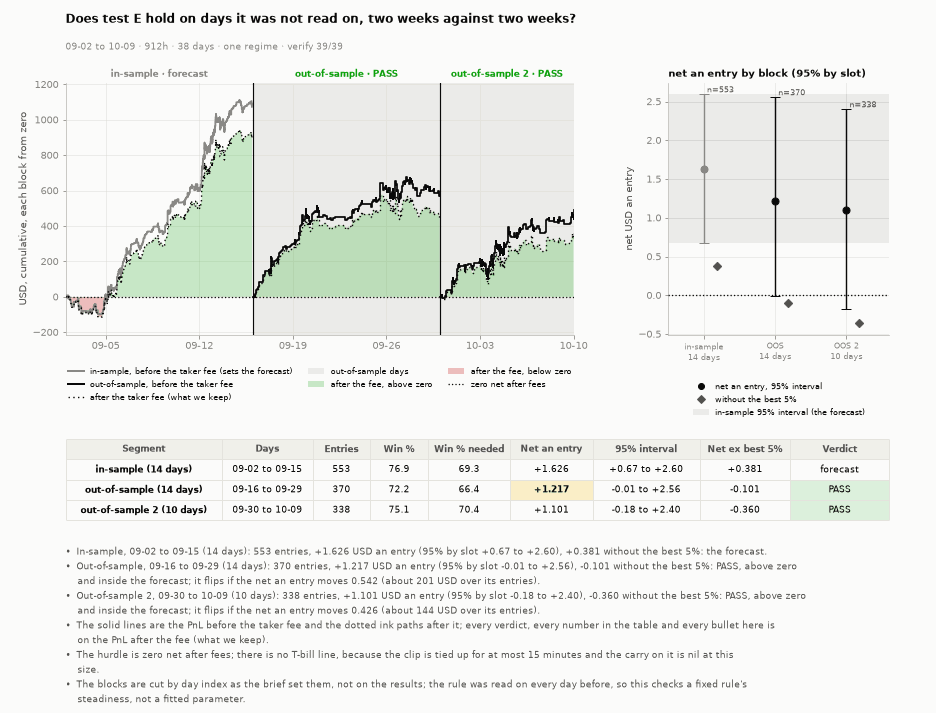

In [68]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

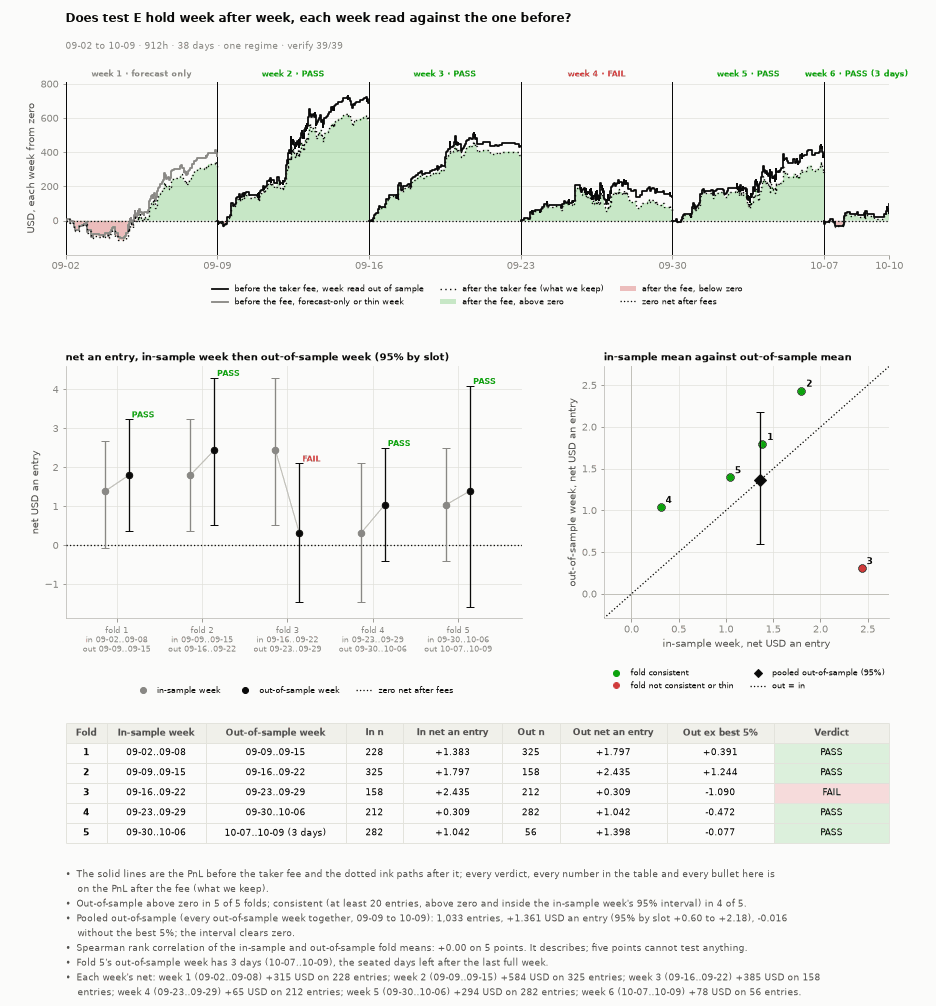

In [69]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

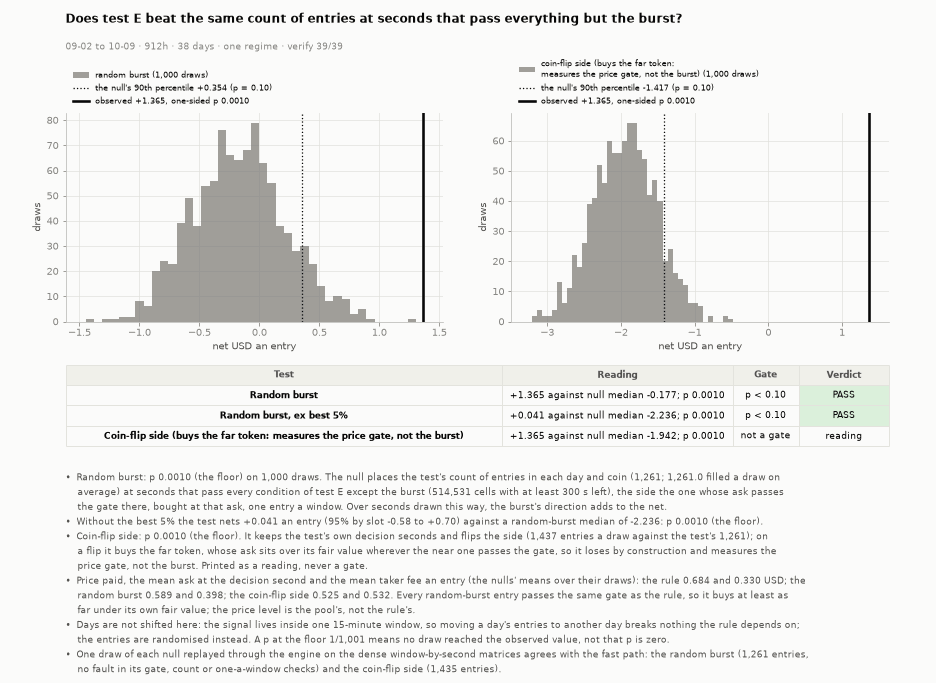

In [70]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test F · A's rule when at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print

#### F · S0 Summary

In [71]:
LAB = "F"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test F: A's rule when at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print.** 1,918 entries over 38 days, win rate 68.4% (Wilson 95% 66.3 to 70.4) against 61.5% to break even on the price paid; the mean win is +7.44 USD and the mean loss -13.91, reward to risk 0.54, profit factor 1.16, so the payoff needs 65.1% wins and gets them. Each trade's own reward to risk averages 1.01 (median 0.42). Without the best 5% of entries the net is -0.751 an entry (95% by 15-minute slot -1.33 to -0.18, 100% of the resamples at or below zero); 202% of the net sits in them: a few wins carry everything. Net +0.696 USD an entry (95% by 15-minute slot +0.05 to +1.35, which clears zero), +1336 USD in all, +4.42% on the dollars risked (the clip is not always spent: a partial fill risks less). First half +1.197 an entry on 1,079, second half +0.053 on 839. By coin an entry: BTC +0.63, ETH +1.14, SOL +0.46, XRP +0.25.

#### F · S1 Setup

In [72]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** A's rule when at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print: test A's burst and price gate, and at least one of the other three coins in the same 15-minute slot showing a 10 s |z| of at least 3 in the same direction at the same second.

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 9,923 decision seconds pass the gate in 2,935 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 1,918 entries: buy near 1,918.

#### F · S2 Data checks

In [73]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,868,3613,0.240,655.001,0.723,1.0
ETH,523,3597,0.145,649.413,0.629,1.0
SOL,292,3387,0.086,613.356,0.546,1.0
XRP,235,3153,0.075,592.655,0.473,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### F · S3 Core result

In [74]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),1918,68.405,61.523,0.696,0.050,1.347,1335.792,7.444,-13.913,0.535,1.158,65.144,1.010,0.418,-0.751,202.452
first half (09-02..09-20),1079,69.694,62.232,1.197,0.393,2.022,1291.395,7.420,-13.114,0.566,1.301,63.865,1.042,0.418,-0.286,122.725
second half (09-21..10-09),839,66.746,60.713,0.053,-0.902,1.027,44.397,7.477,-14.849,0.504,1.011,66.509,0.968,0.399,-1.339,2503.016
BTC,868,76.267,70.048,0.628,-0.205,1.477,545.461,6.917,-19.580,0.353,1.135,73.896,0.442,0.327,-0.486,173.450
ETH,523,69.216,56.385,1.141,-0.140,2.454,596.604,8.565,-15.552,0.551,1.238,64.486,0.973,0.438,-0.803,166.788
SOL,292,57.192,52.291,0.462,-0.813,1.853,135.011,6.873,-8.102,0.848,1.133,54.104,1.852,0.675,-1.177,341.492
XRP,235,51.489,46.417,0.250,-1.059,1.561,58.717,7.766,-7.728,1.005,1.067,49.877,2.139,1.236,-1.147,535.809


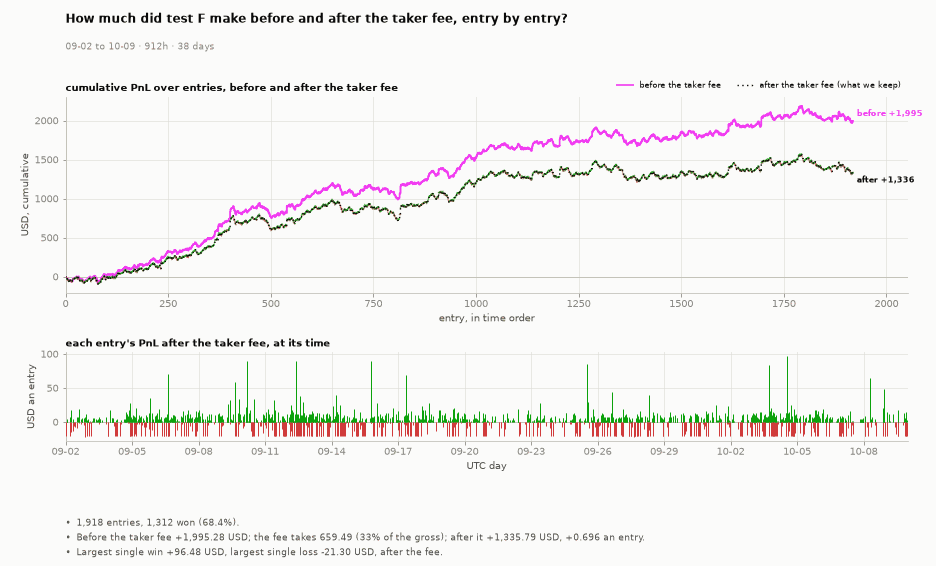

In [75]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-f-equity", FIGURES)

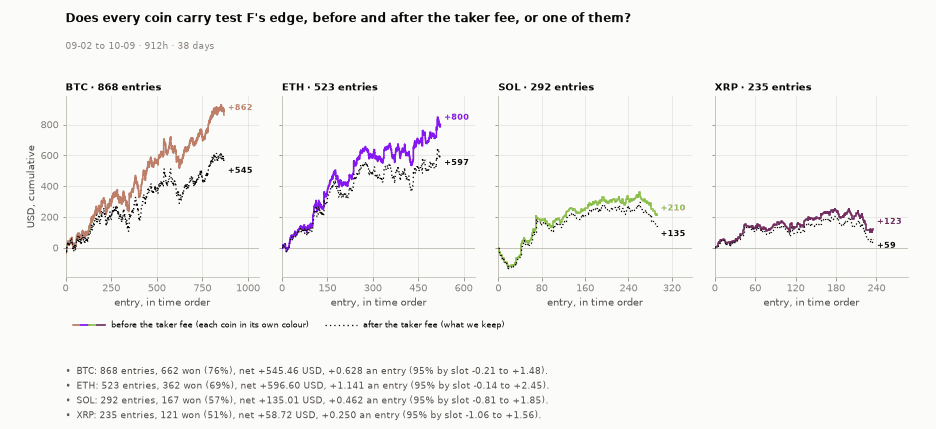

In [76]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-f-coins", FIGURES)

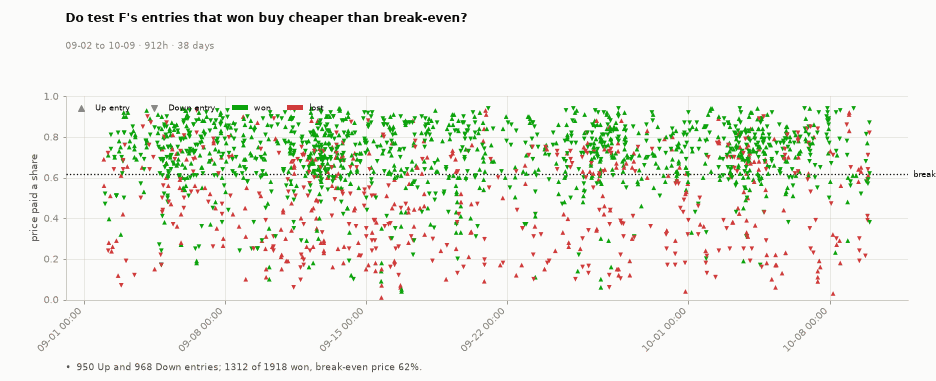

In [77]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-f-entrypx", FIGURES)

#### F · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

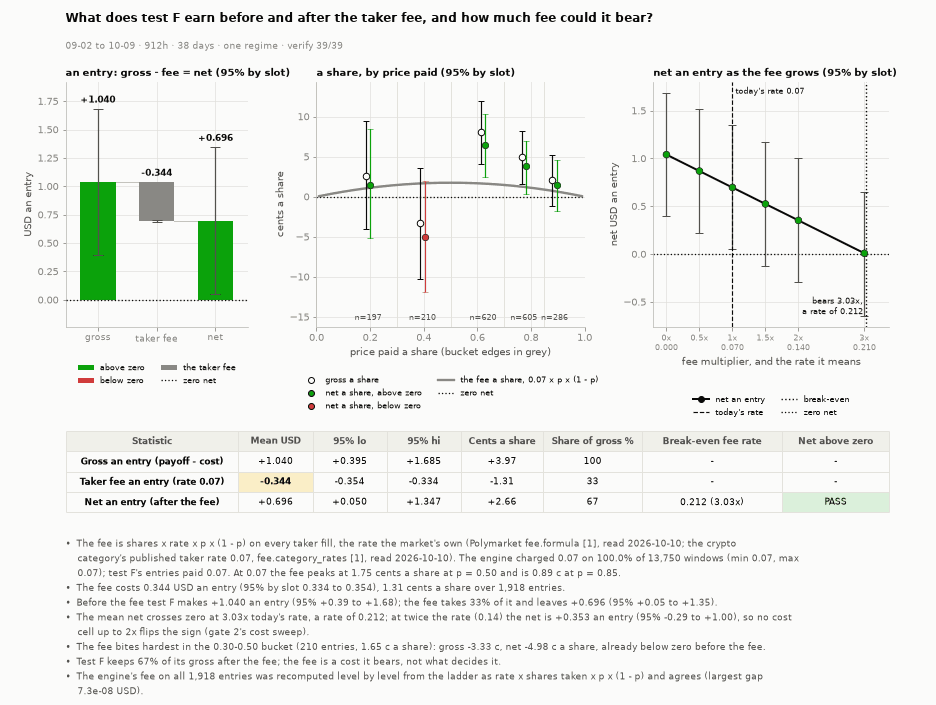

In [78]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

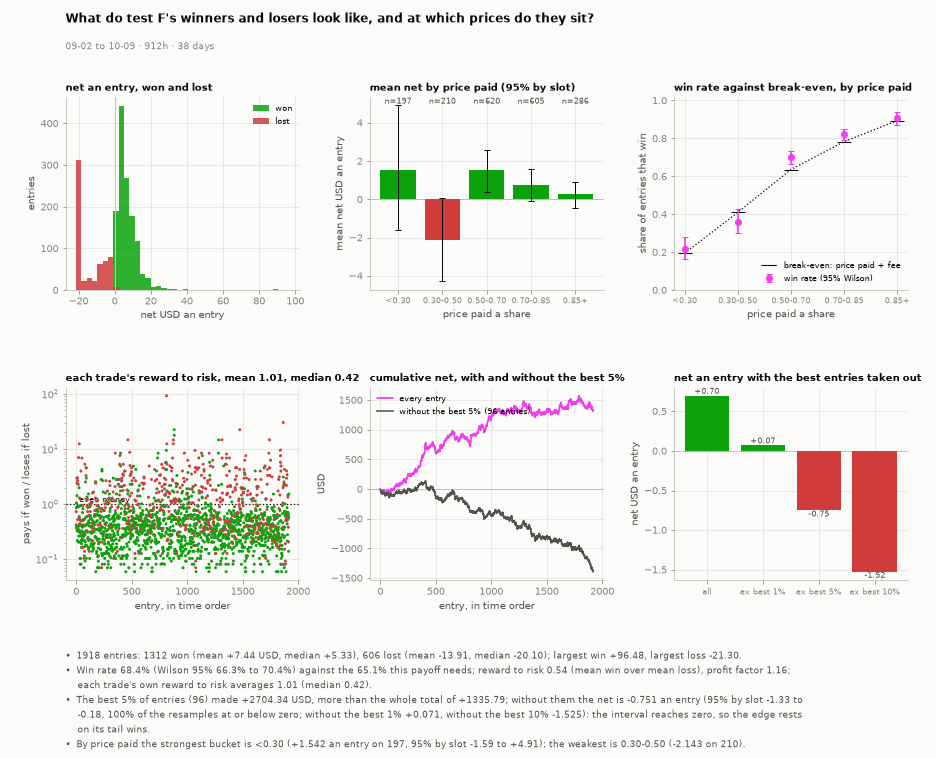

In [79]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-f-winloss", FIGURES)

In [80]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test F** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-04,eth,Down,buy near,520,380,0.170,117.64,19.999,1.162,True,96.479
2026-09-12,eth,Up,buy near,545,355,0.180,111.11,20.000,1.148,True,89.962
2026-09-15,btc,Up,buy near,379,521,0.180,111.11,20.000,1.148,True,89.962
2026-09-10,sol,Up,buy near,341,559,0.100,100.00,10.000,0.630,True,89.370
2026-09-25,btc,Up,buy near,195,705,0.140,100.00,14.000,0.843,True,85.157
2026-10-03,eth,Up,buy near,137,763,0.190,105.52,19.999,1.135,True,84.387
2026-09-06,sol,Up,buy near,152,748,0.190,87.92,16.705,0.947,True,70.268
2026-09-17,eth,Down,buy near,552,348,0.220,90.90,19.998,1.092,True,69.810
2026-10-08,eth,Up,buy near,407,493,0.232,86.37,19.998,1.076,True,65.296
2026-09-09,eth,Down,buy near,70,830,0.250,80.00,20.000,1.050,True,58.950


**The 10 worst entries of test F**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-02,eth,Down,buy near,591,309,0.070,285.71,20.000,1.302,False,-21.302
2026-09-27,btc,Down,buy near,585,315,0.103,193.99,19.999,1.255,False,-21.254
2026-10-05,btc,Up,buy near,490,410,0.130,153.84,19.999,1.218,False,-21.217
2026-09-11,xrp,Up,buy near,460,440,0.210,95.23,19.998,1.106,False,-21.104
2026-09-27,eth,Down,buy near,585,315,0.220,90.90,19.998,1.092,False,-21.090
2026-09-30,eth,Down,buy near,545,355,0.224,89.13,20.000,1.086,False,-21.086
2026-10-02,eth,Down,buy near,508,392,0.240,83.33,19.999,1.064,False,-21.063
2026-10-07,eth,Down,buy near,316,584,0.250,80.00,20.000,1.050,False,-21.050
2026-09-12,btc,Up,buy near,545,355,0.260,76.92,19.999,1.036,False,-21.035
2026-09-10,eth,Down,buy near,477,423,0.260,76.92,19.999,1.036,False,-21.035


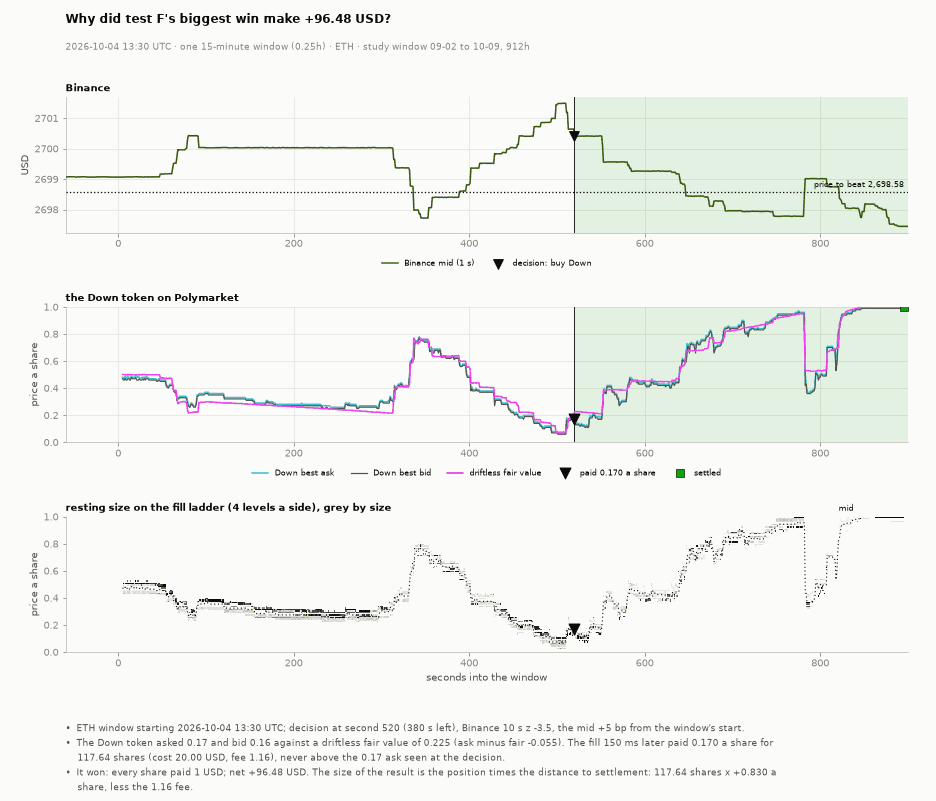

**Fill ladder at second 520 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.17 ask seen at the decision; fair value 0.225; took 117.64 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,25.00,0.16,0.17,136.88,117.64,19.9988
2,5.01,0.15,0.18,45.00,0.00,0.0000
3,55.07,0.14,0.19,165.00,0.00,0.0000
4,170.00,0.13,0.20,145.00,0.00,0.0000


In [81]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-f-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

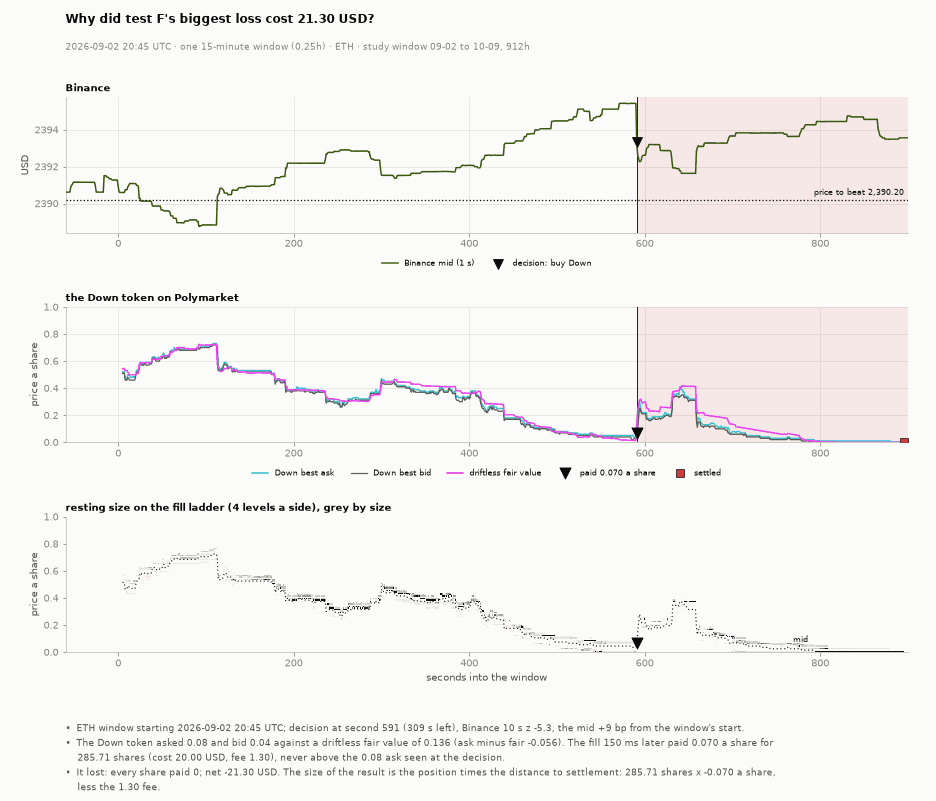

**Fill ladder at second 591 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.08 ask seen at the decision; fair value 0.136; took 285.71 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,55.38,0.04,0.07,456.0,285.71,19.9997
2,20.00,0.03,0.08,15.0,0.00,0.0000
3,26.00,0.02,0.11,5.0,0.00,0.0000
4,132.84,0.01,0.12,5.0,0.00,0.0000


In [82]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-f-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### F · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

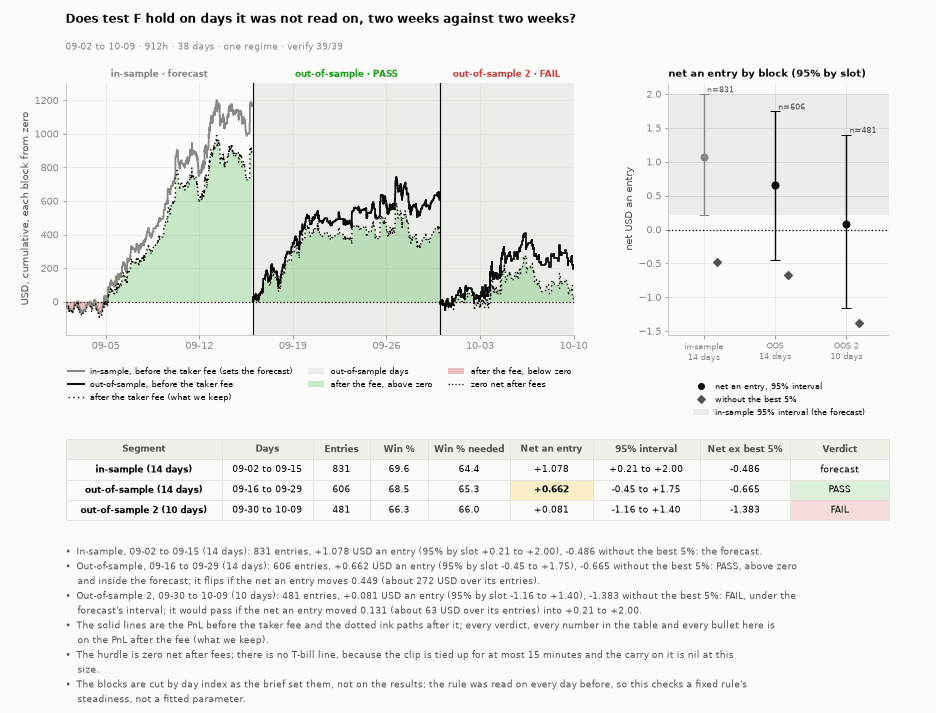

In [83]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

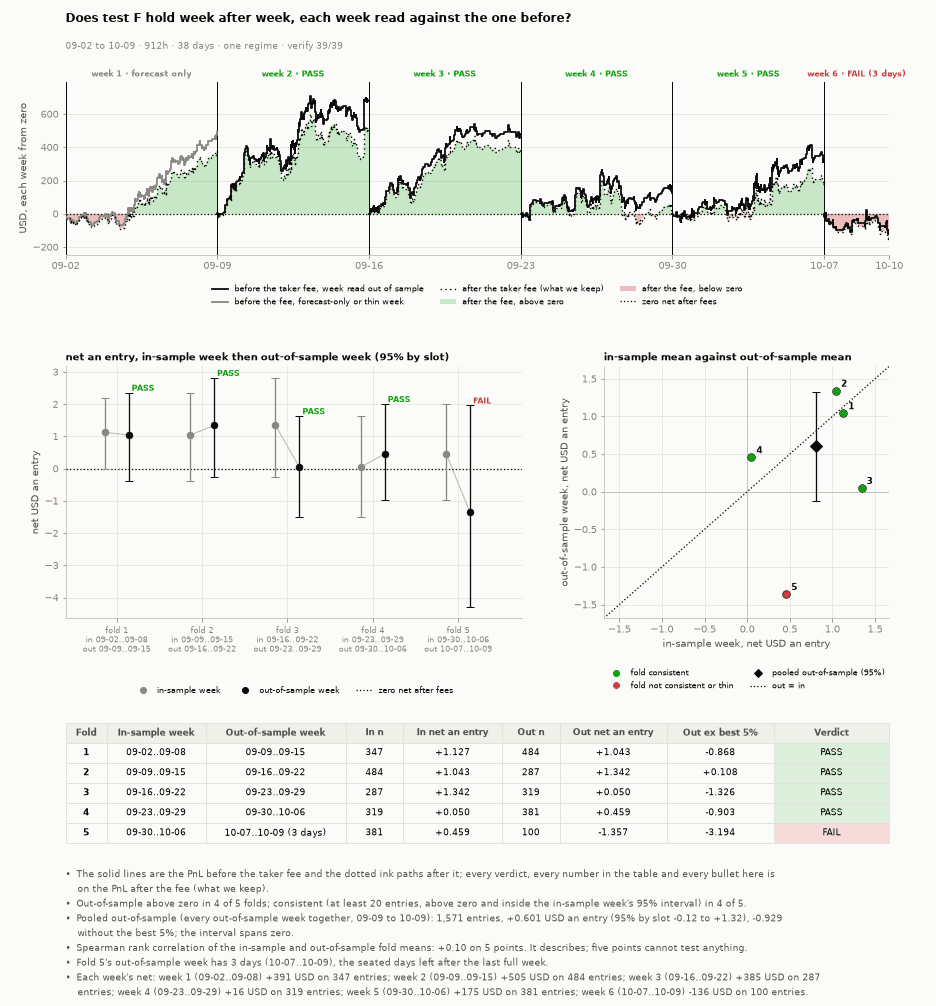

In [84]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

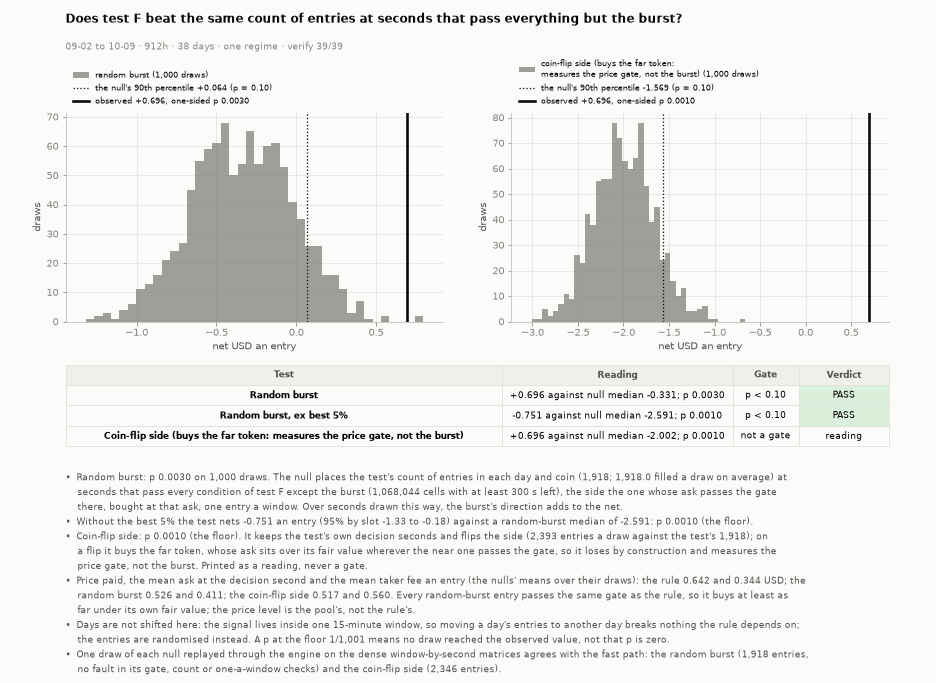

In [85]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test G · Bitcoin bursts: buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst)

#### G · S0 Summary

In [86]:
LAB = "G"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test G: Bitcoin bursts: buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst).** 1,240 entries over 38 days, win rate 59.0% (Wilson 95% 56.3 to 61.7) against 53.1% to break even on the price paid; the mean win is +7.98 USD and the mean loss -11.19, reward to risk 0.71, profit factor 1.03, so the payoff needs 58.4% wins and gets them. Each trade's own reward to risk averages 1.49 (median 0.60). Without the best 5% of entries the net is -1.623 an entry (95% by 15-minute slot -2.28 to -0.96, 100% of the resamples at or below zero); 1324% of the net sits in them: a few wins carry everything. Net +0.126 USD an entry (95% by 15-minute slot -0.66 to +0.95, which spans zero), +156 USD in all, +1.00% on the dollars risked (the clip is not always spent: a partial fill risks less). First half +0.905 an entry on 682, second half -0.827 on 558. By coin an entry: BTC no entry, ETH +0.42, SOL +0.03, XRP -0.37.

#### G · S1 Setup

In [87]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** Bitcoin bursts: buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst): ETH, SOL and XRP windows only: Bitcoin's 10 s |z| at least z_min at that second, and the coin's own near token (the side Bitcoin points to) asking more than theta under its own fair value; the coin needs no burst of its own; buy that near token.

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 6,384 decision seconds pass the gate in 1,885 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 1,240 entries: buy near 1,240.

#### G · S2 Data checks

In [88]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,0,3613,0.000,NaN,NaN,NaN
ETH,607,3597,0.169,644.913,0.609,1.0
SOL,331,3387,0.098,606.263,0.547,1.0
XRP,302,3153,0.096,583.795,0.489,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### G · S3 Core result

In [89]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),1240,59.032,53.106,0.126,-0.658,0.953,156.190,7.977,-11.186,0.713,1.027,58.375,1.491,0.596,-1.623,1324.403
first half (09-02..09-20),682,61.144,52.932,0.905,-0.030,1.885,617.416,7.576,-9.592,0.790,1.243,55.871,1.583,0.596,-0.892,193.461
second half (09-21..10-09),558,56.452,53.280,-0.827,-2.048,0.459,-461.226,8.506,-12.925,0.658,0.853,60.309,1.379,0.596,-2.548,NaN
BTC,0,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ETH,607,64.745,55.266,0.420,-0.783,1.591,255.106,8.992,-15.322,0.587,1.078,63.016,1.140,0.502,-1.669,476.749
SOL,331,56.495,52.373,0.035,-1.125,1.228,11.497,6.563,-8.443,0.777,1.009,56.264,1.759,0.648,-1.453,4067.527
XRP,302,50.331,47.882,-0.366,-1.572,0.741,-110.413,7.089,-7.920,0.895,0.907,52.767,1.903,1.085,-1.772,NaN


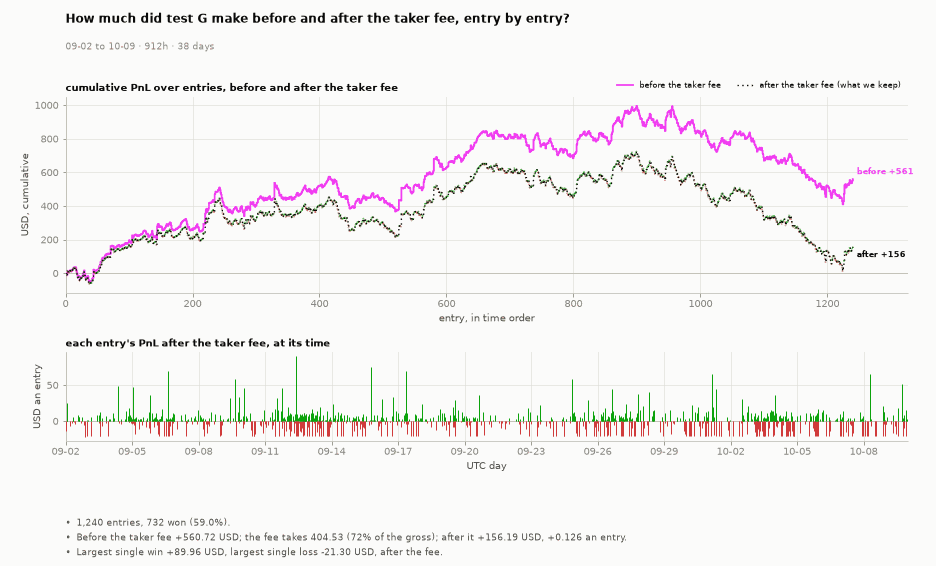

In [90]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-g-equity", FIGURES)

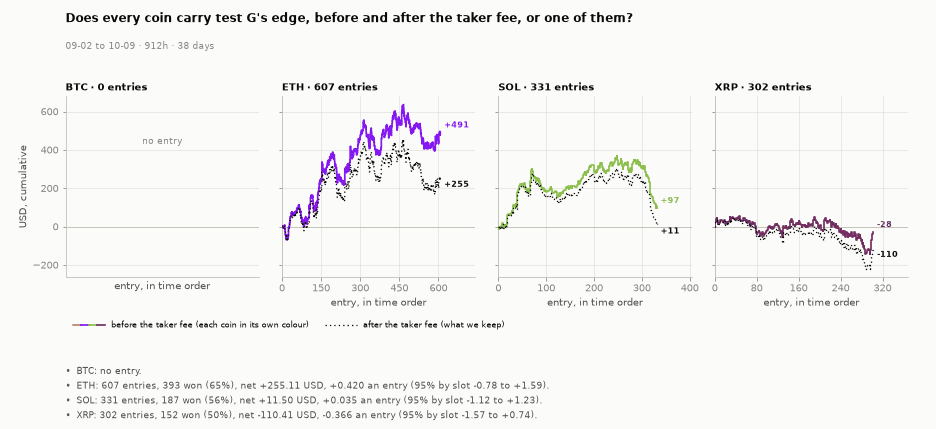

In [91]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-g-coins", FIGURES)

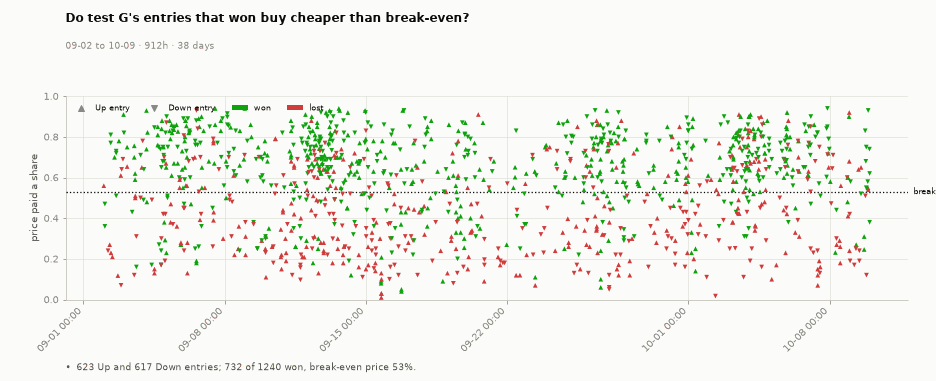

In [92]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-g-entrypx", FIGURES)

#### G · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

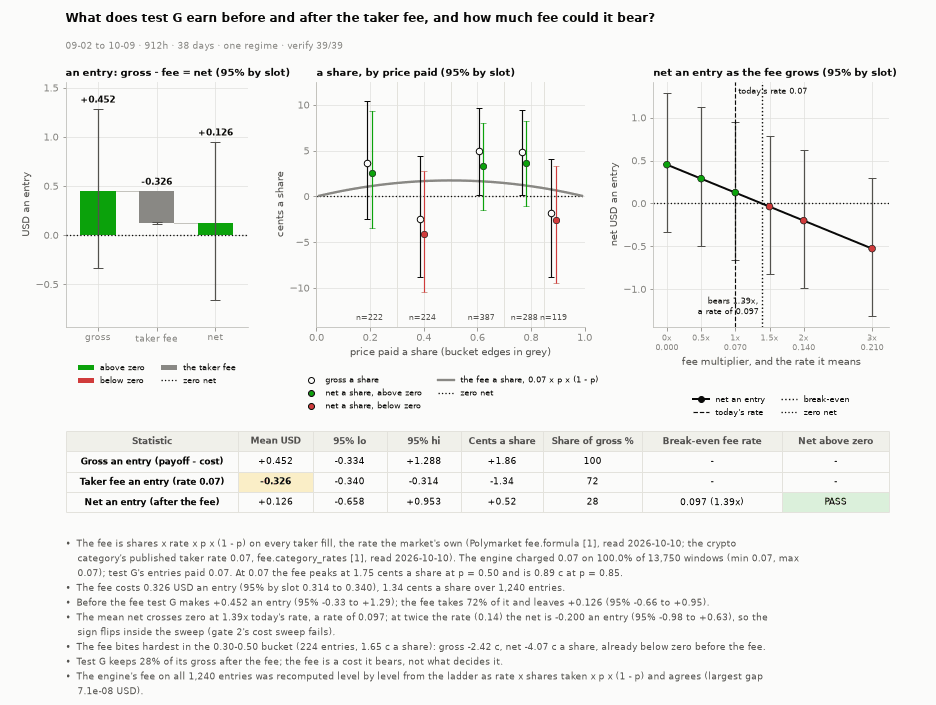

In [93]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

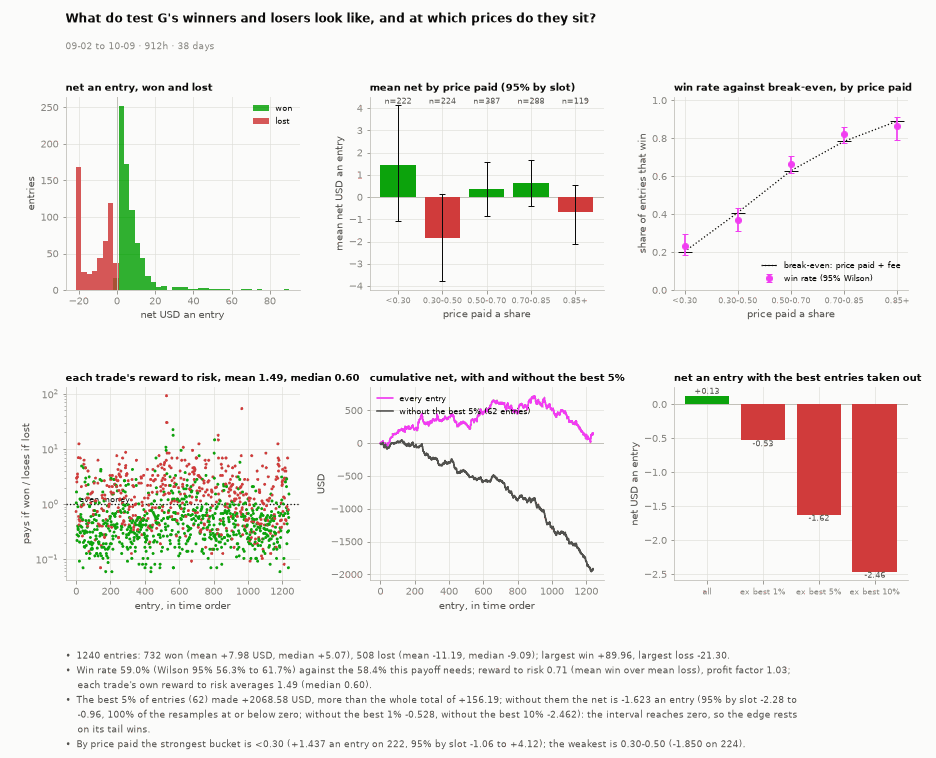

In [94]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-g-winloss", FIGURES)

In [95]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test G** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-12,eth,Up,buy near,545,355,0.180,111.11,20.000,1.148,True,89.962
2026-09-15,eth,Up,buy near,340,560,0.208,96.30,19.999,1.109,True,75.192
2026-09-06,sol,Up,buy near,152,748,0.190,87.92,16.705,0.947,True,70.268
2026-09-17,eth,Down,buy near,552,348,0.220,90.90,19.998,1.092,True,69.810
2026-10-01,eth,Up,buy near,314,586,0.230,86.95,19.999,1.078,True,65.874
2026-10-08,eth,Up,buy near,407,493,0.232,86.37,19.998,1.076,True,65.296
2026-09-09,eth,Down,buy near,70,830,0.250,80.00,20.000,1.050,True,58.950
2026-09-24,eth,Up,buy near,503,397,0.250,80.00,20.000,1.050,True,58.950
2026-09-15,xrp,Up,buy near,206,694,0.090,62.02,5.582,0.356,True,56.083
2026-10-09,xrp,Up,buy near,489,411,0.246,70.29,17.320,0.914,True,52.057


**The 10 worst entries of test G**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-02,eth,Down,buy near,591,309,0.070,285.71,20.000,1.302,False,-21.302
2026-09-11,xrp,Up,buy near,460,440,0.210,95.23,19.998,1.106,False,-21.104
2026-09-27,eth,Down,buy near,585,315,0.220,90.90,19.998,1.092,False,-21.090
2026-09-30,eth,Down,buy near,545,355,0.224,89.13,20.000,1.086,False,-21.086
2026-10-07,eth,Down,buy near,316,584,0.250,80.00,20.000,1.050,False,-21.050
2026-09-10,eth,Down,buy near,477,423,0.260,76.92,19.999,1.036,False,-21.035
2026-09-26,eth,Up,buy near,598,302,0.260,76.92,19.999,1.036,False,-21.035
2026-09-25,eth,Up,buy near,132,768,0.260,76.92,19.999,1.036,False,-21.035
2026-10-08,eth,Up,buy near,353,547,0.260,76.92,19.999,1.036,False,-21.035
2026-09-28,eth,Down,buy near,484,416,0.287,69.65,19.998,0.998,False,-20.996


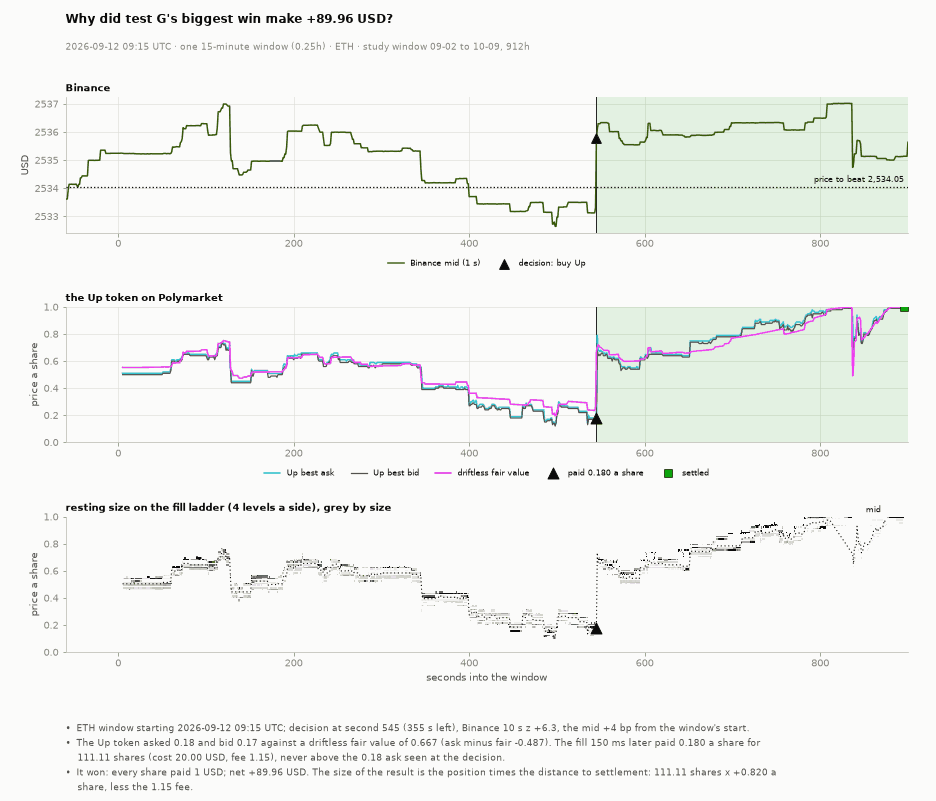

**Fill ladder at second 545 + 150 ms, ETH Up token: a buy of 20 USD of Up at no worse than the 0.18 ask seen at the decision; fair value 0.667; took 111.11 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,33.79,0.17,0.18,498.52,111.11,19.9998
2,30.00,0.16,0.19,536.00,0.00,0.0000
3,30.00,0.15,0.20,391.00,0.00,0.0000
4,165.00,0.14,0.22,210.00,0.00,0.0000


In [96]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-g-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

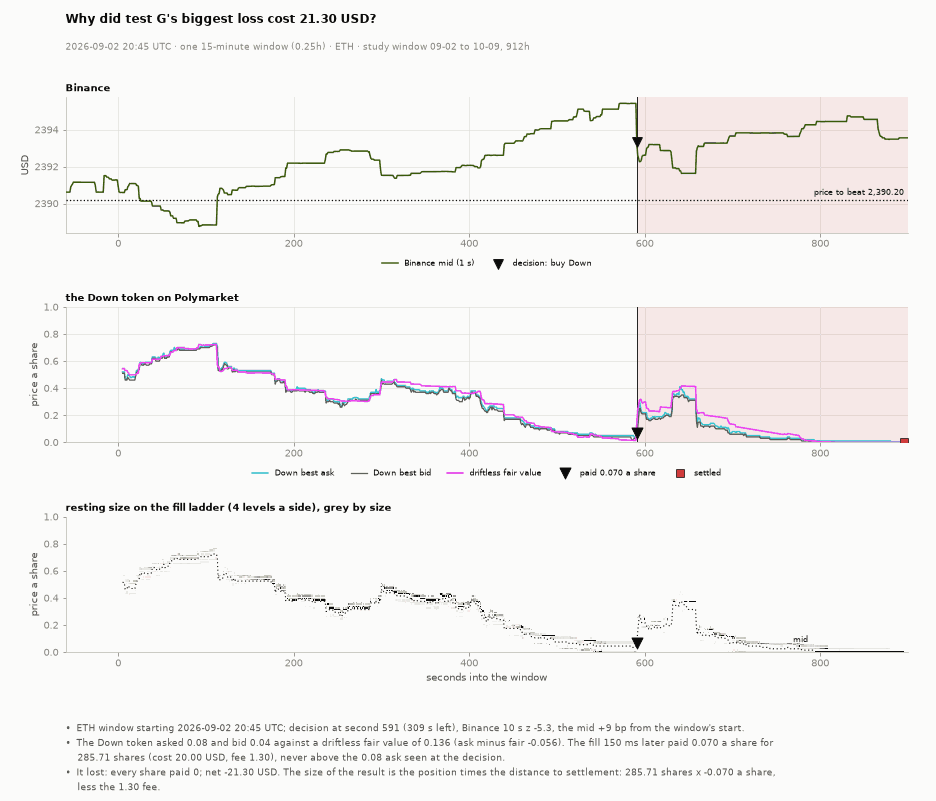

**Fill ladder at second 591 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.08 ask seen at the decision; fair value 0.136; took 285.71 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,55.38,0.04,0.07,456.0,285.71,19.9997
2,20.00,0.03,0.08,15.0,0.00,0.0000
3,26.00,0.02,0.11,5.0,0.00,0.0000
4,132.84,0.01,0.12,5.0,0.00,0.0000


In [97]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-g-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### G · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

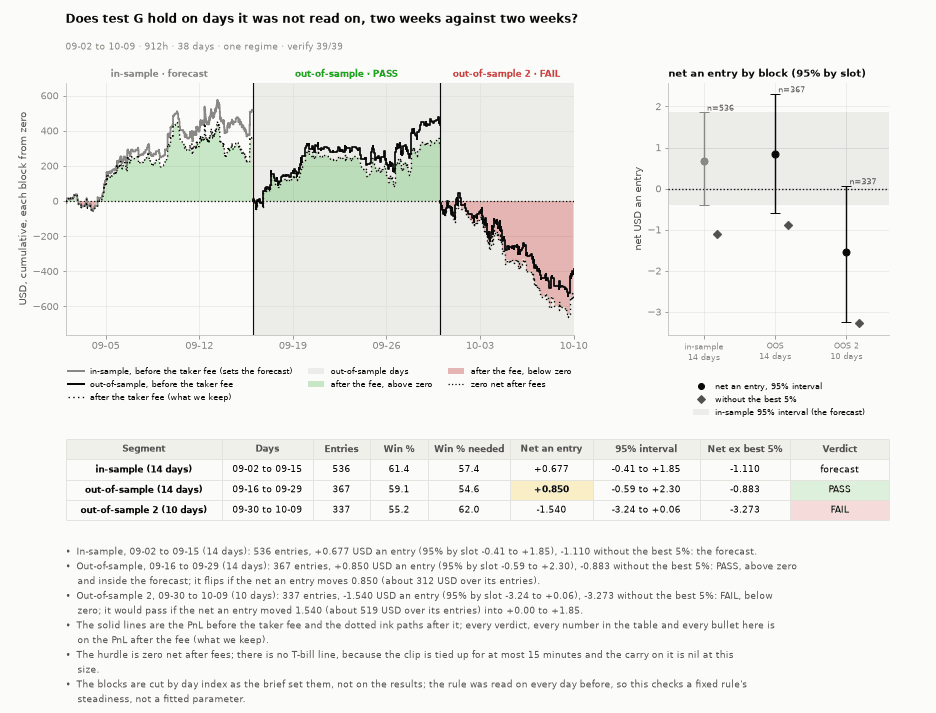

In [98]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

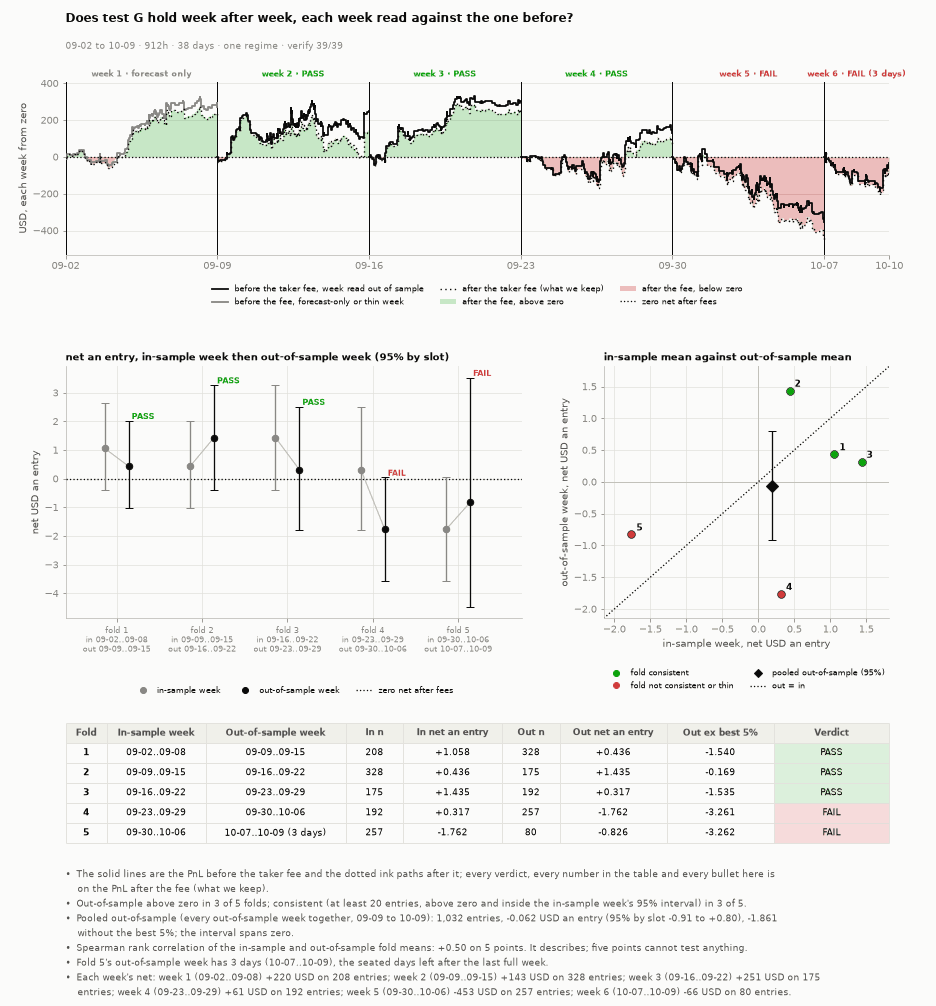

In [99]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

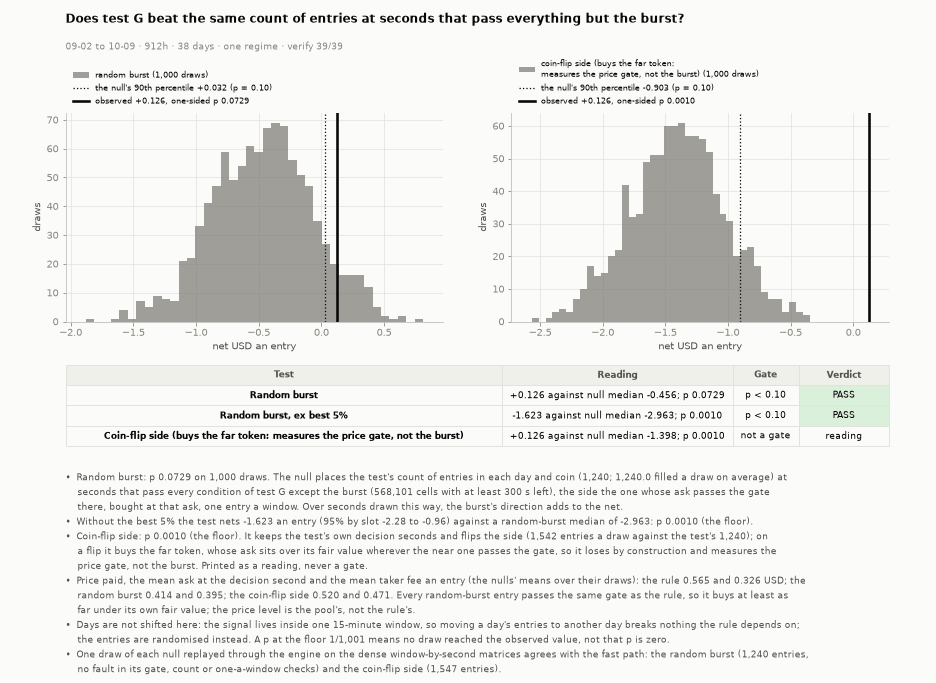

In [100]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

### Test H · A's rule when at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book

#### H · S0 Summary

In [101]:
LAB = "H"
E_, S_, SF_, SS_ = TESTS[LAB], SUMM[LAB], SUMM_F[LAB], SUMM_S[LAB]
display(Markdown(summary_line(LAB)))

**Test H: A's rule when at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book.** 2,106 entries over 38 days, win rate 74.3% (Wilson 95% 72.4 to 76.1) against 67.8% to break even on the price paid; the mean win is +7.91 USD and the mean loss -19.80, reward to risk 0.40, profit factor 1.15, so the payoff needs 71.5% wins and gets them. Each trade's own reward to risk averages 0.48 (median 0.36). Without the best 5% of entries the net is -0.586 an entry (95% by 15-minute slot -1.20 to -0.00, 98% of the resamples at or below zero); 172% of the net sits in them: a few wins carry everything. Net +0.777 USD an entry (95% by 15-minute slot +0.15 to +1.38, which clears zero), +1636 USD in all, +3.99% on the dollars risked (the clip is not always spent: a partial fill risks less). First half +1.190 an entry on 1,052, second half +0.364 on 1,054. By coin an entry: BTC +0.51, ETH +1.56, SOL -0.34, XRP +1.62.

#### H · S1 Setup

In [102]:
_g = GATE_CELLS[LAB]
_legs = ", ".join(f"{C.LEG[int(l)]} {int((E_['leg'] == l).sum()):,}" for l in np.unique(E_["leg"]))
display(Markdown(f"**The rule.** {C.TESTS[LAB][0]}: {C.TESTS[LAB][1]}.\n\n"
                 f"**Parameters.** burst lookback {L} s, |z| at least {Z_MIN:g} where momentum is required, margin {THETA:.2f} against the driftless fair value where a price gate is required, "
                 f"at least {T_MIN} s left, USD {CLIP_USD:g} a trade, the fill {LAT_MS} ms after the decision at the ladder then standing, held to expiry.\n\n"
                 f"**Where it fires.** {int(_g.sum()):,} decision seconds pass the gate in {len(np.unique(np.nonzero(_g)[0])):,} of {TAB.W:,} windows; after the fill rules "
                 f"(at least 5 shares, one entry a window a leg) the test holds {S_['n']:,} entries: {_legs}."))

**The rule.** A's rule when at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book: test A's burst and price gate, and the size at the near token's best ask worth at least the clip (USD 20) at the decision second, so the order should fill at one price; when the best ask holds less, the fill walks up the book to dearer prices.

**Parameters.** burst lookback 10 s, |z| at least 3 where momentum is required, margin 0.05 against the driftless fair value where a price gate is required, at least 300 s left, USD 20 a trade, the fill 250 ms after the decision at the ladder then standing, held to expiry.

**Where it fires.** 12,684 decision seconds pass the gate in 2,510 of 13,750 windows; after the fill rules (at least 5 shares, one entry a window a leg) the test holds 2,106 entries: buy near 2,106.

#### H · S2 Data checks

In [103]:
_bycoin = pd.DataFrame([dict(coin=a.upper(), entries=int((E_["asset"] == ai).sum()), windows_with_book=int((TAB.w_asset == ai).sum()),
                             share_of_windows=float((E_["asset"] == ai).sum() / max((TAB.w_asset == ai).sum(), 1)),
                             mean_seconds_left=float(E_["T"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             mean_price_paid=float(E_["vwap"][E_["asset"] == ai].mean()) if (E_["asset"] == ai).any() else np.nan,
                             max_collateral_x_clip=float(E_["levered"][E_["asset"] == ai].max()) if (E_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)])
display(Markdown("**Entries by coin**"))
display(HTML(_bycoin.round(3).to_html(index=False, border=0)))
display(Markdown("**The eight invariants on this test's entries**\n\n" + pass_table(INV[LAB])))

**Entries by coin**

coin,entries,windows_with_book,share_of_windows,mean_seconds_left,mean_price_paid,max_collateral_x_clip
BTC,1309,3613,0.362,665.607,0.717,1.0
ETH,557,3597,0.155,665.050,0.675,1.0
SOL,151,3387,0.045,639.099,0.718,1.0
XRP,89,3153,0.028,614.382,0.714,1.0


**The eight invariants on this test's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw (a sale: received no less than the bid it saw) | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share (p(1-p) peaks at 0.25) | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window a leg | PASS |
| every entry's decision second passed its own leg's gate, and bet with the burst (or the gate's side for F) | PASS |

#### H · S3 Core result

In [104]:
_rows = [row("whole (38 days)", S_), row("first half (09-02..09-20)", SF_), row("second half (09-21..10-09)", SS_)]
for ai, a in enumerate(ASSET):
    _rows.append(row(a.upper(), B.summarize(B.subset(E_, E_["asset"] == ai), TAB, a)))
for l in np.unique(E_["leg"]):
    if len(np.unique(E_["leg"])) > 1:
        _rows.append(row(f"leg: {C.LEG[int(l)]}", B.summarize(B.subset(E_, E_["leg"] == l), TAB, C.LEG[int(l)])))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

label,n,win_pct,breakeven_pct,per_entry,lo,hi,net,avg_win,avg_loss,reward_to_risk,profit_factor,win_needed_pct,rr_per_trade,rr_per_trade_median,per_entry_ex_best5,best5_share_pct
whole (38 days),2106,74.264,67.779,0.777,0.150,1.378,1636.132,7.907,-19.797,0.399,1.152,71.460,0.479,0.362,-0.586,171.664
first half (09-02..09-20),1052,76.141,68.511,1.190,0.308,2.017,1252.398,7.774,-19.820,0.392,1.252,71.827,0.460,0.362,-0.129,110.268
second half (09-21..10-09),1054,72.391,67.066,0.364,-0.505,1.216,383.733,8.045,-19.776,0.407,1.067,71.082,0.497,0.362,-1.043,372.041
BTC,1309,74.943,69.982,0.514,-0.182,1.210,673.403,7.409,-20.106,0.368,1.102,73.073,0.433,0.344,-0.538,199.332
ETH,557,73.250,62.970,1.561,0.226,2.867,869.590,9.285,-19.589,0.474,1.298,67.843,0.590,0.399,-0.326,119.828
SOL,151,71.523,68.836,-0.338,-2.344,1.677,-51.020,6.913,-18.549,0.373,0.936,72.850,0.442,0.310,-1.783,NaN
XRP,89,75.281,66.408,1.620,-1.432,4.956,144.159,8.397,-19.021,0.441,1.344,69.373,0.523,0.294,-0.611,135.610


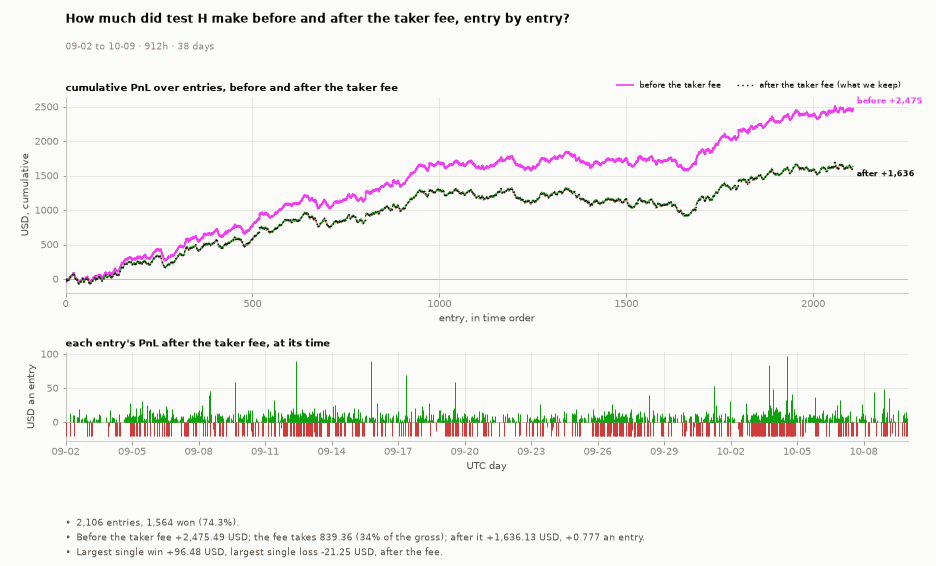

In [105]:
figstyle.show(TF.equity_fig(E_, DAYS, question=f"How much did test {LAB} make before and after the taker fee, entry by entry?"), "fig:s3-h-equity", FIGURES)

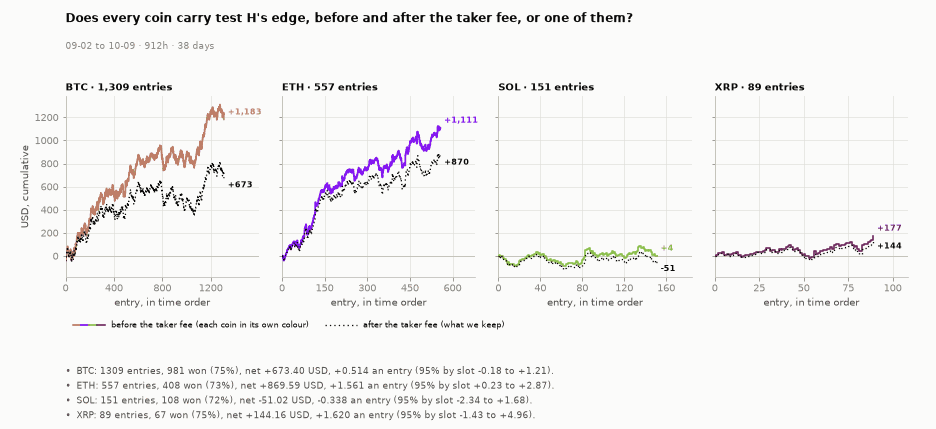

In [106]:
figstyle.show(TF.coin_panels_fig(E_, DAYS, question=f"Does every coin carry test {LAB}'s edge, before and after the taker fee, or one of them?"), "fig:s3-h-coins", FIGURES)

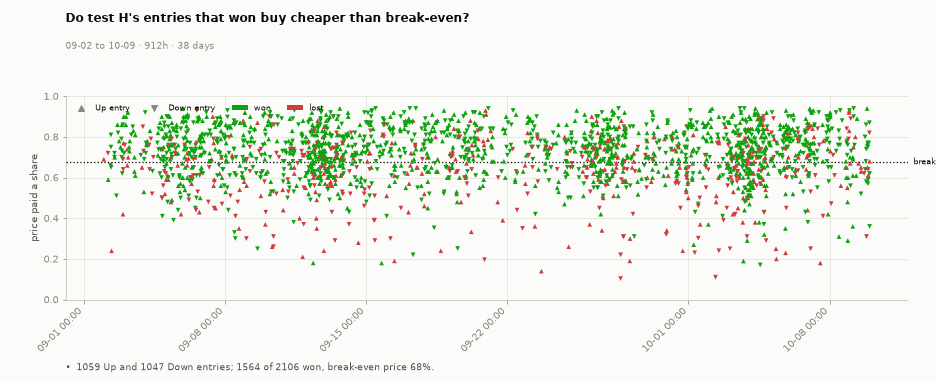

In [107]:
figstyle.show(TF.entry_price_fig(E_, DAYS, be=float(S_["breakeven"]), question=f"Do test {LAB}'s entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-h-entrypx", FIGURES)

#### H · S4 Robustness

What the taker fee takes and how much fee the test could bear; the winners and the losers, by price paid; the ten best and ten worst entries; then the biggest
win and the biggest loss replayed on the venue's book, with the fill ladder the order met.

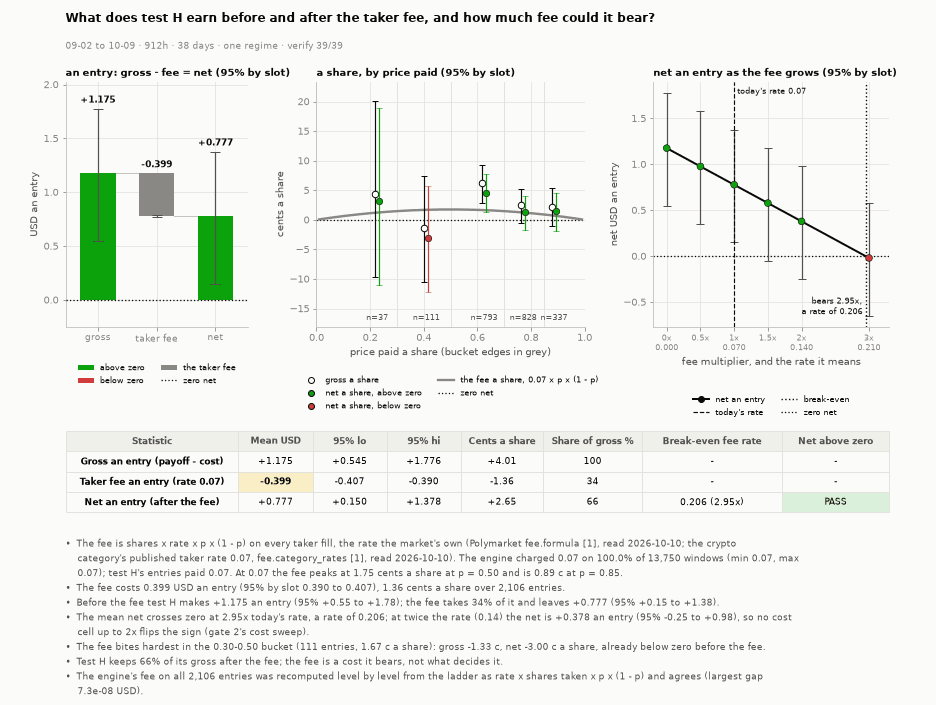

In [108]:
_ok, _err, _nf = FE.fee_check(TAB, E_, FE.limits(TAB, E_), usd=CLIP_USD)
assert _ok, f"test {LAB}: the engine's fee disagrees with rate x p x (1 - p) taken level by level (largest gap {_err:.2e} USD)"
_sw = FE.sweep(E_)
assert not FE.sweep_faults(_sw, E_), FE.sweep_faults(_sw, E_)
_d, _px = FE.decompose(TAB, E_), FE.by_price(E_)
FEES[LAB] = dict(d=_d, sw=_sw, px=_px)
_win = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_notes = FE.fee_notes(LAB, _d, _sw, FEE_RATES, _px) + [f"The engine's fee on all {_nf:,} entries was recomputed level by level from the ladder as rate x shares taken x p x (1 - p) and agrees (largest gap {_err:.1e} USD)."]
figstyle.show(FE.fee_fig(_d, _sw, _px, _notes, f"What does test {LAB} earn before and after the taker fee, and how much fee could it bear?", _win), f"fig:s3-{LAB.lower()}-fees", FIGURES)

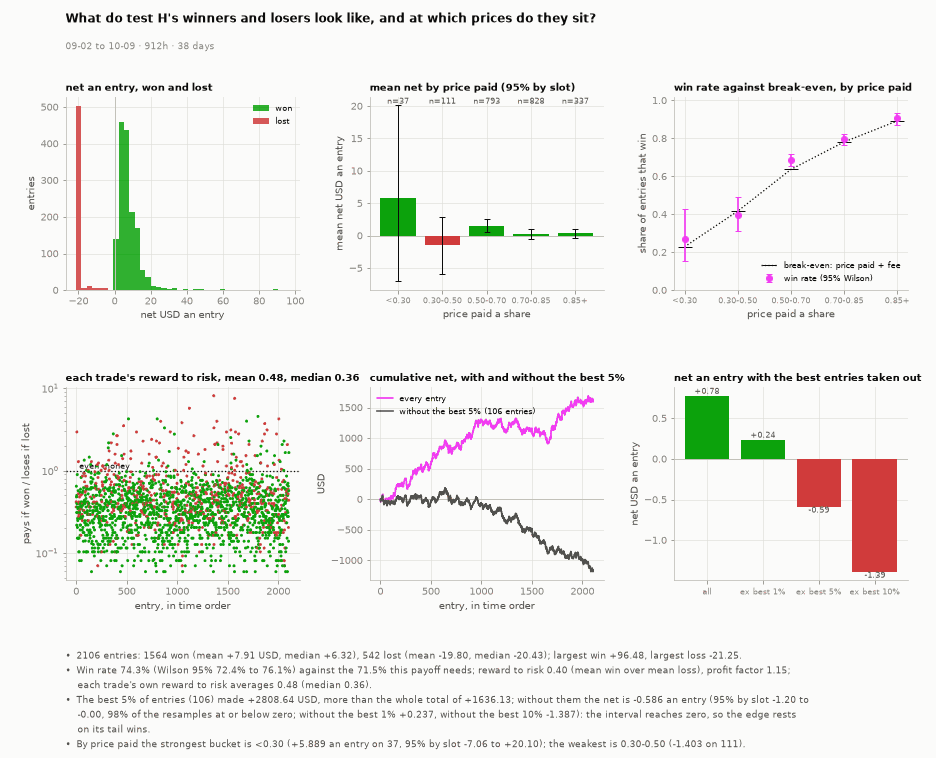

In [109]:
figstyle.show(TF.winloss_fig(E_, DAYS, question=f"What do test {LAB}'s winners and losers look like, and at which prices do they sit?"), "fig:s3-h-winloss", FIGURES)

In [110]:
_ord = np.argsort(E_["net"])
display(Markdown(f"**The {TOP_N} best entries of test {LAB}** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)"))
display(HTML(trades_df(E_, _ord[::-1][:TOP_N]).round(3).to_html(index=False, border=0)))
display(Markdown(f"**The {TOP_N} worst entries of test {LAB}**"))
display(HTML(trades_df(E_, _ord[:TOP_N]).round(3).to_html(index=False, border=0)))

**The 10 best entries of test H** (second: the decision second from the window's start; usd_at_risk: the cost of a buy, or the collateral of a sale)

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-10-04,eth,Down,buy near,520,380,0.170,117.64,19.999,1.162,True,96.479
2026-09-15,btc,Up,buy near,379,521,0.180,111.11,20.000,1.148,True,89.962
2026-09-12,eth,Up,buy near,545,355,0.180,111.11,20.000,1.148,True,89.962
2026-10-03,eth,Up,buy near,137,763,0.190,105.52,19.999,1.135,True,84.387
2026-09-17,eth,Down,buy near,555,345,0.220,90.90,19.998,1.092,True,69.810
2026-09-09,eth,Down,buy near,70,830,0.250,80.00,20.000,1.050,True,58.950
2026-09-19,sol,Down,buy near,286,614,0.251,79.61,19.999,1.048,True,58.563
2026-10-01,eth,Up,buy near,556,344,0.270,74.07,19.999,1.022,True,53.049
2026-10-08,eth,Up,buy near,397,503,0.290,68.96,19.998,0.994,True,47.968
2026-10-03,xrp,Up,buy near,196,704,0.290,68.96,19.998,0.994,True,47.968


**The 10 worst entries of test H**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-27,btc,Down,buy near,585,315,0.103,193.99,19.999,1.255,False,-21.254
2026-10-07,eth,Up,buy near,166,734,0.180,111.11,20.000,1.148,False,-21.148
2026-09-28,eth,Up,buy near,573,327,0.190,105.26,19.999,1.134,False,-21.133
2026-09-16,eth,Up,buy near,375,525,0.190,105.26,19.999,1.134,False,-21.133
2026-09-11,xrp,Up,buy near,460,440,0.210,95.23,19.998,1.106,False,-21.104
2026-09-27,eth,Down,buy near,585,315,0.220,90.90,19.998,1.092,False,-21.090
2026-10-01,eth,Down,buy near,521,379,0.230,86.95,19.999,1.078,False,-21.076
2026-09-30,btc,Up,buy near,189,711,0.240,83.33,19.999,1.064,False,-21.063
2026-10-02,eth,Down,buy near,508,392,0.240,83.33,19.999,1.064,False,-21.063
2026-09-02,eth,Up,buy near,332,568,0.240,83.33,19.999,1.064,False,-21.063


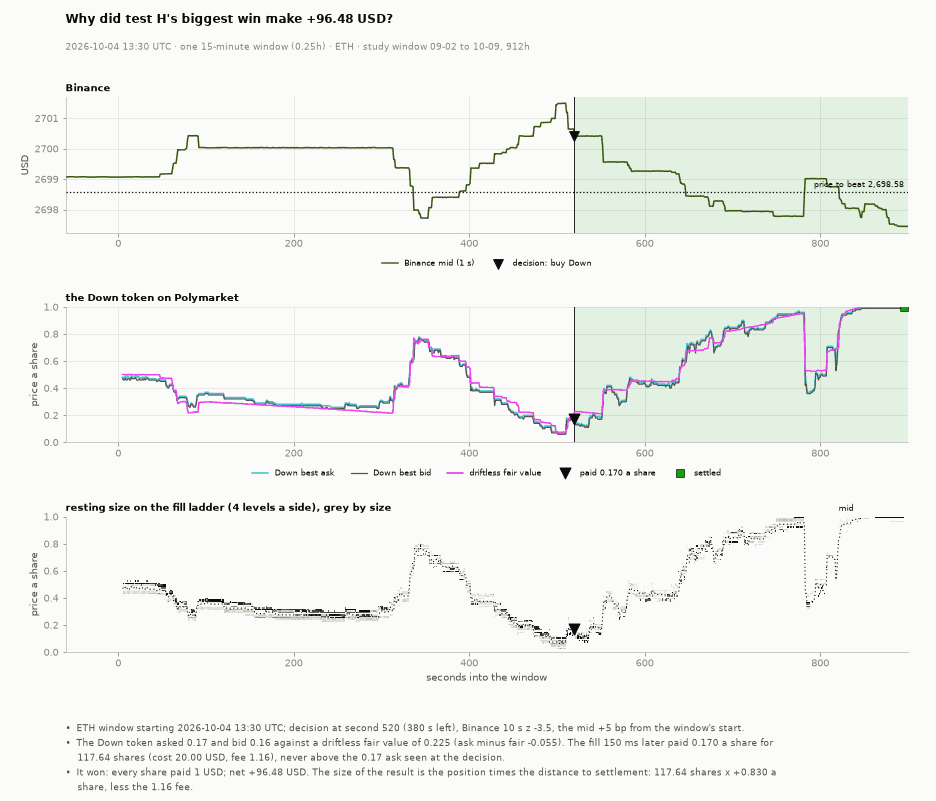

**Fill ladder at second 520 + 150 ms, ETH Down token: a buy of 20 USD of Down at no worse than the 0.17 ask seen at the decision; fair value 0.225; took 117.64 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,25.00,0.16,0.17,136.88,117.64,19.9988
2,5.01,0.15,0.18,45.00,0.00,0.0000
3,55.07,0.14,0.19,165.00,0.00,0.0000
4,170.00,0.13,0.20,145.00,0.00,0.0000


In [111]:
_i = int(np.argmax(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest win make {E_['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-h-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

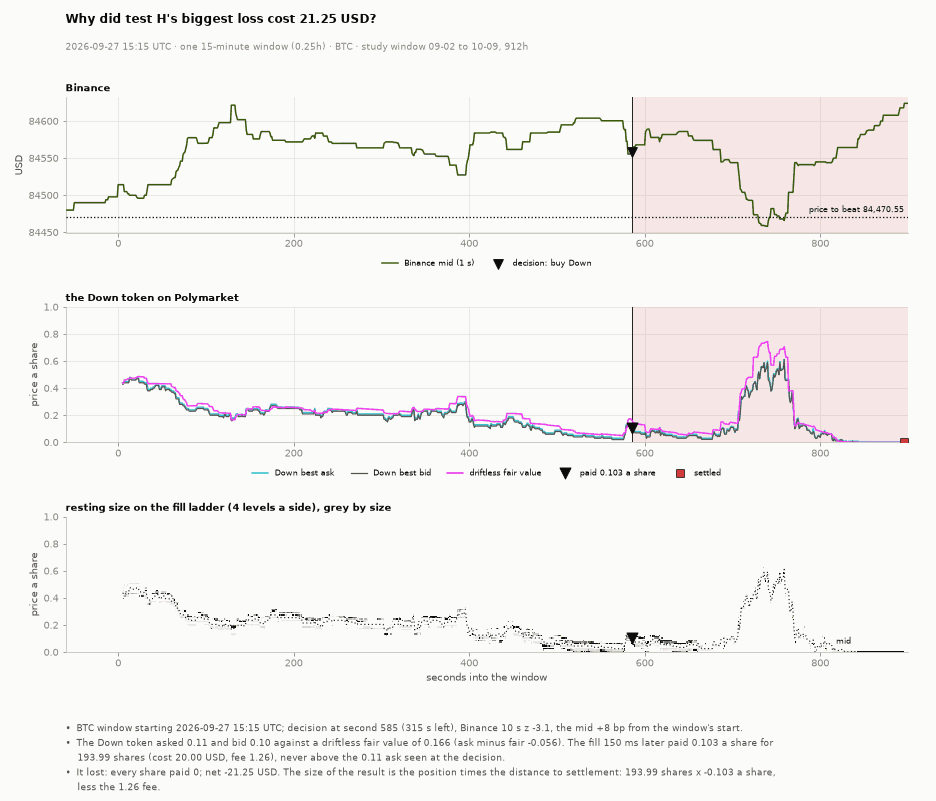

**Fill ladder at second 585 + 150 ms, BTC Down token: a buy of 20 USD of Down at no worse than the 0.11 ask seen at the decision; fair value 0.166; took 193.99 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,139.83,0.09,0.10,134.00,134.00,13.4000
2,291.20,0.08,0.11,106.38,59.99,6.5989
3,832.71,0.07,0.12,91.38,0.00,0.0000
4,5671.00,0.06,0.13,103.79,0.00,0.0000


In [112]:
_i = int(np.argmin(E_["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_, _i, DAYS, question=f"Why did test {LAB}'s biggest loss cost {-E_['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-h-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**"))
display(HTML(_df.round(4).to_html(index=False, border=0)))

#### H · S5 Out of sample and luck

The rule is fixed and nothing in it is fitted, so in-sample here means only the days that set the forecast: the in-sample block gives the net an entry and
its 95% interval by 15-minute slot, and each out-of-sample block is the realisation read against it. A steady edge keeps its sign and lands inside the
forecast's interval. First two weeks against the next two (the seated days after them are a second out-of-sample block), then each week against the next,
then the test against the random-burst null: the same count of entries in each day and coin, at seconds that pass every condition of the test except the
burst, the side the one whose ask passes the gate. A coin flip of the side at the test's own seconds is printed beside it; it buys the far token, which never
passes the gate, so it measures the gate and is not a gate itself.

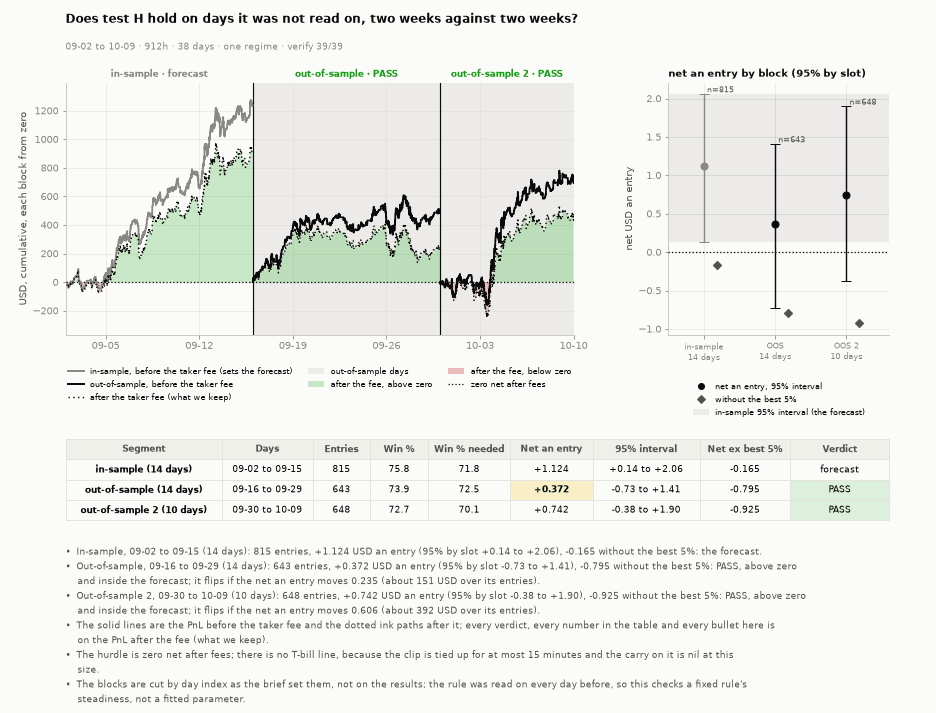

In [113]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = OOS2W[LAB] = O.read_blocks(E_, DAYS, N_IS, N_OOS)
figstyle.show(OF.oos2w_fig(E_, DAYS, _r, OF.block_notes(_r, O.MIN_N), f"Does test {LAB} hold on days it was not read on, two weeks against two weeks?", WIN_),
              f"fig:s3-{LAB.lower()}-oos2w", FIGURES)

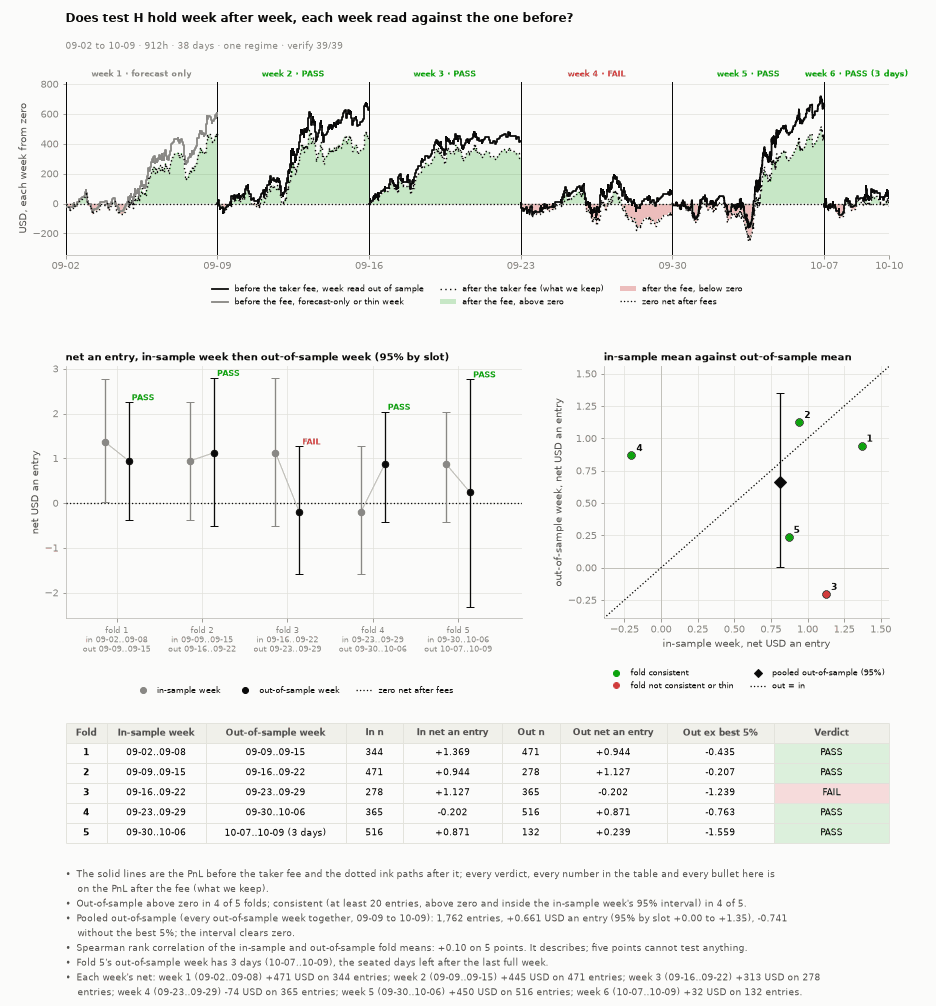

In [114]:
_f = FOLDS[LAB] = O.read_folds(E_, DAYS, WEEK)
figstyle.show(OF.folds_fig(E_, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), f"Does test {LAB} hold week after week, each week read against the one before?", WIN_),
              f"fig:s3-{LAB.lower()}-oosfolds", FIGURES)

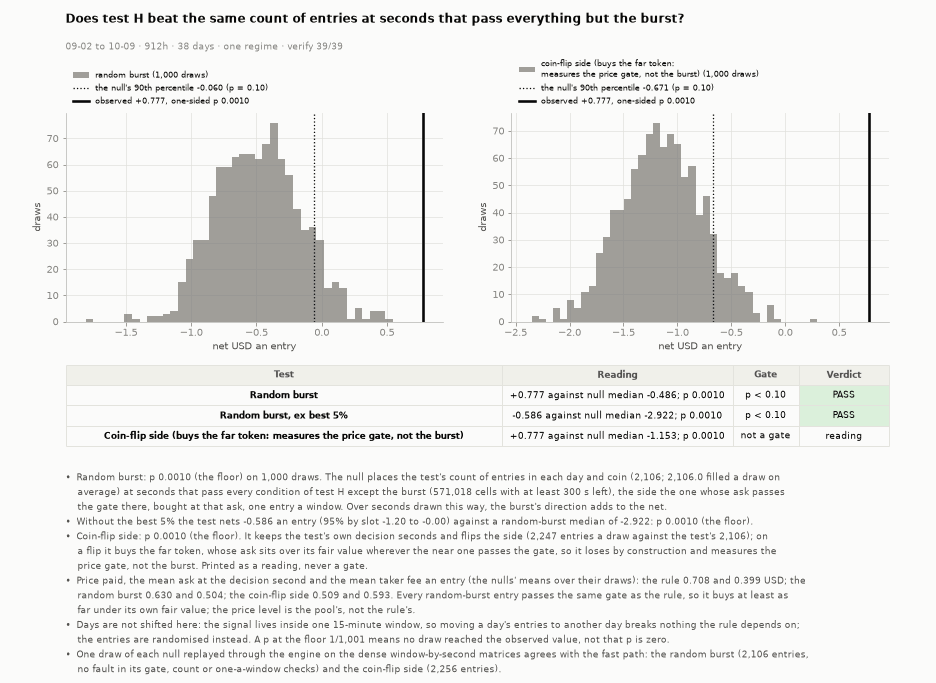

In [115]:
# the random-burst null (the gate: does the burst's direction add to a book that passes everything else?) and the coin-flip side (a reading of the price gate)
_rs = O.random_side(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD, draws=N_DRAWS, seed=11 + LABELS.index(LAB))
_rb = O.random_burst(TAB, E_, _m, LAB, t_min=T_MIN, usd=CLIP_USD, draws=N_DRAWS, seed=13 + LABELS.index(LAB))
_ok_s, _n_s = O.side_agrees(TAB, _m["gates"][LAB], _m["tm"], usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_, _m, LAB, theta=None if LAB == "C" else THETA, t_min=T_MIN, usd=CLIP_USD)
assert _ok_s and (_ag is None or (_ag["agree"] and not _ag["faults"])), f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
if _rb is None:
    print(f"{LAB} has no burst to randomise: the random-burst null is skipped, only the coin-flip side is drawn")
_ask = O.ask_of(TAB, E_)
_p = dict(burst=O.p_one_sided(_rb["per"], S_["per"]) if _rb else float("nan"), burst_ex5=O.p_one_sided(_rb["ex5"], S_["per_ex_top5"]) if _rb else float("nan"),
          side=O.p_one_sided(_rs["per"], S_["per"]), side_ex5=O.p_one_sided(_rs["ex5"], S_["per_ex_top5"]))
RAND[LAB] = dict(p_burst=_p["burst"], p_burst_ex5=_p["burst_ex5"], p_side=_p["side"], p_side_ex5=_p["side_ex5"], draws=N_DRAWS,
                 ask_rule=float(_ask.mean()), fee_rule=float(S_["fee_per"]), ask_side=float(np.nanmean(_rs["ask"])), fee_side=float(np.nanmean(_rs["fee"])),
                 ask_burst=float(np.nanmean(_rb["ask"])) if _rb else float("nan"), fee_burst=float(np.nanmean(_rb["fee"])) if _rb else float("nan"))
_rows, _notes = OF.burst_rows(LAB, S_, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, T_MIN, dict(burst=_ag, side=(_ok_s, _n_s)))
_nulls = (([dict(name="random burst", null=_rb["per"], observed=S_["per"], p=_p["burst"])] if _rb else [])
          + [dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=S_["per"], p=_p["side"])])
_q = (f"Does test {LAB} beat the same count of entries at seconds that pass everything but the burst?" if _rb else
      f"Does test {LAB} beat a coin flip of its side? It has no burst to randomise")
figstyle.show(OF.random_fig(_nulls, _rows, _notes, _q, WIN_, colw=OF.BURST_COLW), f"fig:s3-{LAB.lower()}-random", FIGURES)

## S4 · Robustness

The shape of test A's edge against its margin; the seven tests are compared side by side in S7.

In [116]:
# ---- test A's gate at other margins: the shape of the edge, not a search (the study's margin is the brief's 5 cents) ----
SWEEP = pd.DataFrame(C.near_gate_sweep(TAB, L=L, z_min=Z_MIN, t_min=T_MIN, usd=CLIP_USD))
SWEEP["win"] = SWEEP["win"] * 100; SWEEP["breakeven"] = SWEEP["breakeven"] * 100
display(Markdown("**Test A's gate at other margins** (theta = how far under fair the near ask must sit; the 0.05 row is the study)"))
display(HTML(SWEEP.round(3).to_html(index=False, border=0)))

**Test A's gate at other margins** (theta = how far under fair the near ask must sit; the 0.05 row is the study)

theta,n,win,breakeven,per,lo,hi,net
0.00,8757,65.365,61.968,-0.152,-0.458,0.159,-1330.776
0.01,7549,65.452,61.223,0.008,-0.332,0.353,58.215
0.02,6210,65.845,60.884,0.181,-0.201,0.592,1123.575
0.03,4933,66.187,61.341,0.289,-0.149,0.714,1424.141
0.05,2898,68.323,61.968,0.620,0.134,1.109,1798.172
0.07,1682,71.403,64.827,0.886,0.280,1.503,1490.570
0.10,761,71.748,64.568,1.242,0.321,2.127,945.384
0.15,278,69.784,58.675,1.961,0.162,3.619,545.171


## S5 · Risk and diagnostics

The day-by-day record of each test, the worst day and the largest single loss.

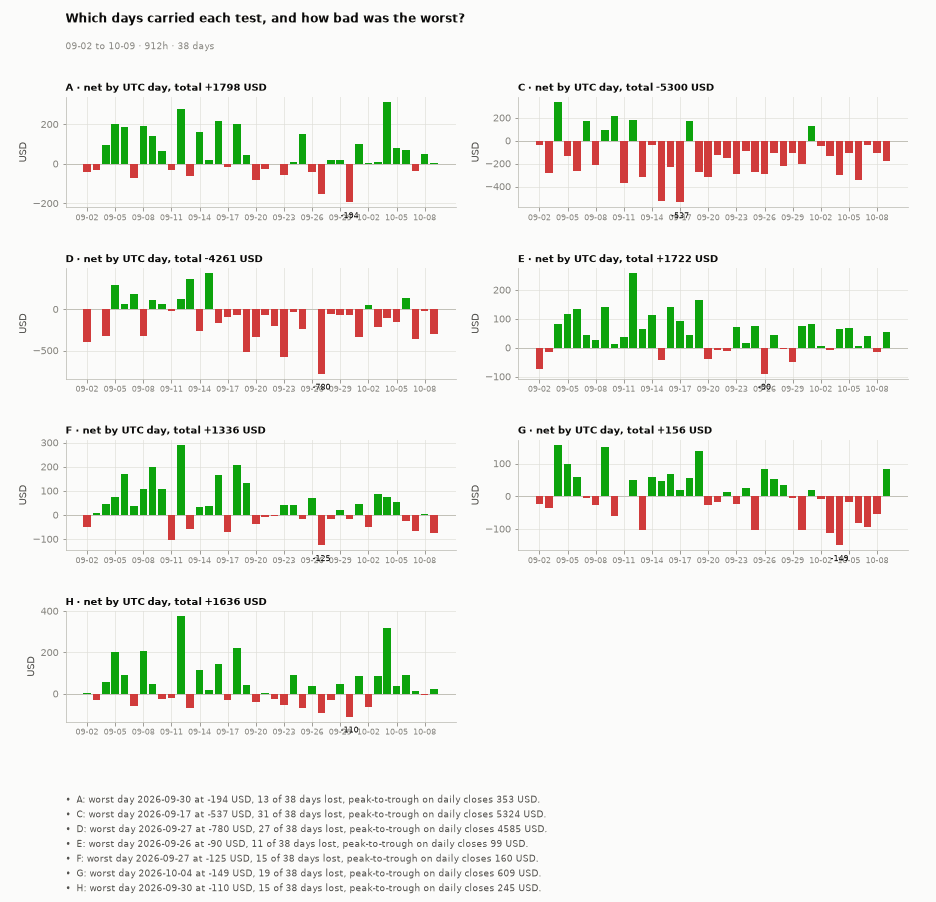

In [117]:
figstyle.show(TF.daily_fig(TESTS, DAYS), "fig:s5-daily", FIGURES)

In [118]:
_risk = []
for k in LABELS:
    e = TESTS[k]
    d = np.bincount(e["day"], weights=e["net"], minlength=len(DAYS))
    eq = np.cumsum(e["net"]); peak = np.maximum.accumulate(np.concatenate([[0.0], eq]))[1:]
    _risk.append(dict(test=k, worst_day_usd=float(d.min()), worst_day=DAYS[int(np.argmin(d))], days_lost=int((d < 0).sum()), largest_loss_usd=float(e["net"].min()),
                      max_drawdown_usd=float((peak - eq).max()), max_drawdown_pct_of_book=float((peak - eq).max() / BOOK_USD * 100),
                      max_usd_at_risk_one_entry=float(e["cost"].max())))
RISK = pd.DataFrame(_risk)
display(HTML(RISK.round(2).to_html(index=False, border=0)))

test,worst_day_usd,worst_day,days_lost,largest_loss_usd,max_drawdown_usd,max_drawdown_pct_of_book,max_usd_at_risk_one_entry
A,-194.27,2026-09-30,13,-21.30,496.78,49.68,20.0
C,-537.34,2026-09-17,31,-21.32,5550.82,555.08,20.0
D,-780.35,2026-09-27,27,-21.30,4647.17,464.72,20.0
E,-89.74,2026-09-26,11,-21.22,136.51,13.65,20.0
F,-124.89,2026-09-27,15,-21.30,275.86,27.59,20.0
G,-149.48,2026-10-04,19,-21.30,710.34,71.03,20.0
H,-109.99,2026-09-30,15,-21.25,413.67,41.37,20.0


## S6 · Decision

In [119]:
_best = max(LABELS, key=lambda k: SUMM[k]["per"])
_clears = [k for k in LABELS if SUMM[k]["per_lo"] > 0]
_both = [k for k in LABELS if SUMM_F[k].get("per", -1) > 0 and SUMM_S[k].get("per", -1) > 0]

def oos_read(lab):
    """One sentence on a test's S5 reads: the out-of-sample blocks, the weekly folds and the randomised nulls."""
    r, f, q = OOS2W[lab], FOLDS[lab], RAND[lab]
    o1, o2, pl = r[1], (r[2] if len(r) > 2 else None), f["pooled"]
    return (f"the out-of-sample two weeks net {o1['s'].get('per', float('nan')):+.3f} an entry on {o1['s'].get('n', 0):,} entries ({o1['verdict']} against the in-sample forecast "
            f"{r[0]['s']['per_lo']:+.2f} to {r[0]['s']['per_hi']:+.2f})" + (f" and the last {o2['n_days']} days {o2['s'].get('per', float('nan')):+.3f} ({o2['verdict']})" if o2 else "")
            + f"; week against week {f['consistent']} of {f['n_folds']} folds are consistent and the pooled out-of-sample weeks net {pl.get('per', float('nan')):+.3f} an entry "
            f"(95% {pl.get('per_lo', float('nan')):+.2f} to {pl.get('per_hi', float('nan')):+.2f}); "
            + (f"against the random-burst null (the same count of entries at seconds that pass every condition but the burst) the one-sided p is {q['p_burst']:.4f} "
               f"({q['p_burst_ex5']:.4f} for the net without the best 5%)" if np.isfinite(q["p_burst"]) else f"test {lab} has no burst to randomise")
            + f", and against the coin-flip side, which buys the far token and so measures the price gate rather than the burst, {q['p_side']:.4f}")

def ex5_words(s):
    """The net without the best 5% with its slot interval and the share of resamples at or below zero."""
    return (f"{s['per_ex_top5']:+.3f} an entry (95% by 15-minute slot {s['per_ex_top5_lo']:+.2f} to {s['per_ex_top5_hi']:+.2f}, "
            f"{s['p_ex_top5_le0']:.0%} of the resamples at or below zero)")

OOS_PASS = {k: dict(g10=OOS2W[k][1]["verdict"] == "PASS", g11=FOLDS[k]["pooled"].get("per", -1) > 0 and FOLDS[k]["consistent"] >= 3,
                    g12=bool(np.isfinite(RAND[k]["p_burst"]) and RAND[k]["p_burst"] < P_GATE)) for k in LABELS}
_ok3 = sum(OOS_PASS[_best].values())
DECISION_MD = (f"**No size.** " + (f"Test {', '.join(_clears)} clears zero on the whole window" if _clears else "No test's net-an-entry interval clears zero on the whole window") +
               f"; test {_best} is the strongest expression ({SUMM[_best]['per']:+.3f} USD an entry, 95% {SUMM[_best]['per_lo']:+.2f} to {SUMM[_best]['per_hi']:+.2f}) and "
               f"{'is' if _best in _both else 'is not'} positive on both halves"
               + (f", but a few wins carry it: without its best 5% of entries it nets {ex5_words(SUMM[_best])}, so no size rests on it until a rule earns its net without the tail wins. "
                  if SUMM[_best]["per_ex_top5_lo"] <= 0 else f" and survives without its best 5% ({ex5_words(SUMM[_best])}). ") +
               "A size waits for days this window did not see (the forward days from 2026-10-08 as they seat), read once with the rule frozen as it stands here. "
               f"Inside the window, test {_best} passes " + ("all three" if _ok3 == 3 else f"{_ok3} of the three") + " S5 gates (G10 to G12): " + oos_read(_best) + ". "
               + ("These reads support taking the forward read, but they are consistency checks inside one window and do not replace it."
                  if _ok3 == 3 else "So the window's own splits give no reason to size ahead of the forward days."))
display(Markdown(DECISION_MD))

**No size.** Test A, E, F, H clears zero on the whole window; test E is the strongest expression (+1.365 USD an entry, 95% +0.68 to +2.07) and is positive on both halves, but a few wins carry it: without its best 5% of entries it nets +0.041 an entry (95% by 15-minute slot -0.58 to +0.70, 44% of the resamples at or below zero), so no size rests on it until a rule earns its net without the tail wins. A size waits for days this window did not see (the forward days from 2026-10-08 as they seat), read once with the rule frozen as it stands here. Inside the window, test E passes all three S5 gates (G10 to G12): the out-of-sample two weeks net +1.217 an entry on 370 entries (PASS against the in-sample forecast +0.67 to +2.60) and the last 10 days +1.101 (PASS); week against week 4 of 5 folds are consistent and the pooled out-of-sample weeks net +1.361 an entry (95% +0.60 to +2.18); against the random-burst null (the same count of entries at seconds that pass every condition but the burst) the one-sided p is 0.0010 (0.0010 for the net without the best 5%), and against the coin-flip side, which buys the far token and so measures the price gate rather than the burst, 0.0010. These reads support taking the forward read, but they are consistency checks inside one window and do not replace it.

## S7 · Verdict

In [120]:
_best = max(LABELS, key=lambda k: SUMM[k]["per"])
_clears = [k for k in LABELS if SUMM[k]["per_lo"] > 0]
WORD = "MONEY" if _clears else ("class B" if SUMM[_best]["per"] > 0 else "class C")
_s = SUMM[_best]
VERDICT_MD = (f"**The answer: {WORD}.** Of the seven tests, test {_best} ({C.TESTS[_best][0]}) is the strongest: {_s['n']:,} entries, win {_s['win']*100:.1f}% against "
              f"{_s['breakeven']*100:.1f}% to break even, net {_s['per']:+.3f} USD an entry (95% by 15-minute slot {_s['per_lo']:+.2f} to {_s['per_hi']:+.2f}), {_s['net']:+.0f} USD in all; "
              f"first half {SUMM_F[_best].get('per', float('nan')):+.3f} an entry, second half {SUMM_S[_best].get('per', float('nan')):+.3f}. "
              f"Of the four added signals (E a book that has not moved {SUMM['E']['per']:+.3f}, F breadth {SUMM['F']['per']:+.3f}, G Bitcoin's lead {SUMM['G']['per']:+.3f}, H depth at the touch {SUMM['H']['per']:+.3f}), "
              + ("none beats A on both the net an entry and the net without its best 5%. " if not [k for k in 'EFGH' if SUMM[k]['per'] > SUMM['A']['per'] and SUMM[k]['per_ex_top5'] > SUMM['A']['per_ex_top5']] else ", ".join(k for k in 'EFGH' if SUMM[k]['per'] > SUMM['A']['per'] and SUMM[k]['per_ex_top5'] > SUMM['A']['per_ex_top5']) + " beat A on both. ")
              + f"Momentum without the price gate (C, {SUMM['C']['per']:+.3f}) and the price gate without momentum (D, {SUMM['D']['per']:+.3f}) both lose, so the thesis needs both: a burst AND a book "
              f"that has not re-priced it. "
              f"Win rate {_s['win']*100:.1f}% against the {_s['win_needed']*100:.1f}% its payoff needs, reward to risk {_s['rr']:.2f} (mean win {_s['avg_win']:+.2f}, mean loss {_s['avg_loss']:+.2f}), "
              f"profit factor {_s['pf']:.2f}, each trade's own reward to risk {_s['rr_trade_mean']:.2f} on average. "
              + (f"**{'A few wins carry everything' if _s['per_ex_top5'] <= 0 else 'Without its best wins the edge cannot be told from zero'}:** without its best 5% of entries test {_best} nets "
                 f"{ex5_words(_s)}, and {_s['top5_share']*100:.0f}% of the net sits in {int(np.ceil(0.05 * _s['n']))} entries, so the edge as it stands is a tail-win edge, not a steady one. "
                 if _s["per_ex_top5_lo"] <= 0 else f"Without its best 5% of entries test {_best} still nets {ex5_words(_s)}: the edge is not a few wins. ")
              + f"On days it was not read on and against chance (S5), " + oos_read(_best) + ": "
              + {3: "steady inside the window. ", 0: "none of the three holds. "}.get(sum(OOS_PASS[_best].values()), f"{sum(OOS_PASS[_best].values())} of the three hold. ")
              + ("The interval clears zero." if _clears else "No interval clears zero: real in sign but not yet confirmable, it wants more days, not more parameters."))
display(Markdown(VERDICT_MD))

**The answer: MONEY.** Of the seven tests, test E (A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet) is the strongest: 1,261 entries, win 75.0% against 65.2% to break even, net +1.365 USD an entry (95% by 15-minute slot +0.68 to +2.07), +1722 USD in all; first half +1.865 an entry, second half +0.746. Of the four added signals (E a book that has not moved +1.365, F breadth +0.696, G Bitcoin's lead +0.126, H depth at the touch +0.777), E, F, H beat A on both. Momentum without the price gate (C, -0.471) and the price gate without momentum (D, -0.357) both lose, so the thesis needs both: a burst AND a book that has not re-priced it. Win rate 75.0% against the 68.8% its payoff needs, reward to risk 0.45 (mean win +6.83, mean loss -15.06), profit factor 1.36, each trade's own reward to risk 0.89 on average. **Without its best wins the edge cannot be told from zero:** without its best 5% of entries test E nets +0.041 an entry (95% by 15-minute slot -0.58 to +0.70, 44% of the resamples at or below zero), and 97% of the net sits in 64 entries, so the edge as it stands is a tail-win edge, not a steady one. On days it was not read on and against chance (S5), the out-of-sample two weeks net +1.217 an entry on 370 entries (PASS against the in-sample forecast +0.67 to +2.60) and the last 10 days +1.101 (PASS); week against week 4 of 5 folds are consistent and the pooled out-of-sample weeks net +1.361 an entry (95% +0.60 to +2.18); against the random-burst null (the same count of entries at seconds that pass every condition but the burst) the one-sided p is 0.0010 (0.0010 for the net without the best 5%), and against the coin-flip side, which buys the far token and so measures the price gate rather than the burst, 0.0010: steady inside the window. The interval clears zero.

### The seven tests compared

The rule (A) against its two halves (C the burst alone, D the gate alone) and against the four added signals (E a book that has not moved, F breadth,
G Bitcoin's lead, H depth at the touch), on the whole window, on both halves of it, by coin, by the shape of the payoff and by what is left once the
best 5% of entries are out. Every number is computed above; nothing here is typed.

In [121]:
_cmp_rows = []
for k in LABELS:
    s_, sf_, ss_, e_ = SUMM[k], SUMM_F[k], SUMM_S[k], TESTS[k]
    _cmp_rows.append(dict(test=k, what=C.TESTS[k][0], n=s_["n"], win_pct=s_["win"] * 100, win_needed_pct=s_["win_needed"] * 100, reward_to_risk=s_["rr"], rr_per_trade=s_["rr_trade_mean"],
                          profit_factor=s_["pf"], gross_per_entry=s_["gross_per"], fee_per_entry=s_["fee_per"], per_entry=s_["per"], lo=s_["per_lo"], hi=s_["per_hi"], per_ex_best5=s_["per_ex_top5"], per_ex_best5_lo=s_["per_ex_top5_lo"], per_ex_best5_hi=s_["per_ex_top5_hi"], first_half=sf_.get("per", np.nan), second_half=ss_.get("per", np.nan),
                          days_above_zero=int((np.bincount(e_["day"], weights=e_["net"], minlength=len(DAYS)) > 0).sum()), net=s_["net"],
                          **{f"{a.upper()}_per_entry": (B.summarize(B.subset(e_, e_["asset"] == ai), TAB, a).get("per", np.nan) if (e_["asset"] == ai).any() else np.nan) for ai, a in enumerate(ASSET)},
                          oos2w_per_entry=OOS2W[k][1]["s"].get("per", np.nan), folds_oos_pooled=FOLDS[k]["pooled"].get("per", np.nan),
                          p_random_burst=RAND[k]["p_burst"], p_coinflip_side=RAND[k]["p_side"]))
CMP_TABLE = pd.DataFrame(_cmp_rows)
display(Markdown(f"**Side by side, whole window** (per entry in USD; gross_per_entry: the payoff less the cost, before the fee; fee_per_entry: the taker fee; per_entry = gross - fee; 95% interval by 15-minute slot; per_ex_best5: the net an entry without the best 5% of entries, per_ex_best5_lo and _hi its 95% interval with the trim recomputed in each slot resample; days_above_zero of {len(DAYS)}; "
                 f"oos2w_per_entry: the net an entry on the out-of-sample two weeks ({DAYS[N_IS][5:]} to {DAYS[N_IS + N_OOS - 1][5:]}); folds_oos_pooled: every out-of-sample week together; "
                 f"p_random_burst: the one-sided p against {N_DRAWS:,} draws of the same count of entries at seconds that pass every condition but the burst (D has none); "
                 f"p_coinflip_side: the same against a coin flip of the side at the test's own seconds, which buys the far token and measures the price gate, not the burst)"))
display(HTML(CMP_TABLE.round(3).to_html(index=False, border=0)))
_a, _c, _d = SUMM["A"], SUMM["C"], SUMM["D"]
_gate_worth = _a["per"] - _c["per"]
_burst_worth = _a["per"] - _d["per"]
_added = {k: SUMM[k] for k in ("E", "F", "G", "H") if SUMM[k].get("n")}
_better = [k for k, s_ in _added.items() if s_["per_ex_top5"] > _a["per_ex_top5"] and s_["per"] > _a["per"]]
display(Markdown(f"**What the tests say.** The gate is worth {_gate_worth:+.2f} USD an entry (A {_a['per']:+.3f} against C {_c['per']:+.3f}: the same bursts, with and without the price check) and the burst is worth "
                 f"{_burst_worth:+.2f} (A against D {_d['per']:+.3f}: the same price check, with and without the burst). "
                 + ("Neither half pays on its own and the two together do, so the edge is the conjunction: a burst the book has not re-priced yet. " if _c["per"] < 0 and _d["per"] < 0 < _a["per"] else "")
                 + "The added signals, each a subset of A's entries except G: " + "; ".join(f"{k} {C.TESTS[k][0].split(':')[0]} {s_['per']:+.3f} an entry on {s_['n']:,} ({s_['per_ex_top5']:+.3f} without the best 5%, win {s_['win']*100:.1f}% against {s_['win_needed']*100:.1f}% needed, {s_['days_pos']:.0%} of days up)" for k, s_ in _added.items()) + ". "
                 + (f"{', '.join(_better)} beat A on both the net an entry and the net without the best 5%; the rest do not. " if _better else "None beats A on both the net an entry and the net without the best 5%. ")
                 + f"A itself: {_a['per']:+.3f} an entry on {_a['n']:,}, {_a['per_ex_top5']:+.3f} without the best 5%, wins {_a['win']*100:.1f}% against {_a['win_needed']*100:.1f}% needed, {_a['days_pos']:.0%} of days up."))
RESULT_LINES = [f"RESULT {RUN_ID} {k}_entries={SUMM[k]['n']}" for k in LABELS] + [f"RESULT {RUN_ID} {k}_net_per_entry_usd={SUMM[k]['per']:.4f}" for k in LABELS] + [f"RESULT {RUN_ID} {k}_net_ex_best5_usd={SUMM[k]['per_ex_top5']:.4f}" for k in LABELS]
print("\n".join(RESULT_LINES))

**Side by side, whole window** (per entry in USD; gross_per_entry: the payoff less the cost, before the fee; fee_per_entry: the taker fee; per_entry = gross - fee; 95% interval by 15-minute slot; per_ex_best5: the net an entry without the best 5% of entries, per_ex_best5_lo and _hi its 95% interval with the trim recomputed in each slot resample; days_above_zero of 38; oos2w_per_entry: the net an entry on the out-of-sample two weeks (09-16 to 09-29); folds_oos_pooled: every out-of-sample week together; p_random_burst: the one-sided p against 1,000 draws of the same count of entries at seconds that pass every condition but the burst (D has none); p_coinflip_side: the same against a coin flip of the side at the test's own seconds, which buys the far token and measures the price gate, not the burst)

test,what,n,win_pct,win_needed_pct,reward_to_risk,rr_per_trade,profit_factor,gross_per_entry,fee_per_entry,per_entry,lo,hi,per_ex_best5,per_ex_best5_lo,per_ex_best5_hi,first_half,second_half,days_above_zero,net,BTC_per_entry,ETH_per_entry,SOL_per_entry,XRP_per_entry,oos2w_per_entry,folds_oos_pooled,p_random_burst,p_coinflip_side
A,Momentum and the near token's ASK under fair value: buy the near token,2898,68.323,65.524,0.526,0.919,1.135,0.974,0.353,0.620,0.134,1.109,-0.819,-1.250,-0.367,0.963,0.237,25,1798.172,0.518,1.155,0.113,0.531,0.327,0.529,0.001,0.001
C,Momentum only: buy the near token with no price gate,11250,63.982,65.978,0.516,0.758,0.916,-0.093,0.378,-0.471,-0.754,-0.165,-1.912,-2.187,-1.606,-0.405,-0.540,7,-5300.331,-0.330,-0.531,-0.356,-0.692,-0.699,-0.536,0.002,0.001
D,The price gate without momentum: buy the near token,11937,47.055,48.462,1.063,1.444,0.945,0.089,0.446,-0.357,-0.679,-0.035,-2.274,-2.583,-1.970,-0.142,-0.578,11,-4261.122,-0.579,-0.215,-0.338,-0.261,-0.759,-0.387,NaN,0.001
E,A's rule when the near token's ask is the same price it was 3 seconds ago: nobody has re-priced the book yet,1261,75.020,68.784,0.454,0.894,1.363,1.695,0.330,1.365,0.680,2.066,0.041,-0.577,0.697,1.865,0.746,27,1721.580,1.386,2.277,0.175,0.318,1.217,1.361,0.001,0.001
F,"A's rule when at least one other coin is bursting the same way at the same moment: the move is market-wide, not one coin's print",1918,68.405,65.144,0.535,1.010,1.158,1.040,0.344,0.696,0.050,1.347,-0.751,-1.328,-0.185,1.197,0.053,23,1335.792,0.628,1.141,0.462,0.250,0.662,0.601,0.003,0.001
G,"Bitcoin bursts: buy ETH, SOL or XRP's near token when that coin's own ask sits under its own fair value (the coin itself need not have burst)",1240,59.032,58.375,0.713,1.491,1.027,0.452,0.326,0.126,-0.658,0.953,-1.623,-2.278,-0.955,0.905,-0.827,19,156.190,NaN,0.420,0.035,-0.366,0.850,-0.062,0.073,0.001
H,A's rule when at least 20 USD of the near token is on offer at the best ask: our whole order fills at one price without walking up the book,2106,74.264,71.460,0.399,0.479,1.152,1.175,0.399,0.777,0.150,1.378,-0.586,-1.196,-0.003,1.190,0.364,23,1636.132,0.514,1.561,-0.338,1.620,0.372,0.661,0.001,0.001


**What the tests say.** The gate is worth +1.09 USD an entry (A +0.620 against C -0.471: the same bursts, with and without the price check) and the burst is worth +0.98 (A against D -0.357: the same price check, with and without the burst). Neither half pays on its own and the two together do, so the edge is the conjunction: a burst the book has not re-priced yet. The added signals, each a subset of A's entries except G: E A's rule when the near token's ask is the same price it was 3 seconds ago +1.365 an entry on 1,261 (+0.041 without the best 5%, win 75.0% against 68.8% needed, 71% of days up); F A's rule when at least one other coin is bursting the same way at the same moment +0.696 an entry on 1,918 (-0.751 without the best 5%, win 68.4% against 65.1% needed, 61% of days up); G Bitcoin bursts +0.126 an entry on 1,240 (-1.623 without the best 5%, win 59.0% against 58.4% needed, 50% of days up); H A's rule when at least 20 USD of the near token is on offer at the best ask +0.777 an entry on 2,106 (-0.586 without the best 5%, win 74.3% against 71.5% needed, 61% of days up). E, F, H beat A on both the net an entry and the net without the best 5%; the rest do not. A itself: +0.620 an entry on 2,898, -0.819 without the best 5%, wins 68.3% against 65.5% needed, 66% of days up.

RESULT um-021 A_entries=2898
RESULT um-021 C_entries=11250
RESULT um-021 D_entries=11937
RESULT um-021 E_entries=1261
RESULT um-021 F_entries=1918
RESULT um-021 G_entries=1240
RESULT um-021 H_entries=2106
RESULT um-021 A_net_per_entry_usd=0.6205
RESULT um-021 C_net_per_entry_usd=-0.4711
RESULT um-021 D_net_per_entry_usd=-0.3570
RESULT um-021 E_net_per_entry_usd=1.3652
RESULT um-021 F_net_per_entry_usd=0.6965
RESULT um-021 G_net_per_entry_usd=0.1260
RESULT um-021 H_net_per_entry_usd=0.7769
RESULT um-021 A_net_ex_best5_usd=-0.8192
RESULT um-021 C_net_ex_best5_usd=-1.9119
RESULT um-021 D_net_ex_best5_usd=-2.2744
RESULT um-021 E_net_ex_best5_usd=0.0409
RESULT um-021 F_net_ex_best5_usd=-0.7511
RESULT um-021 G_net_ex_best5_usd=-1.6234
RESULT um-021 H_net_ex_best5_usd=-0.5863


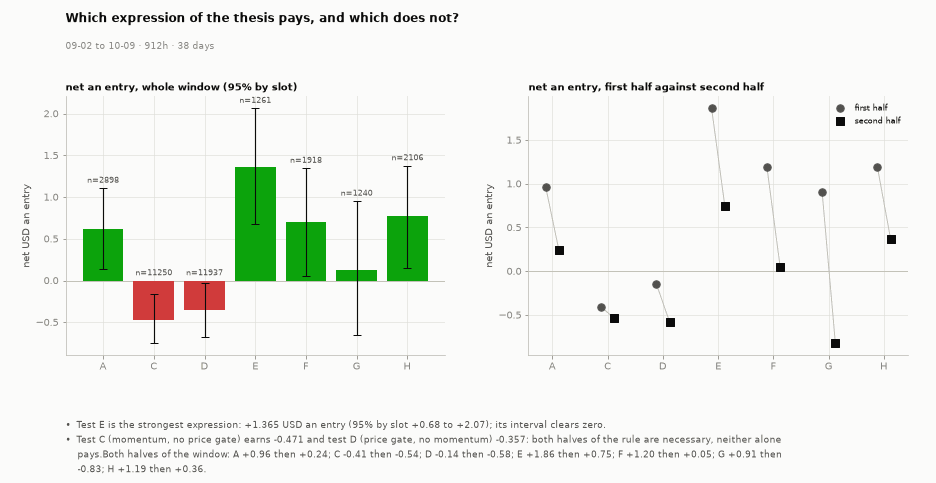

In [122]:
CMP = [dict(label=k, n=SUMM[k]["n"], per=SUMM[k]["per"], lo=SUMM[k]["per_lo"], hi=SUMM[k]["per_hi"], per_first=SUMM_F[k].get("per", np.nan), per_second=SUMM_S[k].get("per", np.nan)) for k in LABELS]
_best = max(LABELS, key=lambda k: SUMM[k]["per"])
_notes = [f"Test {_best} is the strongest expression: {SUMM[_best]['per']:+.3f} USD an entry (95% by slot {SUMM[_best]['per_lo']:+.2f} to {SUMM[_best]['per_hi']:+.2f}); " +
          ("its interval clears zero." if SUMM[_best]["per_lo"] > 0 else "its interval still spans zero."),
          f"Test C (momentum, no price gate) earns {SUMM['C']['per']:+.3f} and test D (price gate, no momentum) {SUMM['D']['per']:+.3f}: " +
          ("both halves of the rule are necessary, neither alone pays." if SUMM["C"]["per"] < 0 and SUMM["D"]["per"] < 0 else "one half of the rule pays on its own.") +

          f"Both halves of the window: " + "; ".join(f"{k} {SUMM_F[k].get('per', float('nan')):+.2f} then {SUMM_S[k].get('per', float('nan')):+.2f}" for k in LABELS) + "."]
figstyle.show(TF.compare_fig(CMP, DAYS, _notes), "fig:s7-compare", FIGURES)

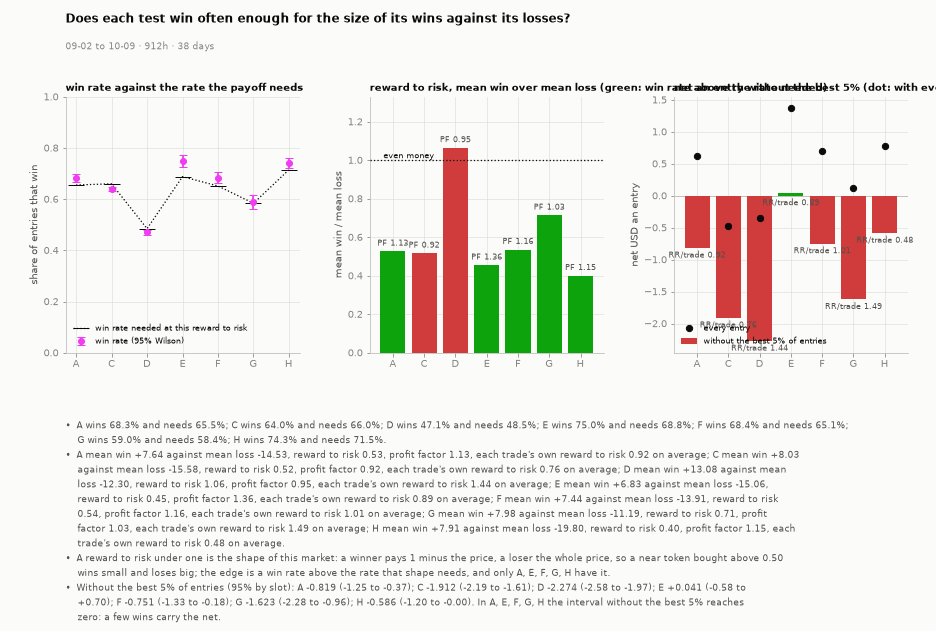

In [123]:
RR = [dict(label=k, win=SUMM[k]["win"], win_lo=SUMM[k]["win_lo"], win_hi=SUMM[k]["win_hi"], win_needed=SUMM[k]["win_needed"], rr=SUMM[k]["rr"], pf=SUMM[k]["pf"],
           avg_win=SUMM[k]["avg_win"], avg_loss=SUMM[k]["avg_loss"], per=SUMM[k]["per"], per_ex_top5=SUMM[k]["per_ex_top5"], rr_trade_mean=SUMM[k]["rr_trade_mean"]) for k in LABELS]
_carried = [r["label"] for r in RR if r["per"] > 0 >= SUMM[r["label"]]["per_ex_top5_lo"]]
_notes = ["; ".join(f"{r['label']} wins {r['win']:.1%} and needs {r['win_needed']:.1%}" for r in RR) + ".",
          "; ".join(f"{r['label']} mean win {r['avg_win']:+.2f} against mean loss {r['avg_loss']:+.2f}, reward to risk {r['rr']:.2f}, profit factor {r['pf']:.2f}, each trade's own reward to risk {r['rr_trade_mean']:.2f} on average" for r in RR) + ".",
          "A reward to risk under one is the shape of this market: a winner pays 1 minus the price, a loser the whole price, so a near token bought above 0.50 wins small and loses big; "
          "the edge is a win rate above the rate that shape needs, and only " + ", ".join(r["label"] for r in RR if r["win"] > r["win_needed"]) + " have it.",
          "Without the best 5% of entries (95% by slot): " + "; ".join(f"{r['label']} {r['per_ex_top5']:+.3f} ({SUMM[r['label']]['per_ex_top5_lo']:+.2f} to {SUMM[r['label']]['per_ex_top5_hi']:+.2f})" for r in RR) + ". "
          + (f"In {', '.join(_carried)} the interval without the best 5% reaches zero: a few wins carry the net." if _carried else "Every positive test's interval without its best 5% clears zero.")]
figstyle.show(TF.winrate_rr_fig(RR, DAYS, _notes), "fig:s7-winrr", FIGURES)

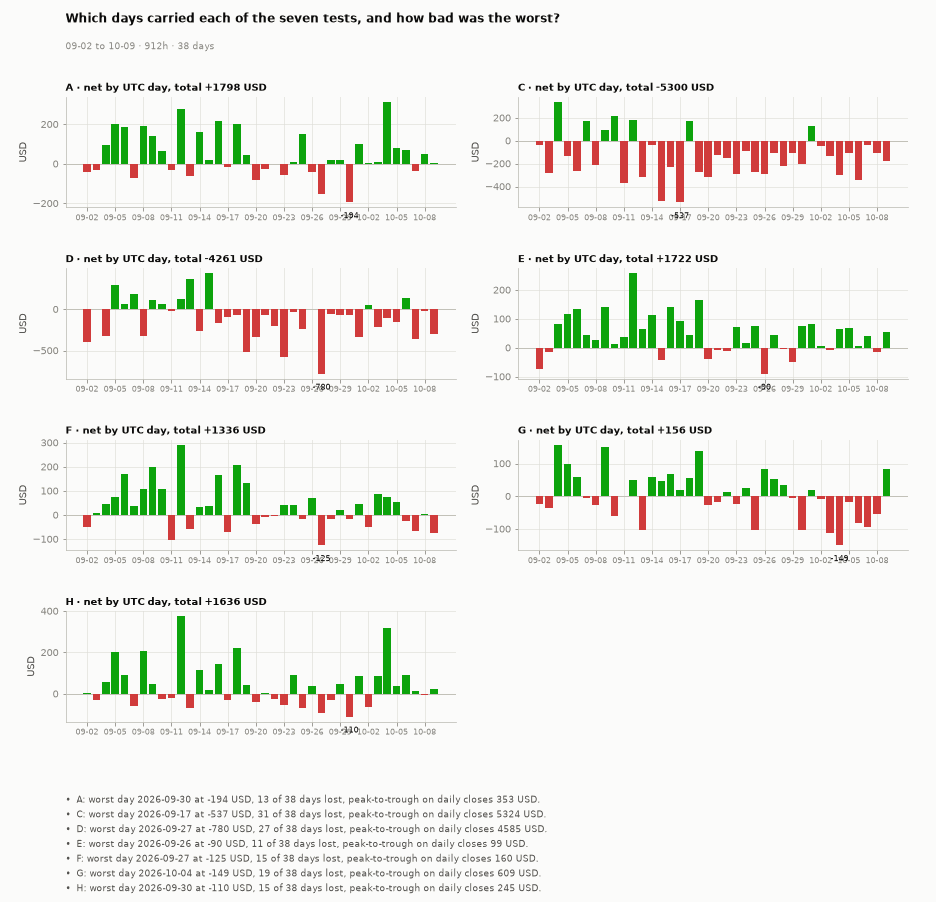

In [124]:
figstyle.show(TF.daily_fig(TESTS, DAYS, question="Which days carried each of the seven tests, and how bad was the worst?"), "fig:s7-daily3", FIGURES)

In [125]:
# ---- the study manifest fund.study/1 (the last cell) ----
import datetime as _dt
from fundplat.data import derived

TITLE = "Buying the near token after a Binance burst on 15-minute Up/Down: does it need the burst and the gate, and does a stale book, market breadth, Bitcoin's lead or the depth at the touch make it pay more?"
QUESTION = ("After a 3-sigma Binance burst, does buying the near token when its ask is more than 5 cents under the driftless fair value earn a positive net PnL an entry "
            "after the fee and a 250 ms delay (the venue's 150 ms hold plus 100 ms of our own), held to expiry; does either half of the rule, the burst alone or the gate alone, pay on its own; and does any of four signals that are not momentum "
            "(the near ask unchanged over 3 s, at least two coins bursting the same way in the slot, Bitcoin's burst for the alts' tokens, the whole clip resting at the best ask) earn more than the rule alone?")
KIND = "strategy"
RUN_AT = _dt.datetime.now(_dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
_ms = lambda d: int(_dt.datetime.strptime(d, "%Y-%m-%d").replace(tzinfo=_dt.timezone.utc).timestamp() * 1000)

_series, _pins = [], []
for d in DAYS:
    m_ = derived.meta("tf15-table", RUNNER.key_of(d, LAT_MS))
    _pins.append(m_["hash"])
    _series.append(dict(spec=f"tf15:{d}:decision-table:-", pin=m_["hash"], rows=int(COV.set_index("day").loc[d, "with_book"]),
                        first_ts=_ms(d), last_ts=_ms(d) + 86_399_999, handle=None, cls="pin", trunc=False))
INPUTS = {"digest": REPORT.inputs_digest(_pins), "series": _series, "unpinned": []}
WINDOW = {"from": "2026-09-02T00:00Z", "to": "2026-10-10T00:00Z", "hours": 912, "regimes": 1}
VERIFY = {"suite": "tf15 engine checks", "passed": int(VERIFY_PASSED), "total": int(VERIFY_TOTAL), "books": int(TAB.W)}
GATES = []
for i_, k in enumerate(LABELS, 1):
    s = SUMM[k]
    GATES.append({"id": f"G{i_}", "section": "S3", "label": f"Test {k} clears zero", "name": f"test {k}'s net an entry has a 95% interval by 15-minute slot above zero on the whole window",
                  "reading": f"{s['per']:+.3f} USD an entry ({s['per_lo']:+.2f} to {s['per_hi']:+.2f}) on {s['n']:,} entries", "verdict": "PASS" if s["per_lo"] > 0 else "FAIL",
                  "would_change": "an interval whose lower end crosses zero"})
_best = max(LABELS, key=lambda k: SUMM[k]["per"])
GATES.append({"id": "G8", "section": "S4", "label": "Best test, both halves", "name": f"test {_best}'s net an entry is positive on the first and the second half of the window",
              "reading": f"first half {SUMM_F[_best].get('per', float('nan')):+.3f}, second half {SUMM_S[_best].get('per', float('nan')):+.3f}",
              "verdict": "PASS" if (SUMM_F[_best].get("per", -1) > 0 and SUMM_S[_best].get("per", -1) > 0) else "FAIL", "would_change": "a half below zero"})
GATES.append({"id": "G9", "section": "S4", "label": "Survives without best 5%", "name": f"test {_best}'s net an entry with its best 5% of entries taken out has a 95% interval by 15-minute slot above zero, the trim recomputed inside each slot resample (a few wins must not carry everything)",
              "reading": f"{SUMM[_best]['per_ex_top5']:+.3f} USD an entry without the best 5% (95% by slot {SUMM[_best]['per_ex_top5_lo']:+.2f} to {SUMM[_best]['per_ex_top5_hi']:+.2f}, "
                         f"{SUMM[_best]['p_ex_top5_le0']:.0%} of the resamples at or below zero); {SUMM[_best]['top5_share']*100:.0f}% of the net sits in them; each trade's own reward to risk averages {SUMM[_best]['rr_trade_mean']:.2f}",
              "verdict": "PASS" if SUMM[_best]["per_ex_top5_lo"] > 0 else "FAIL", "would_change": "a lower end above zero once the best 5% are out"})
_r_, _f_, _q_ = OOS2W[_best], FOLDS[_best], RAND[_best]
_o1_, _pl_ = _r_[1], _f_["pooled"]
GATES.append({"id": "G10", "section": "S4", "label": "Best test, OOS 2w", "name": f"test {_best}'s out-of-sample two weeks ({_o1_['first'][5:]} to {_o1_['last'][5:]}) hold at least {O.MIN_N} entries, net above zero and inside the in-sample two weeks' 95% interval",
               "reading": f"{_o1_['s'].get('per', float('nan')):+.3f} USD an entry on {_o1_['s'].get('n', 0):,} entries against the forecast {_r_[0]['s']['per_lo']:+.2f} to {_r_[0]['s']['per_hi']:+.2f}"
                          + (f"; out-of-sample 2 ({_r_[2]['n_days']} days) {_r_[2]['s'].get('per', float('nan')):+.3f}, {_r_[2]['verdict']}" if len(_r_) > 2 else ""),
               "verdict": "PASS" if OOS_PASS[_best]["g10"] else "FAIL", "would_change": "an out-of-sample net an entry below zero or outside the forecast's interval"})
GATES.append({"id": "G11", "section": "S4", "label": "Best test, folds", "name": f"test {_best}'s pooled out-of-sample weeks net above zero and at least three of its {_f_['n_folds']} week-against-week folds consistent",
               "reading": f"pooled {_pl_.get('per', float('nan')):+.3f} USD an entry (95% {_pl_.get('per_lo', float('nan')):+.2f} to {_pl_.get('per_hi', float('nan')):+.2f}) on {_pl_.get('n', 0):,}; "
                          f"{_f_['consistent']} of {_f_['n_folds']} folds consistent, Spearman of the fold means {_f_['rho']:+.2f} (a description)",
               "verdict": "PASS" if OOS_PASS[_best]["g11"] else "FAIL", "would_change": "a pooled net below zero or fewer than three consistent folds"})
GATES.append({"id": "G12", "section": "S4", "label": "Best test beats random", "name": f"test {_best}'s net an entry beats the random-burst null (the same count of entries in each day and coin at seconds that pass every condition of the test except the burst, the side the one whose ask passes the gate) at one-sided p below {P_GATE:.2f}, {N_DRAWS:,} draws; the coin-flip side is printed, not gated",
               "reading": (f"random burst p {_q_['p_burst']:.4f} (the net without the best 5% {_q_['p_burst_ex5']:.4f})" if np.isfinite(_q_["p_burst"]) else f"test {_best} has no burst to randomise")
                          + f"; coin-flip side (buys the far token: measures the price gate, not the burst) p {_q_['p_side']:.4f}",
               "verdict": "PASS" if OOS_PASS[_best]["g12"] else "FAIL", "would_change": f"a random-burst p of {P_GATE:.2f} or more"})
_fd_ = FEES[_best]["d"]
_f2_ = {x_["m"]: x_ for x_ in FEES[_best]["sw"]}[2.0]
GATES.append({"id": "G13", "section": "S4", "label": "Best test bears 2x fee", "name": f"test {_best}'s net an entry stays above zero with the taker fee at twice the rate its markets charged ({2 * _fd_['rate']:g}), on the same entries (gate 2's cost sweep)",
               "reading": f"{_f2_['per']:+.3f} USD an entry at 2x (95% {_f2_['lo']:+.2f} to {_f2_['hi']:+.2f}); at the rate {_fd_['rate']:g}: gross {_fd_['gross']:+.3f}, fee {_fd_['fee']:.3f}, net {_fd_['net']:+.3f}; "
                          f"break-even {_fd_['be_mult']:.2f}x, a rate of {_fd_['be_rate']:.3f}",
               "verdict": "PASS" if _f2_["per"] > 0 else "FAIL", "would_change": "a net an entry at or below zero at twice the fee"})
_s = SUMM[_best]
E_BEST = TESTS[_best]
VERDICT = {"word": WORD, "why": [f"test {_best} is the strongest expression: {_s['per']:+.3f} USD an entry (95% {_s['per_lo']:+.2f} to {_s['per_hi']:+.2f}) on {_s['n']:,} entries, win {_s['win']*100:.1f}% against {_s['breakeven']*100:.1f}%",
                                 f"momentum alone (C) {SUMM['C']['per']:+.3f} and the price gate alone (D) {SUMM['D']['per']:+.3f}: both halves of the rule are necessary",
                                 "no interval clears zero: the edge is real in sign but not yet confirmable on 38 days of one regime" if not [k for k in LABELS if SUMM[k]["per_lo"] > 0] else "an interval clears zero"],
           "next_bet": "the forward days from 2026-10-08 as the daily tables seat, read once with test A frozen as it stands (the backward ladders are pinned; B-0670 is the platform job)"}
CAVEATS = ["38 days of one regime: one observation of the market, not independent; every test is a fixed rule read once on the whole window, in-sample for the earlier grids' choices",
           "the S5 splits (two weeks against two weeks, week against week) are consistency checks of a fixed rule on days it was already read on, not a test of fitted parameters; the forward days are the out-of-sample read",
           "every sale of the far token and the gate on the bid were retired on 2026-10-10; the retired tests live in this notebook's history and in um-015",
           "the Binance trade-implied mid stands in for the Chainlink reference; the fair value is driftless by construction",
           "the book is a reconstruction of the venue's stream; Binance and Polymarket clocks taken as one; the fill ladder keeps four levels a side",
           "the first decision is 5 s after the start; thin markets can have no book yet",
           "our own tick-to-trade is an assumed 100 ms on top of the venue hold, not a measurement; the table at 150 ms is one re-run away"]
HEADLINE = {"metric": f"net PnL per entry, USD, whole window, test {_best}", "label": "Net per entry", "value": float(_s["per"]), "unit": "usd", "hurdle": 0.0}
COMPONENTS = [{"name": "PnL before costs", "usd": float(E_BEST["gross"].sum())}, {"name": "fees", "usd": -float(E_BEST["fee"].sum())}]
_wins, _loss = E_BEST["net"][E_BEST["net"] > 0], E_BEST["net"][E_BEST["net"] <= 0]
PF = float(_wins.sum() / abs(_loss.sum())) if len(_loss) and _loss.sum() != 0 else None
WLR = float(_wins.mean() / abs(_loss.mean())) if len(_wins) and len(_loss) else None
_eq = np.cumsum(E_BEST["net"])
_peak = np.maximum.accumulate(np.concatenate([[0.0], _eq]))[1:]
_max_dd = float(-(_eq - _peak).min())
_daily = [float(E_BEST["net"][E_BEST["day"] == i].sum()) for i in range(len(DAYS))]
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None,
           "sharpe": None, "sortino": None, "calmar": None, "psr": None, "dsr": None,
           "max_dd_pct": _max_dd / BOOK_USD * 100, "max_dd_days": float(len(DAYS)), "n_periods": float(len(DAYS) * 96), "periods_per_year": 96.0 * 365.0,
           "total_return_pct": float(_s["net"] / BOOK_USD * 100), "n_trades": float(_s["n"]), "trades_per_day": float(_s["n"] / len(DAYS)),
           "hit_rate_pct": float(_s["win"] * 100), "profit_factor": PF, "expectancy_bps": float(_s["per"] / CLIP_USD * 1e4),
           "win_loss_ratio": WLR, "avg_hold_h": None, "exposure_pct": None,
           "turnover_ann": float(E_BEST["cost"].sum() / len(DAYS) * 365 / BOOK_USD),
           "fees_pct_of_gross": float(E_BEST["fee"].sum() / abs(E_BEST["gross"].sum()) * 100) if E_BEST["gross"].sum() else None,
           "worst_period_pct": min(_daily) / BOOK_USD * 100,
           "gross_edge_bps": _s["gross_per"] / CLIP_USD * 1e4, "cost_bps": _s["fee_per"] / CLIP_USD * 1e4,
           "breakeven_cost_bps": _s["gross_per"] / CLIP_USD * 1e4, "capacity_usd": None, "beta_to_underlying": None}
NA = {"ann_return_pct": "38 days of one regime: an annualised return is not meaningful", "excess_vs_hurdle_pct": "no hurdle on a fixed rule",
      "ann_vol_pct": "not meaningful on 38 days", "sharpe": "not computed on a fixed rule", "sortino": "not computed", "calmar": "not computed",
      "psr": "not computed", "dsr": "not computed (no grid to deflate)", "avg_hold_h": "held to expiry, not tracked per second",
      "exposure_pct": "not tracked per second", "capacity_usd": "the ladder depth beyond four levels is not kept",
      "beta_to_underlying": "a binary payoff: no single underlying beta"}
STRATEGY = {"name": "Buy the near token a Binance burst left under fair value, 15m Up/Down", "thesis": "a Binance burst persists and the Polymarket book has not re-priced it against the driftless fair value: the near token's ask sits under fair (A), neither the burst alone (C) nor the gate alone (D) pays; a stale book (E), breadth (F), Bitcoin's lead (G) and the depth at the touch (H) are read as fixed rules beside it",
            "market": "prediction markets", "instruments": ["BTC", "ETH", "SOL", "XRP"], "venues": ["Polymarket", "Binance (input)"], "style": "momentum"}
RULES = {"entry": (f"test {_best}: " + ("|z10|>=3, " if _best in "ACEFH" else "btc |z10|>=3, " if _best == "G" else "no burst, ") + ("near ask < fair-0.05, " if _best in "ADEFGH" else "no price gate, ") + "buy near")[:60], "exit": "hold to the outcome", "sizing": f"USD {CLIP_USD:g} a trade", "rebalance": None,
         "hedge": None, "hold": "to expiry", "stop": None, "cost": "taker fee 0.07 x p(1-p); +250 ms (150 venue + 100 own)"}
PARAMS = {"clip": {"value": CLIP_USD, "unit": "usd", "source": "owner"}, "latency_ms": {"value": float(LAT_MS), "unit": "ms", "source": "[U]"}, "venue_hold_ms": {"value": float(VENUE_HOLD_MS), "unit": "ms", "source": "[1]"}, "own_latency_ms": {"value": float(OWN_MS), "unit": "ms", "source": "[U]"},
          "fee_rate": {"value": float(FEE_RATES["rates"][0]) if len(FEE_RATES["rates"]) == 1 else float(FEE_RATES["mode"]), "unit": "rate", "source": "[API]"}, "theta": {"value": THETA, "unit": "usd a share", "source": "owner"}, "z_min": {"value": Z_MIN, "unit": "sigma", "source": "owner"}}
EQ = [(_dt.datetime.fromtimestamp(int(s_) * 900, _dt.timezone.utc) + _dt.timedelta(minutes=15), float(BOOK_USD + v)) for s_, v in zip(E_BEST["slot"], _eq)]
PROFILE = {"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"],
           "instruments": ["BTC, ETH, SOL, XRP 15m Up/Down", "spot aggTrades"], "bar": "15m"}
_kind_of = {"equity": "equity-curve", "coins": "equity-curve", "entrypx": "calibration", "winloss": "win-loss-distribution",
            "bigwin": "trade-anatomy", "bigloss": "trade-anatomy", "compare": "rule-comparison", "winrr": "win-loss-distribution", "daily": "regime-and-concentration", "daily3": "regime-and-concentration",
            "oos2w": "out-of-sample-test", "oosfolds": "out-of-sample-test", "random": "significance-test",
            "howdeep": "capacity-curve", "earnclip": "capacity-curve", "underedge": "book-depth-over-time", "fees": "cost-sensitivity"}
for f_ in FIGURES:
    f_["kind"] = _kind_of[f_["id"].split("-")[-1]]

STUDY = REPORT.build_manifest(id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="run",
    run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS, window=WINDOW, verify=VERIFY, gates=GATES, figures=FIGURES,
    verdict=VERDICT, caveats=CAVEATS, headline=HEADLINE, components=COMPONENTS, summary=None, format="directional", style="systematic",
    metrics=METRICS, na=NA, strategy=STRATEGY, rules=RULES, params=PARAMS, equity=EQ, profile=PROFILE, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 13 gates, 77 figures, verdict MONEY

## A · Appendix

Every entry of test A and of test B (the first forty rows of each; the full arrays are in the kernel), and where the logic lives:
the seven tests are `tf15_cands.near_tests`, the fills `tf15_bt.entries`, the figures `tf15_trade_figs`, each test's S5 splits and nulls `tf15_oos` and their figures `tf15_oos_figs`.

In [126]:
for k in ("A",):
    display(Markdown(f"**Test {k}, every entry in time order**"))
    display(HTML(trades_df(TESTS[k], np.arange(len(TESTS[k]["net"]))).round(3).to_html(index=False, border=0, max_rows=40)))

**Test A, every entry in time order**

day,coin,near,leg,second,seconds_left,price_paid,shares,usd_at_risk,fee,won,net
2026-09-02,btc,Up,buy near,43,857,0.690,28.98,19.996,0.434,False,-20.430
2026-09-02,sol,Up,buy near,468,432,0.560,22.72,12.723,0.392,False,-13.115
2026-09-02,btc,Down,buy near,600,300,0.520,11.21,5.829,0.196,True,5.185
2026-09-02,eth,Down,buy near,372,528,0.470,5.00,2.350,0.087,True,2.563
2026-09-02,btc,Down,buy near,109,791,0.720,27.77,19.994,0.392,False,-20.386
2026-09-02,btc,Up,buy near,25,875,0.590,33.89,19.995,0.574,True,13.321
2026-09-02,eth,Down,buy near,137,763,0.240,25.00,6.000,0.319,False,-6.319
2026-09-02,sol,Up,buy near,448,452,0.280,50.00,14.000,0.706,False,-14.706
2026-09-02,xrp,Up,buy near,452,448,0.170,50.00,8.500,0.494,False,-8.994
2026-09-02,eth,Up,buy near,339,561,0.397,30.53,12.107,0.511,True,17.912
